# Formula 1 Podium Prediction — Milestone 1

**Goal:** for every driver in every race, predict whether they finish on the podium (`positionOrder <= 3`)
using only information available **after qualifying and before the race starts**.

| Section | Content |
|---|---|
| **Part 1** | **Data cleaning & auditing (0–8)** |
| 0 | Setup |
| 1 | Load raw data (raw CSVs are never modified) |
| 2 | EDA **before** cleaning |
| 3 | Cleaning: sentinels (`\N`) + semantic typing |
| 4 | Key integrity: primary & foreign keys |
| 5 | Grain fix: one row per (`raceId`, `driverId`) |
| 6 | Scope decisions: Indy 500, non-starters |
| 7 | EDA **after** cleaning + before/after comparison |
| 8 | Clean base table |
| **Part 2** | **Data-engineering questions Q1–Q3** |
| **Part 3** | **Feature selection & engineering (9–16)**: features, leakage test, split, evidence, selection, modeling table, pre-processing, order experiments |
| **Part 4** | **Predictive modeling (17–24)**: metrics, baseline, logistic regression, random forest, shallow neural network, attempts, comparison on validation and test, limitations |
| **Part 5** | **Experiments (25)**: feature-group ablation |
| **Part 6** | **Explainability (26–29)**: permutation importance, SHAP (global and local), LIME, importance ≠ cause |
| **Part 7** | **Inference function (30)**: `predict_podium`, demonstrated on a complete and a partially-missing record |

# Part 1: Data cleaning & auditing

## 0. Setup
`DATA_DIR` is detected automatically, so the same notebook runs on Kaggle and locally with no edits.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

import glob
# The 14 CSV files of the dataset. We use our Kaggle folder first; if it is not there (e.g. a different Kaggle layout or a
# local run), we search every folder under /kaggle/input and the local "data" folder for one that contains ALL 14 files.
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]
KAGGLE_PATH = "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"     # our dataset on Kaggle
folders = [KAGGLE_PATH] + sorted({os.path.dirname(p) for p in glob.glob("/kaggle/input/**/*.csv", recursive=True)} | {"data", "."})
complete = [d for d in folders if all(os.path.exists(os.path.join(d, f"{t}.csv")) for t in TABLES)]
if not complete:
    raise FileNotFoundError("No folder contains all 14 CSV files. CSV folders found: "
                            f"{[d for d in folders if os.path.isdir(d)]}. Attach the Kaggle dataset "
                            "'rohanrao/formula-1-world-championship-1950-2020' (Add Input) and run again.")
DATA_DIR = complete[0]
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

SENTINEL = "\\N"   # the literal placeholder used for "missing" in these CSVs
RANDOM_STATE = 42

# One consistent, colour-blind-checked palette for every plot in the notebook
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8986"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "lines.linewidth": 2,
})
print("DATA_DIR =", DATA_DIR, "| OUT_DIR =", OUT_DIR)

DATA_DIR = /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020 | OUT_DIR = /kaggle/working


## 1. Load the raw data

**How:** every CSV is read **as text** (`dtype=str`, `keep_default_na=False`).
This keeps the raw files exactly as delivered, so we can *count* the `\N` sentinels before cleaning.
`RAW` is treated as immutable; all cleaning happens on copies in `CLEAN`.
The notebook only ever writes to `OUT_DIR`, and on Kaggle the input files are read-only, so the raw CSVs cannot change.

In [2]:
# TABLES (the names of the 14 CSV files) is defined in the setup cell (Section 0)
RAW = {t: pd.read_csv(os.path.join(DATA_DIR, f"{t}.csv"), dtype=str, keep_default_na=False)
       for t in TABLES}

overview = pd.DataFrame([{
    "table": t, "rows": len(df), "columns": df.shape[1],
    "sentinel_cells (\\N)": int((df == SENTINEL).sum().sum()),
} for t, df in RAW.items()]).set_index("table")
overview

,rows,columns,sentinel_cells (\N)
table,,,
circuits,77,9,0
constructors,212,5,0
constructor_results,12625,5,12608
constructor_standings,13391,7,0
drivers,861,9,1559
driver_standings,34863,7,0
races,1125,18,11349
results,26759,18,122887
qualifying,10494,9,11600


**Helper for raw EDA.** Raw columns are text, so for the "before" plots we convert on the fly
(`\N` → NaN, text → number) without touching `RAW` itself.

In [3]:
def rnum(s):
    # Raw text column -> numbers, treating the \N sentinel as missing (used only for EDA-before)
    return pd.to_numeric(s.replace(SENTINEL, np.nan), errors="coerce")

raw_res = RAW["results"].assign(
    raceId=rnum(RAW["results"]["raceId"]), driverId=rnum(RAW["results"]["driverId"]),
    grid=rnum(RAW["results"]["grid"]), positionOrder=rnum(RAW["results"]["positionOrder"]),
    statusId=rnum(RAW["results"]["statusId"]), laps=rnum(RAW["results"]["laps"]))
raw_races = RAW["races"].assign(raceId=rnum(RAW["races"]["raceId"]), year=rnum(RAW["races"]["year"]))
raw_status = RAW["status"].assign(statusId=rnum(RAW["status"]["statusId"]))
raw_res = raw_res.merge(raw_races[["raceId", "year", "name"]], on="raceId", how="left") \
                 .merge(raw_status, on="statusId", how="left")
raw_res["podium"] = (raw_res["positionOrder"] <= 3).astype(int)
print(raw_res.shape)

(26759, 22)


## 2. EDA before cleaning

We look for the main data problems **with numbers and plots, not by eye**:
missing-value sentinels, changing field sizes, the rare positive class, qualifying-coverage drift,
duplicate driver-race rows and non-starters.

### 2.1 Where are the `\N` sentinels?

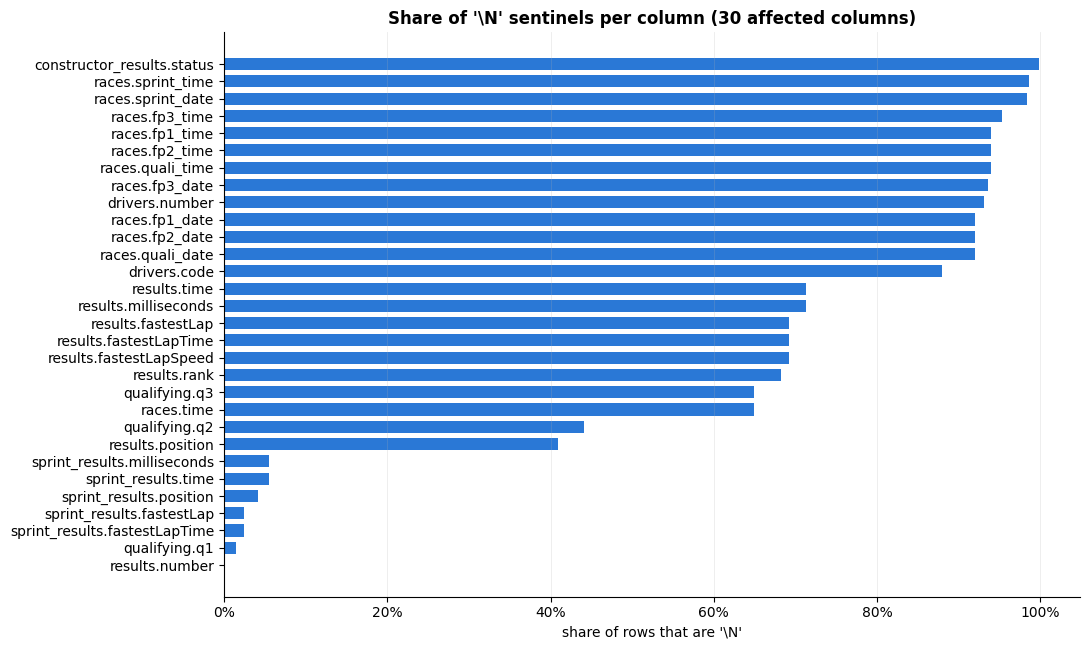

Total sentinel cells: 160076


In [4]:
rows = []
for t, df in RAW.items():
    for c in df.columns:
        n = int((df[c] == SENTINEL).sum())
        if n:
            rows.append({"column": f"{t}.{c}", "sentinel_share": n / len(df), "count": n})
sent = pd.DataFrame(rows).sort_values("sentinel_share", ascending=True)

fig, ax = plt.subplots(figsize=(11, max(4, 0.22 * len(sent))))
ax.barh(sent["column"], sent["sentinel_share"], color=BLUE, height=0.7)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title(f"Share of '\\N' sentinels per column ({len(sent)} affected columns)")
ax.set_xlabel("share of rows that are '\\N'")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("Total sentinel cells:", int(sent["count"].sum()))

**Reading the plot:** `\N` is everywhere: post-race fields (`fastestLap`, `milliseconds`, `position`),
qualifying `q2`/`q3` (knocked-out drivers) and race-weekend session dates in `races` (only recorded for recent years).
These are **not** real values, so pandas must see them as `NaN`; otherwise numeric columns stay text.

### 2.2 The sport changed shape: races per season and cars per race

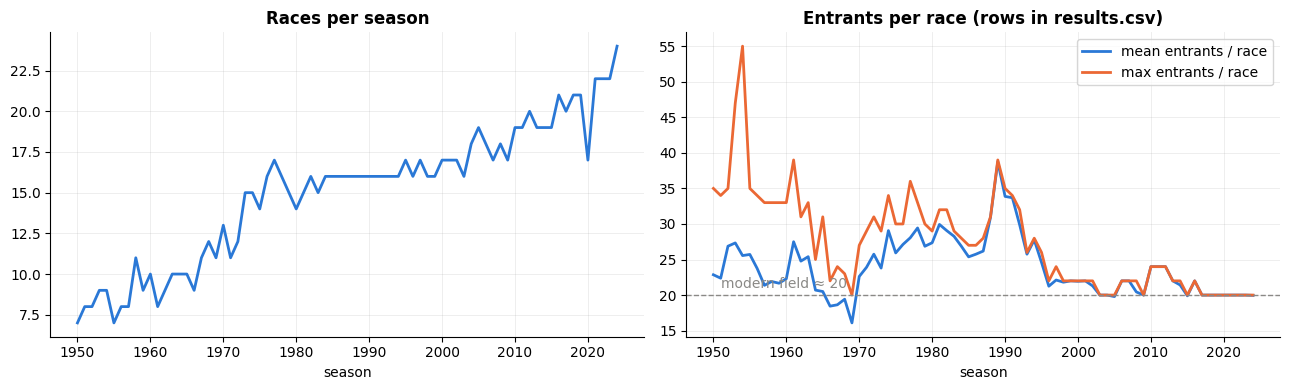

,races,mean_entrants,max_entrants
year,,,
1950,7,22.857143,35
1953,9,27.333333,47
1989,16,38.750000,39
2000,17,21.941176,22
2024,24,19.958333,20


In [5]:
per_race = raw_res.groupby(["year", "raceId"]).size().rename("entrants").reset_index()
season = per_race.groupby("year").agg(races=("raceId", "nunique"), mean_entrants=("entrants", "mean"),
                                      max_entrants=("entrants", "max"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(season.index, season["races"], color=BLUE)
axes[0].set_title("Races per season"); axes[0].set_xlabel("season")
axes[1].plot(season.index, season["mean_entrants"], color=BLUE, label="mean entrants / race")
axes[1].plot(season.index, season["max_entrants"], color=ORANGE, label="max entrants / race")
axes[1].axhline(20, color=GRAY, ls="--", lw=1); axes[1].text(1951, 21, "modern field ≈ 20", color=GRAY)
axes[1].set_title("Entrants per race (rows in results.csv)"); axes[1].set_xlabel("season"); axes[1].legend()
plt.tight_layout(); plt.show()
season.loc[[1950, 1953, 1989, 2000, 2024]]

**Reading the plot:** the calendar grew from 7 to 24 races. Rows per race peaked at 35–40 around 1989
because non-qualifiers still have a row. Those rows can never be a podium, so they dilute the class balance.

### 2.3 The target: podium rate per season (raw)

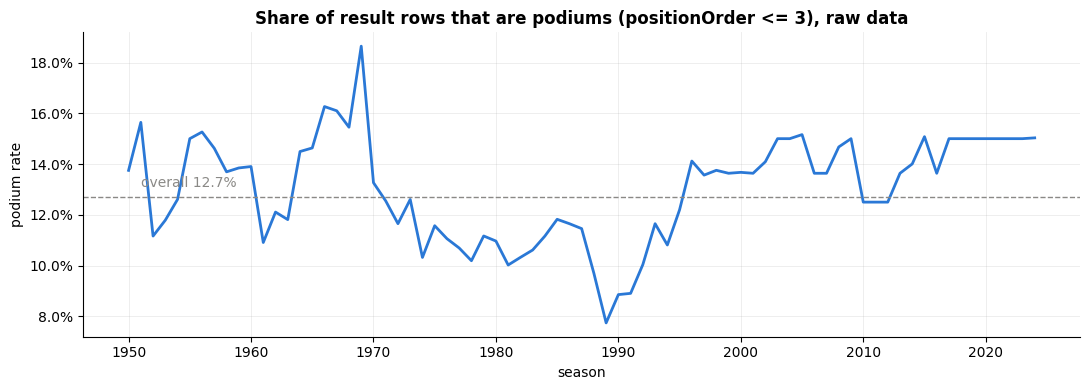

podium
no podium    23362
podium        3397
Name: count, dtype: int64


In [6]:
rate = raw_res.groupby("year")["podium"].mean()
fig, ax = plt.subplots()
ax.plot(rate.index, rate.values, color=BLUE)
ax.axhline(raw_res["podium"].mean(), color=GRAY, ls="--", lw=1)
ax.text(1951, raw_res["podium"].mean() + 0.004, f"overall {raw_res['podium'].mean():.1%}", color=GRAY)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Share of result rows that are podiums (positionOrder <= 3), raw data")
ax.set_xlabel("season"); ax.set_ylabel("podium rate")
plt.tight_layout(); plt.show()
print(raw_res["podium"].value_counts().rename({0: "no podium", 1: "podium"}))

**Reading the plot:** only **≈12.7%** of rows are podiums, so the problem is **imbalanced**.
Accuracy is therefore a misleading metric (always predicting "no" scores ≈87%), which is why we later use PR-AUC and F1.
The rate dips to ≈8% in the late 1980s, mirroring the oversized fields in 2.2.

### 2.4 Qualifying-coverage drift

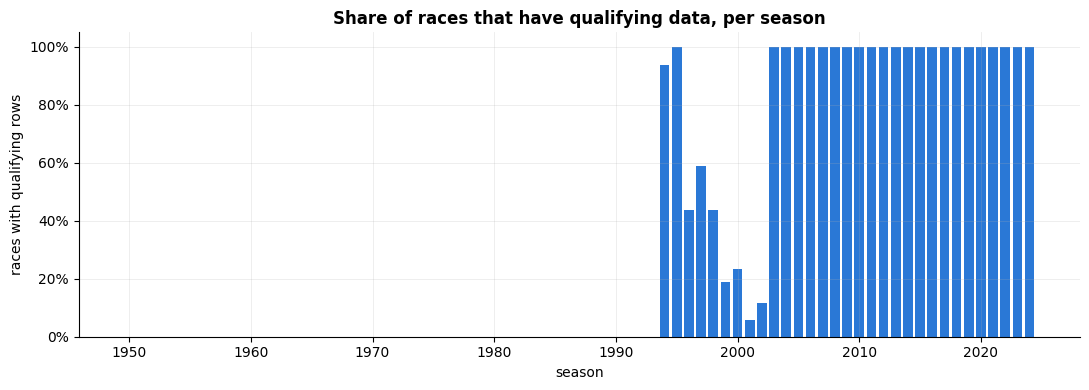

qualifying.csv starts in 1994; every race is covered continuously from 2003 onward
{1994: 0.94, 1995: 1.0, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.19, 2000: 0.24, 2001: 0.06, 2002: 0.12, 2003: 1.0, 2004: 1.0}


In [7]:
q_raw = RAW["qualifying"].assign(raceId=rnum(RAW["qualifying"]["raceId"]))
q_raw = q_raw.merge(raw_races[["raceId", "year"]], on="raceId")
races_per_year = raw_races.groupby("year")["raceId"].nunique()
q_races_per_year = q_raw.groupby("year")["raceId"].nunique().reindex(races_per_year.index, fill_value=0)
coverage = (q_races_per_year / races_per_year)

fig, ax = plt.subplots()
ax.bar(coverage.index, coverage.values, color=BLUE, width=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Share of races that have qualifying data, per season")
ax.set_xlabel("season"); ax.set_ylabel("races with qualifying rows")
plt.tight_layout(); plt.show()
first_year = int(coverage[coverage > 0].index.min())
full = coverage == 1
first_full = int(next(y for y in coverage.index if full.loc[y:].all()))   # full coverage from here to 2024
print(f"qualifying.csv starts in {first_year}; every race is covered continuously from {first_full} onward")
print(coverage.loc[1994:2004].round(2).to_dict())

**Reading the plot:** `qualifying.csv` has **nothing before 1994**. 1994–1995 are almost complete,
then coverage collapses to 6–59% of races for **1996–2002**. Every race is covered continuously from **2003**. This **historical qualifying-coverage drift**
decides how the qualifying feature is handled in Part 3 (a "no qualifying time" flag, Section 15). For older races, `grid` in `results.csv` is the only starting-order record.

### 2.5 Duplicate driver-race rows (grain violations)

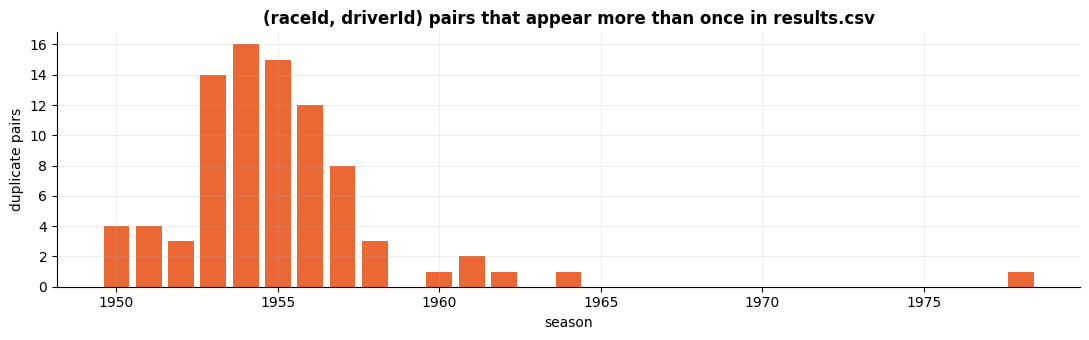

176 rows form 85 duplicate pairs; seasons 1950–1978


In [8]:
dmask = raw_res.duplicated(["raceId", "driverId"], keep=False)
dup_by_year = raw_res[dmask].groupby("year")[["raceId", "driverId"]].apply(lambda g: len(g.drop_duplicates()))
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(dup_by_year.index, dup_by_year.values, color=ORANGE, width=0.8)
ax.set_title("(raceId, driverId) pairs that appear more than once in results.csv")
ax.set_xlabel("season"); ax.set_ylabel("duplicate pairs")
plt.tight_layout(); plt.show()
print(f"{dmask.sum()} rows form {dup_by_year.sum()} duplicate pairs; seasons {dup_by_year.index.min()}–{dup_by_year.index.max()}")

**Reading the plot:** the duplicates sit almost entirely in **1950–1964**, the shared-drive era
(plus one 1978 case). The grain rule is fixed in Section 5.

### 2.6 Rows that never started the race

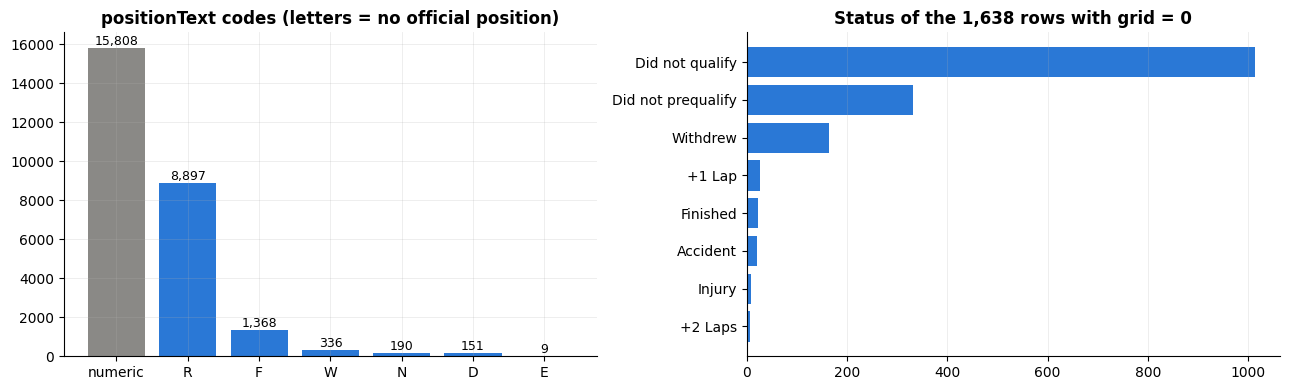

In [9]:
codes = raw_res["positionText"].where(~raw_res["positionText"].str.isdigit(), "numeric")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vc = codes.value_counts()
axes[0].bar(vc.index, vc.values, color=[GRAY if i == "numeric" else BLUE for i in vc.index])
axes[0].set_title("positionText codes (letters = no official position)")
for i, v in enumerate(vc.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

g0 = raw_res[raw_res["grid"] == 0]["status"].value_counts().head(8)[::-1]
axes[1].barh(g0.index, g0.values, color=BLUE)
axes[1].set_title(f"Status of the {int((raw_res['grid'] == 0).sum()):,} rows with grid = 0")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Reading the plots:**
- `F` (failed to qualify, ≈1.4k rows) and `W` (withdrawn) are drivers who **never took the start**.
- `grid = 0` is a **mix**. Most rows are non-starters (Did not qualify / prequalify / Withdrew),
  but some *finished* the race: those are genuine **pit-lane starts**.
- So `grid = 0` cannot be dropped blindly. We remove non-starters by their status, not by `grid`.

## 3. Cleaning: sentinels and semantic typing

**Step 3.1: sentinels.** Replace `\N` with `NaN` in every table (on a copy), then convert each column to a number
**only if every non-missing value is numeric**. This makes the conversion safe: text columns such as
`positionText = "R"` stay text and never get silently turned into `NaN`.

In [10]:
def clean_table(df):
    out = df.replace(SENTINEL, np.nan)          # new object: RAW is untouched
    for c in out.columns:
        conv = pd.to_numeric(out[c], errors="coerce")
        if conv.notna().sum() == out[c].notna().sum():          # lossless -> numeric
            if (conv.dropna() % 1 == 0).all():
                conv = conv.astype("Int64")                     # integer IDs, positions, laps
            out[c] = conv
    return out

CLEAN = {t: clean_table(df) for t, df in RAW.items()}

sentinels_after = sum(int((df == SENTINEL).sum().sum()) for df in CLEAN.values())
print("Sentinel cells before:", int(overview["sentinel_cells (\\N)"].sum()), "| after:", sentinels_after)
assert sentinels_after == 0
pd.DataFrame({"raw dtype": RAW["results"].dtypes.astype(str), "clean dtype": CLEAN["results"].dtypes.astype(str)}).T

Sentinel cells before: 160076 | after: 0


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
raw dtype,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object,object
clean dtype,Int64,Int64,Int64,Int64,Int64,Int64,Int64,object,Int64,float64,Int64,object,Int64,Int64,Int64,object,float64,Int64


**Step 3.2: text consistency.** Valid-looking text can still be inconsistent, which silently breaks grouping and matching
(e.g. the home-race question matches driver nationality to circuit country). Two checks on every text column:
- **stray whitespace:** `"Argentinian "` (trailing space) would never equal `"Argentinian"`;
- **the same entity written two ways:** the Las Vegas Strip circuit is `"United States"`, every other US circuit is `"USA"`.

In [11]:
ws_rows = []
for t, df in CLEAN.items():
    for c in df.columns:
        if df[c].dtype == object or pd.api.types.is_string_dtype(df[c]):
            stripped = df[c].str.strip()
            diff = (df[c].notna() & (stripped != df[c])).fillna(False).astype(bool)   # NaN is never "changed"
            if diff.any():
                ws_rows.append({"column": f"{t}.{c}", "cells_fixed": int(diff.sum()),
                                "example": repr(df.loc[diff, c].iloc[0])})
            df[c] = stripped

COUNTRY_FIX = {"United States": "USA"}                 # one spelling per country
n_country = int(CLEAN["circuits"]["country"].isin(COUNTRY_FIX).sum())
CLEAN["circuits"]["country"] = CLEAN["circuits"]["country"].replace(COUNTRY_FIX)

print(f"Whitespace: fixed {sum(r['cells_fixed'] for r in ws_rows)} cell(s); circuits.country renamed: {n_country}")
print("Countries now used by circuits:", sorted(CLEAN["circuits"]["country"].unique()))
pd.DataFrame(ws_rows)

Whitespace: fixed 1 cell(s); circuits.country renamed: 1
Countries now used by circuits: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA']


,column,cells_fixed,example
0,drivers.nationality,1,'Argentinian '


**Step 3.3: semantic typing.** Some values *mean* something more specific than "text":

| Raw text | Meaning | Converted to |
|---|---|---|
| `"2024-03-02"` | a date | `datetime64` |
| `"1:26.572"` (qualifying, fastest lap, lap time) | a duration *m:ss.sss* | seconds (`86.572`) |
| `"22.5"` or `"16:44.718"` (pit-stop duration) | a duration | seconds |
| `milliseconds` | race time in ms | seconds |

`results.time` is **not** parsed: for the winner it is the total time, for everyone else a *gap* (`"+1.430"`),
so mixing them would create wrong numbers. `milliseconds` holds the consistent value.

In [12]:
def to_seconds(s):
    # 'h:mm:ss.sss' / 'm:ss.sss' / 'ss.sss' -> float seconds; anything unparsable -> NaN
    if pd.isna(s):
        return np.nan
    try:
        parts = [float(p) for p in str(s).strip().split(":")]
    except ValueError:
        return np.nan
    total = 0.0
    for p in parts:
        total = total * 60 + p
    return total

# Dates
races = CLEAN["races"]
races["date"] = pd.to_datetime(races["date"], errors="coerce")
races["race_datetime"] = pd.to_datetime(races["date"].dt.strftime("%Y-%m-%d") + " " + races["time"].fillna("00:00:00"),
                                        errors="coerce")
for c in ["fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    races[c] = pd.to_datetime(races[c], errors="coerce")
CLEAN["drivers"]["dob"] = pd.to_datetime(CLEAN["drivers"]["dob"], errors="coerce")

# Durations -> seconds
q = CLEAN["qualifying"]
for c in ["q1", "q2", "q3"]:
    q[f"{c}_s"] = q[c].map(to_seconds)
for t in ["results", "sprint_results"]:
    CLEAN[t]["fastestLapTime_s"] = CLEAN[t]["fastestLapTime"].map(to_seconds)
    CLEAN[t]["race_time_s"] = CLEAN[t]["milliseconds"].astype("float") / 1000
CLEAN["results"]["fastestLapSpeed"] = CLEAN["results"]["fastestLapSpeed"].astype("float")
CLEAN["lap_times"]["lap_s"] = CLEAN["lap_times"]["time"].map(to_seconds)
CLEAN["pit_stops"]["duration_s"] = CLEAN["pit_stops"]["duration"].map(to_seconds)

# Validation: the parsed text must agree with the milliseconds column the dataset also provides
lt, ps = CLEAN["lap_times"], CLEAN["pit_stops"]
print("lap_times : max |parsed - ms/1000| =", round((lt["lap_s"] - lt["milliseconds"] / 1000).abs().max(), 4), "s")
print("pit_stops : max |parsed - ms/1000| =", round((ps["duration_s"] - ps["milliseconds"] / 1000).abs().max(), 4), "s")
print("qualifying: unparsable non-missing q1 values =", int(q["q1"].notna().sum() - q["q1_s"].notna().sum()))
races[["raceId", "year", "date", "race_datetime", "quali_date"]].tail(3)

lap_times : max |parsed - ms/1000| = 0.0 s
pit_stops : max |parsed - ms/1000| = 0.0 s
qualifying: unparsable non-missing q1 values = 0


,raceId,year,date,race_datetime,quali_date
1122,1142,2024,2024-11-23,2024-11-23 06:00:00,2024-11-22
1123,1143,2024,2024-12-01,2024-12-01 17:00:00,2024-11-30
1124,1144,2024,2024-12-08,2024-12-08 13:00:00,2024-12-07


**Why the validation matters:** the dataset stores lap and pit durations twice, as text and as milliseconds.
A max difference of **0 s** proves the parser is correct, so the same parser can be trusted on qualifying times,
which have no milliseconds column.

## 4. Key integrity

- **Primary key (PK):** the column(s) that identify a row. These must be **unique** and **non-null**.
- **Foreign key (FK):** a column pointing to another table's PK. Every value must **exist** in that table,
  or a join silently loses rows.
- We also check the **grain** of the modeling table: one `results` row per (`raceId`, `driverId`).

In [13]:
PK = {"circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
      "races": ["raceId"], "status": ["statusId"], "seasons": ["year"], "results": ["resultId"],
      "qualifying": ["qualifyId"], "sprint_results": ["resultId"], "driver_standings": ["driverStandingsId"],
      "constructor_standings": ["constructorStandingsId"], "constructor_results": ["constructorResultsId"],
      "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"]}
NATURAL = {"results": ["raceId", "driverId"]}      # the required grain

def key_report(keys, kind):
    out = []
    for t, cols in keys.items():
        df = CLEAN[t]
        nulls = int(df[cols].isna().any(axis=1).sum())
        dups = int(df.duplicated(cols).sum())
        out.append({"type": kind, "table": t, "key": "+".join(cols), "nulls": nulls, "duplicates": dups,
                    "ok": "✅" if nulls == 0 and dups == 0 else "❌"})
    return pd.DataFrame(out)

pk_table = pd.concat([key_report(PK, "primary"), key_report(NATURAL, "natural")], ignore_index=True)
pk_table

,type,table,key,nulls,duplicates,ok
0,primary,circuits,circuitId,0,0,✅
1,primary,constructors,constructorId,0,0,✅
2,primary,drivers,driverId,0,0,✅
3,primary,races,raceId,0,0,✅
4,primary,status,statusId,0,0,✅
5,primary,seasons,year,0,0,✅
6,primary,results,resultId,0,0,✅
7,primary,qualifying,qualifyId,0,0,✅
8,primary,sprint_results,resultId,0,0,✅
9,primary,driver_standings,driverStandingsId,0,0,✅


In [14]:
FK = [("results", "raceId", "races"), ("results", "driverId", "drivers"), ("results", "constructorId", "constructors"),
      ("results", "statusId", "status"), ("races", "circuitId", "circuits"), ("races", "year", "seasons"),
      ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"), ("qualifying", "constructorId", "constructors"),
      ("sprint_results", "raceId", "races"), ("sprint_results", "driverId", "drivers"),
      ("sprint_results", "constructorId", "constructors"), ("sprint_results", "statusId", "status"),
      ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
      ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
      ("constructor_results", "raceId", "races"), ("constructor_results", "constructorId", "constructors"),
      ("lap_times", "raceId", "races"), ("lap_times", "driverId", "drivers"),
      ("pit_stops", "raceId", "races"), ("pit_stops", "driverId", "drivers")]

fk_rows = []
for child, col, parent in FK:
    parent_pk = PK[parent][0]
    orphan = ~CLEAN[child][col].isin(CLEAN[parent][parent_pk]) & CLEAN[child][col].notna()
    fk_rows.append({"child.column": f"{child}.{col}", "→ parent": f"{parent}.{parent_pk}",
                    "orphans": int(orphan.sum()), "ok": "✅" if orphan.sum() == 0 else "❌"})
fk_table = pd.DataFrame(fk_rows)
print(f"FK checks passed: {(fk_table['ok'] == '✅').sum()}/{len(fk_table)}")
fk_table

FK checks passed: 23/23


,child.column,→ parent,orphans,ok
0,results.raceId,races.raceId,0,✅
1,results.driverId,drivers.driverId,0,✅
2,results.constructorId,constructors.constructorId,0,✅
3,results.statusId,status.statusId,0,✅
4,races.circuitId,circuits.circuitId,0,✅
5,races.year,seasons.year,0,✅
6,qualifying.raceId,races.raceId,0,✅
7,qualifying.driverId,drivers.driverId,0,✅
8,qualifying.constructorId,constructors.constructorId,0,✅
9,sprint_results.raceId,races.raceId,0,✅


**Result:**
- All primary keys are unique and non-null, and **all 23 foreign keys reconcile** (0 orphans), so joins are safe.
- **The one key failure is `results (raceId, driverId)`**: the shared-drive duplicates. Section 5 fixes it.

## 5. Grain fix: exactly one row per (`raceId`, `driverId`)

Each row is one prediction ("will *this driver* podium in *this race*?"), so the pair must be unique.

In [15]:
status = CLEAN["status"]; drivers = CLEAN["drivers"]
res = CLEAN["results"].merge(races[["raceId", "year", "name"]], on="raceId") \
                      .merge(status, on="statusId", how="left")
res["driver"] = res["driverId"].map(drivers.set_index("driverId")["surname"])

# A grid slot is "owned" by a driver if no OTHER driver in the same race has a row with that slot.
owners = res[res["grid"] > 0].groupby(["raceId", "grid"])["driverId"].nunique().rename("drivers_on_slot")
res = res.merge(owners, on=["raceId", "grid"], how="left")
res["own_grid_slot"] = ((res["grid"] > 0) & (res["drivers_on_slot"] == 1)).astype(int)

dup = res[res.duplicated(["raceId", "driverId"], keep=False)].sort_values(["raceId", "driverId", "grid"])
n_pairs = dup.groupby(["raceId", "driverId"]).ngroups
own_per_pair = dup.groupby(["raceId", "driverId"])["own_grid_slot"].sum().value_counts().sort_index()
print(f"{len(dup)} rows -> {n_pairs} duplicated pairs")
print("Pairs by number of rows on a grid slot the driver owns alone:", own_per_pair.to_dict())
dup[["year", "name", "driver", "constructorId", "grid", "drivers_on_slot", "positionOrder", "status"]].head(10)

176 rows -> 85 duplicated pairs
Pairs by number of rows on a grid slot the driver owns alone: {0: 31, 1: 53, 2: 1}


,year,name,driver,constructorId,grid,drivers_on_slot,positionOrder,status
13188,1978,Italian Grand Prix,Ertl,54,0,NaN,26,Did not qualify
13191,1978,Italian Grand Prix,Ertl,57,0,NaN,29,Did not prequalify
17362,1964,United States Grand Prix,Clark,172,1,2.0,7,Out of fuel
24298,1964,United States Grand Prix,Clark,172,1,2.0,12,Injection
17740,1962,British Grand Prix,Greene,172,0,NaN,22,Withdrew
17743,1962,British Grand Prix,Greene,97,0,NaN,25,Withdrew
17963,1961,British Grand Prix,Moss,172,5,1.0,21,Brakes
17961,1961,British Grand Prix,Moss,102,20,2.0,19,Disqualified
18062,1961,United States Grand Prix,Gregory,172,11,1.0,17,Gearbox
24297,1961,United States Grand Prix,Gregory,172,15,2.0,11,+8 Laps


**How shared drives are stored:** a car shared by two drivers gets **one row per driver, with the car's grid slot and its result copied**.
So when driver A takes over teammate B's car mid-race, A's extra row carries **B's grid slot**, and that slot now appears for two drivers.

We fix the grain with **two separate decisions**, one for the features and one for the label:

| Part of the row | Taken from | Why |
|---|---|---|
| **Features** (grid, constructor, …) | the car the driver **started in** | Only the starting car is known at the prediction moment. A car taken over mid-race is future information, so using its grid would be **leakage**. |
| **Label** (`podium`) | the driver's **credited result in any of his cars** that race | The label *is* the answer, so post-race information is allowed there. If the driver is officially credited with a top-3 finish, the true answer is "podium". |

**How the starting car is identified** (without using any result):
1. the row on a grid slot **he alone owns** (a taken-over car's slot is shared with its original driver);
2. if that is inconclusive (e.g. two drivers swapped cars, so both slots are shared), the **lowest `resultId`**,
   i.e. the original entry order. This is a proxy, but it uses entry order, never the race outcome.

In [16]:
def pick_started_car(df):
    # Row selection uses only own-slot evidence and entry order (resultId) - never a race outcome
    return (df.sort_values(["raceId", "driverId", "own_grid_slot", "resultId"], ascending=[True, True, False, True])
              .drop_duplicates(["raceId", "driverId"], keep="first"))

credited = res.groupby(["raceId", "driverId"])["positionOrder"].min().rename("credited_positionOrder")

# Evidence: 1957 British GP. Moss started on pole, his engine failed, he took over Brooks's car (started 3rd) and won.
ex = res[(res["year"] == 1957) & (res["name"] == "British Grand Prix") & res["driver"].isin(["Moss", "Brooks"])]
display(ex[["driver", "resultId", "grid", "drivers_on_slot", "positionOrder", "status"]].sort_values(["driver", "resultId"]))

# Compare against the naive "best finish" rule on all duplicated pairs
start = pick_started_car(res).set_index(["raceId", "driverId"])
best = res.sort_values(["raceId", "driverId", "positionOrder"]).drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"])
keys = dup.set_index(["raceId", "driverId"]).index.unique()
print("Duplicated pairs where 'best finish' would use a DIFFERENT GRID than the starting car:",
      int((start.loc[keys, "grid"] != best.loc[keys, "grid"]).sum()))
print("Duplicated pairs where the starting-car row alone would MISS a credited podium      :",
      int(((start.loc[keys, "positionOrder"] <= 3) != (credited.loc[keys] <= 3)).sum()))

res_g = pick_started_car(res).drop(columns=["drivers_on_slot"])
res_g = res_g.merge(credited, on=["raceId", "driverId"], how="left")
assert not res_g.duplicated(["raceId", "driverId"]).any()
assert len(res_g) == res[["raceId", "driverId"]].drop_duplicates().shape[0]     # no driver-race lost
moss = res_g[(res_g["year"] == 1957) & (res_g["name"] == "British Grand Prix") & (res_g["driver"] == "Moss")]
print(f"\nMoss 1957 after the fix: grid = {int(moss['grid'].iloc[0])} (his pole car), "
      f"credited position = {int(moss['credited_positionOrder'].iloc[0])} -> podium = 1")
print(f"Rows: {len(res):,} -> {len(res_g):,} (removed {len(res) - len(res_g)}) | (raceId, driverId) is now unique ✅")
print("Latest season with a duplicated pair:", int(dup["year"].max()))

,driver,resultId,grid,drivers_on_slot,positionOrder,status
18805,Brooks,18806,3,2.0,1,Finished
20290,Brooks,20293,1,2.0,12,Engine
18816,Moss,18817,1,2.0,12,Engine
20288,Moss,20291,3,2.0,1,Finished


Duplicated pairs where 'best finish' would use a DIFFERENT GRID than the starting car: 67
Duplicated pairs where the starting-car row alone would MISS a credited podium      : 17

Moss 1957 after the fix: grid = 1 (his pole car), credited position = 1 -> podium = 1
Rows: 26,759 -> 26,668 (removed 91) | (raceId, driverId) is now unique ✅
Latest season with a duplicated pair: 1978


**Result:**
- The grain is fixed: (`raceId`, `driverId`) is unique and no driver-race was lost.
- "Best finish" would have given many drivers **a teammate's grid slot**, which is mid-race information and therefore leakage.
- Taking the label from the starting car alone would have **missed officially credited podiums** (e.g. Moss's 1957 win).
  The credited label fixes this without touching the features.
- Every duplicated pair is from **1978 or earlier**. These seasons are part of the training data (Part 3 trains on 1950–2019),
  so the rule directly shapes what the models learn from the early years.

## 6. Scope decisions

### 6.1 Indianapolis 500 (1950–1960)
It counted for the championship, but it was a separate American oval race.
We test whether its drivers belong to the same population as the other Grands Prix.

In [17]:
is_indy = res_g["name"].eq("Indianapolis 500")
indy = res_g[is_indy]
gp = res_g[~is_indy]
indy_drivers = indy[["year", "driverId"]].drop_duplicates()
also_gp = indy_drivers.merge(gp[["year", "driverId"]].drop_duplicates(), on=["year", "driverId"], how="left", indicator=True)
share_cross = (also_gp["_merge"] == "both").mean()
ent = res_g.groupby(["raceId", "name", "year"]).size().rename("entrants").reset_index()
ent_50s = ent[ent["year"].between(1950, 1960)]
print(f"Indy 500 races: {indy['raceId'].nunique()} | rows: {len(indy)}")
print(f"Indy drivers who also raced any other GP that same season: {share_cross:.1%}")
print(f"Mean entrants: Indy 500 = {ent_50s[ent_50s['name'] == 'Indianapolis 500']['entrants'].mean():.0f}, "
      f"other 1950–60 GPs = {ent_50s[ent_50s['name'] != 'Indianapolis 500']['entrants'].mean():.0f}")

Indy 500 races: 11 | rows: 381
Indy drivers who also raced any other GP that same season: 0.5%
Mean entrants: Indy 500 = 35, other 1950–60 GPs = 21


**Decision: exclude the Indy 500.** Almost none of its drivers raced elsewhere that season, so it is a separate population
that would inflate American drivers' race counts and distort the home-race analysis (Question 2).
Its field structure also differs (33-car oval grid). It is 11 races out of 1,125.

### 6.2 Non-qualifiers vs cars that failed to start
Rows with 0 laps are **two different situations**, and the prediction cutoff (grid fixed, before lights out) treats them differently:

| Situation | Example | At the cutoff… | Decision |
|---|---|---|---|
| **Never qualified**: no place on the grid (did not qualify / pre-qualify / 107% rule, or withdrew without a grid slot) | 1989: 39 entries for 26 grid places | not on the grid → we would **never make this prediction** | **remove** |
| **Qualified, then did not start**: had a grid slot, but the car failed or was withdrawn before lights out | **Leclerc, Monaco 2021**: pole position, driveshaft broke on the way to the grid | on the grid → a **real prediction** whose outcome was "no podium" | **keep**, flag `did_not_start` |

Removing the second group would drop rows because of something that happened **after** the cutoff,
which makes the data look more predictable than it is (the same logic as leakage).

**Rule:**
- *failed to qualify* = 0 laps and (code `F`, or status Did not qualify / Did not prequalify / 107% Rule) → **removed**;
- *withdrawn* = 0 laps and (code `W`, or status Withdrew): **removed** if it had no grid slot (`grid = 0`),
  **kept** with `did_not_start = 1` if it had one;
- pit-lane starters (`grid = 0`, laps > 0) are **kept**.

In [18]:
QUALI_FAIL = {"Did not qualify", "Did not prequalify", "107% Rule"}
no_lap = res_g["laps"] == 0
failed_to_qualify = no_lap & (res_g["positionText"].eq("F") | res_g["status"].isin(QUALI_FAIL))
withdrawn = no_lap & (res_g["positionText"].eq("W") | res_g["status"].eq("Withdrew")) & ~failed_to_qualify
is_ns = failed_to_qualify | (withdrawn & (res_g["grid"] == 0))           # never had a grid slot -> removed
did_not_start = withdrawn & (res_g["grid"] > 0)                         # on the grid, failed to start -> kept

group = np.select([is_ns, did_not_start], ["removed: never qualified", "kept: on grid, did not start"], "kept: started")
ns_summary = res_g.assign(group=group).groupby("group").agg(
    rows=("raceId", "size"), podium_rate=("credited_positionOrder", lambda s: (s <= 3).mean()),
    mean_laps=("laps", "mean"), share_with_grid_slot=("grid", lambda s: (s > 0).mean()))
print("Kept pit-lane starters (grid=0, laps>0):", int(((res_g["grid"] == 0) & (res_g["laps"] > 0) & ~is_ns).sum()))
ex = res_g[did_not_start & (res_g["year"] >= 2021)].merge(CLEAN["drivers"][["driverId", "surname"]], on="driverId")
print("Examples kept as did_not_start (2021+):")
print(ex[["year", "name", "surname", "grid", "laps", "status"]].to_string(index=False))
ns_summary

Kept pit-lane starters (grid=0, laps>0): 72
Examples kept as did_not_start (2021+):
 year                 name surname  grid  laps     status
 2021    Monaco Grand Prix Leclerc     1     0 Driveshaft
 2021 Abu Dhabi Grand Prix Mazepin    20     0    Illness
 2023     Qatar Grand Prix   Sainz    12     0  Fuel leak
 2024   British Grand Prix   Gasly    19     0    Gearbox
 2024 São Paulo Grand Prix  Stroll    10     0   Withdrew
 2024 São Paulo Grand Prix   Albon     7     0   Withdrew


,rows,podium_rate,mean_laps,share_with_grid_slot
group,,,,
"kept: on grid, did not start",130,0.000000,0.0,1.000000
kept: started,24971,0.135958,49.278964,0.996516
removed: never qualified,1567,0.000000,0.0,0.012125


**Result:**
- The removed rows never had a grid place: **0 laps, 0% podiums**. They carry no information about our question.
- The kept `did_not_start` rows were **on the grid at prediction time**, e.g. Leclerc's pole at Monaco 2021. Their label is "no podium",
  which is exactly what happened. Keeping them makes the model's evaluation honest: in real use we would have predicted them too.
- Pit-lane starters stay in and are flagged (`pit_lane_start`).

In [19]:
base = res_g[~is_indy & ~is_ns].assign(did_not_start=did_not_start[~is_indy & ~is_ns].astype(int))
base = base.merge(races[["raceId", "round", "circuitId", "date"]], on="raceId", how="left")
base["podium"] = (base["credited_positionOrder"] <= 3).astype(int)   # credited result (see Section 5)
base["pit_lane_start"] = (base["grid"] == 0).astype(int)
assert not base.duplicated(["raceId", "driverId"]).any()
print(base.shape)

(24720, 32)


## 7. EDA after cleaning & Data Analysis

### 7.1 Row funnel

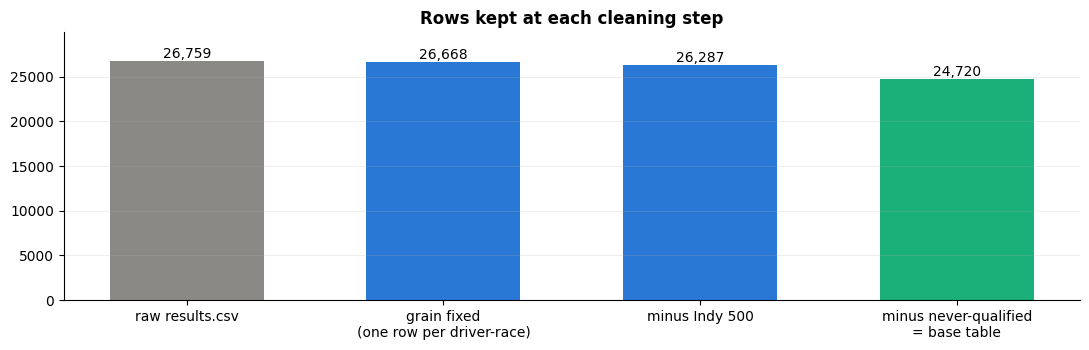

Removed 2,039 rows (7.6%)


In [20]:
funnel = pd.Series({
    "raw results.csv": len(raw_res),
    "grain fixed\n(one row per driver-race)": len(res_g),
    "minus Indy 500": int((~is_indy).sum()),
    "minus never-qualified\n= base table": len(base),
})
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(funnel.index, funnel.values, color=[GRAY, BLUE, BLUE, AQUA], width=0.6)
for i, v in enumerate(funnel.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Rows kept at each cleaning step"); ax.set_ylim(0, funnel.max() * 1.12)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"Removed {len(raw_res) - len(base):,} rows ({1 - len(base) / len(raw_res):.1%})")

### 7.2 Target balance and field size: before vs after

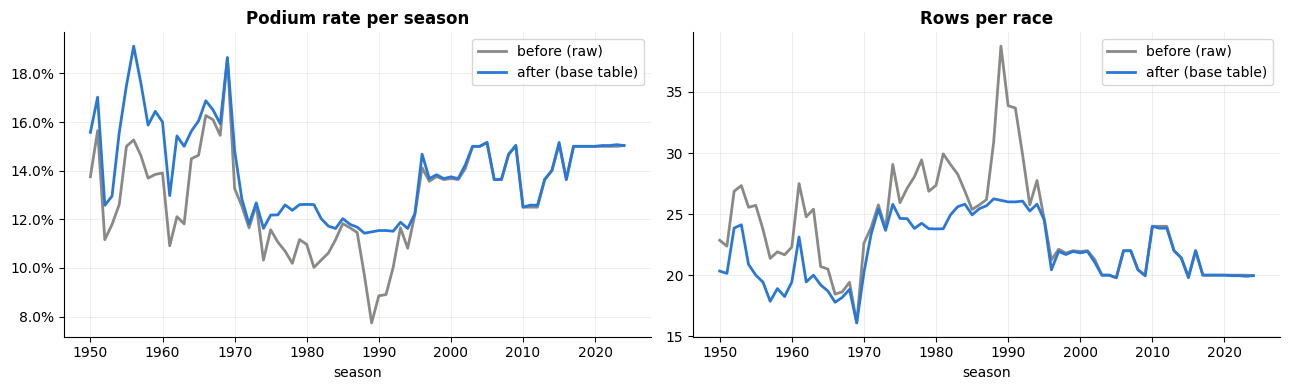

Overall podium rate: before 12.7% -> after 13.6%


In [21]:
before_rate = raw_res.groupby("year")["podium"].mean()
after_rate = base.groupby("year")["podium"].mean()
before_ent = raw_res.groupby(["year", "raceId"]).size().groupby("year").mean()
after_ent = base.groupby(["year", "raceId"]).size().groupby("year").mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(before_rate.index, before_rate.values, color=GRAY, label="before (raw)")
axes[0].plot(after_rate.index, after_rate.values, color=BLUE, label="after (base table)")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title("Podium rate per season"); axes[0].legend()
axes[1].plot(before_ent.index, before_ent.values, color=GRAY, label="before (raw)")
axes[1].plot(after_ent.index, after_ent.values, color=BLUE, label="after (base table)")
axes[1].set_title("Rows per race"); axes[1].legend()
for ax in axes: ax.set_xlabel("season")
plt.tight_layout(); plt.show()
print(f"Overall podium rate: before {raw_res['podium'].mean():.1%} -> after {base['podium'].mean():.1%}")

**Reading the plots:** removing non-qualifiers brings the late-1980s field back to ≈26 actual starters,
and the podium rate rises and becomes **much more stable across eras**. The remaining variation is real:
fewer starters in a race means each one has a better chance of a top-3 finish.

### 7.3 First look at the strongest signal: starting position

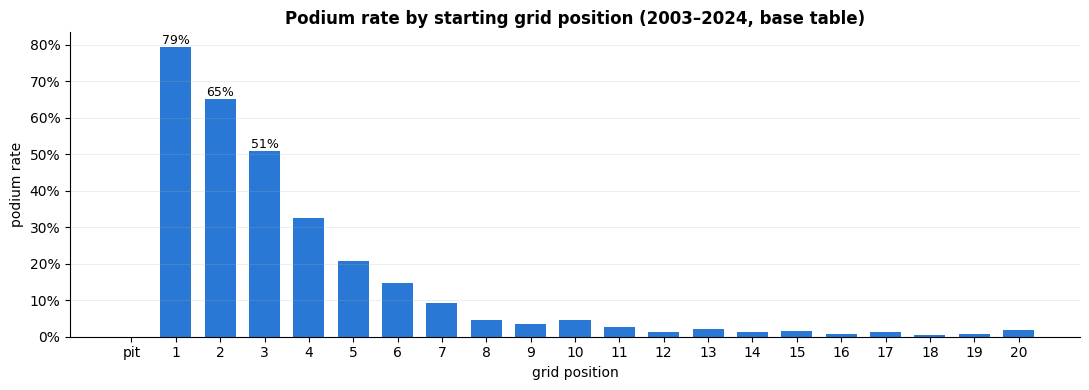

In [22]:
modern = base[base["year"] >= 2003]
by_grid = modern[modern["grid"].between(0, 20)].groupby("grid")["podium"].agg(["mean", "size"])
fig, ax = plt.subplots()
ax.bar(by_grid.index.astype(int), by_grid["mean"], color=[GRAY if g == 0 else BLUE for g in by_grid.index], width=0.7)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xticks(by_grid.index.astype(int)); ax.set_xticklabels(["pit"] + list(range(1, 21)))
ax.set_title("Podium rate by starting grid position (2003–2024, base table)")
ax.set_xlabel("grid position"); ax.set_ylabel("podium rate"); ax.grid(axis="x", visible=False)
for g in [1, 2, 3]:
    ax.text(g, by_grid.loc[g, "mean"], f"{by_grid.loc[g, 'mean']:.0%}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

**Reading the plot:** podium chance falls steeply with grid position. Pole converts to a podium about **80%** of the time,
P3 about 50%, P5 about 20%, and P10 only about 5%. This confirms `grid` as the core feature. The steep, non-linear shape matters for model choice:
the random forest and the neural network can follow any shape, and logistic regression's S-shaped curve follows a steady
decline like this one well (Section 18: the grid-only logistic regression already reaches validation PR-AUC 0.64).

### 7.4 Missing standings rows
Every driver-race should have a championship-standings row. The check below shows what a **missing** row means; the answer decides how
the standings features (Part 3) treat it.

In [23]:
ds = CLEAN["driver_standings"][["raceId", "driverId"]].assign(has_standing=1)
chk = (base.sort_values(["year", "round"])
           .assign(season_points=lambda d: d.groupby(["year", "driverId"])["points"].cumsum())
           .merge(ds, on=["raceId", "driverId"], how="left"))
gap = chk[chk["has_standing"].isna()]
print(f"Driver-races with NO standings row: {len(gap):,}; of these, the driver had 0 season points so far: "
      f"{(gap['season_points'] == 0).mean():.0%}")
print("2003–2024 gaps by season:", gap[gap["year"] >= 2003]["year"].value_counts().sort_index().to_dict())

Driver-races with NO standings row: 422; of these, the driver had 0 season points so far: 100%
2003–2024 gaps by season: {np.int64(2003): 19, np.int64(2004): 11, np.int64(2006): 12, np.int64(2007): 10, np.int64(2008): 20, np.int64(2009): 5, np.int64(2011): 2}


**Result: a missing standings row means "0 points".** In many seasons up to 2011 the standings table **omits drivers who have not scored
yet** (from 2012 it lists them). **100%** of the missing rows belong to drivers with 0 season points, so in Part 3 a missing prior-standings
value is filled with **0 points**, not treated as unknown.

## 8. Clean base table

In [24]:
BASE_COLS = ["raceId", "year", "round", "date", "circuitId", "name", "driverId", "constructorId", "grid",
             "pit_lane_start", "did_not_start", "positionOrder", "credited_positionOrder", "positionText", "points", "laps", "statusId", "status", "podium"]
base = base[BASE_COLS].sort_values(["date", "raceId", "positionOrder"]).reset_index(drop=True)
base.to_csv(os.path.join(OUT_DIR, "base_clean.csv"), index=False)
print(f"Base table: {base.shape[0]:,} rows x {base.shape[1]} cols, {base['year'].min()}–{base['year'].max()}, "
      f"podium rate {base['podium'].mean():.1%}")

Base table: 24,720 rows x 19 cols, 1950–2024, podium rate 13.6%


# Part 2: Data-engineering questions

All three questions start from the cleaned driver-race table `base` (one row per driver per race, Indy 500 excluded,
credited podium label) and add other tables through **multi-hop joins**.
Every join uses `validate=` so pandas raises an error if a join would duplicate rows.

**How we keep small numbers honest (used in all three questions):**
- every rate is shown **next to its count** (`n` = how many starts it is based on);
- groups that are too small get a **minimum-sample rule** and are not ranked;

In [25]:
def rate_table(df, by, outcome):
    # n = number of rows, k = number of 1s, rate = k / n, per group
    g = df.groupby(by, observed=True)[outcome].agg(n="size", k="sum").reset_index()
    g["rate"] = g["k"] / g["n"]
    return g

circuits = CLEAN["circuits"].copy()
constructors = CLEAN["constructors"].rename(columns={"name": "team"})
qualifying = CLEAN["qualifying"]
print("base:", base.shape, "| seasons", base["year"].min(), "–", base["year"].max())

base: (24720, 19) | seasons 1950 – 2024


## Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Join path:** `results` (via `base`) → `qualifying` (qualifying position) → `races` → `circuits`.

**Design decisions:**
- **Front row** = position 1 or 2, measured **two ways**, because penalties can move a car between qualifying and the grid:
  - by **qualifying position** (`qualifying.position`, the session result), and
  - by **grid** (`results.grid`, the actual start after penalties and, in 2021–22, sprint results).
- **Seasons 2003–2024:** qualifying coverage is complete from 2003 (Section 2.4), so the grid and qualifying versions are
  measured on exactly the same races.
- **Eras for the comparison:** **2003–2013** (pre-hybrid) vs **2014–2024** (hybrid era and after), 11 seasons each.
- A front-row car that failed to start (e.g. Leclerc's pole at Monaco 2021) **counts as a non-conversion**: at prediction time it was on the front row.

In [26]:
q1 = (base[base["year"].between(2003, 2024)]
      .merge(qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
             on=["raceId", "driverId"], how="left", validate="one_to_one")
      .merge(circuits[["circuitId", "location", "country"]], on="circuitId", how="left", validate="many_to_one"))
q1["era"] = np.where(q1["year"] >= 2014, "2014–2024", "2003–2013")
q1["front_row_grid"] = q1["grid"].isin([1, 2])
q1["front_row_quali"] = q1["quali_pos"].isin([1, 2])
label = q1.drop_duplicates("circuitId").set_index("circuitId")["location"]
print(f"Rows: {len(q1):,} | missing qualifying position: {q1['quali_pos'].isna().sum()} rows "
      f"({q1['quali_pos'].isna().mean():.2%}) -> excluded from the qualifying version only")

# How often do the two definitions disagree?
cross = pd.crosstab(q1["front_row_quali"], q1["front_row_grid"]).rename_axis(
    index="front row in QUALIFYING", columns="front row on the GRID")
print(f"\nQualified on the front row but did NOT start there: {cross.loc[True, False]} of {cross.loc[True].sum()}"
      f" ({cross.loc[True, False] / cross.loc[True].sum():.1%})")
print(f"Started on the front row WITHOUT qualifying there : {cross.loc[False, True]} of {cross[True].sum()}")
cross

Rows: 8,957 | missing qualifying position: 22 rows (0.25%) -> excluded from the qualifying version only

Qualified on the front row but did NOT start there: 37 of 855 (4.3%)
Started on the front row WITHOUT qualifying there : 36 of 854


front row on the GRID,False,True
front row in QUALIFYING,,
False,8066,36
True,37,818


### Step 1: which circuits convert best overall (2003–2024)?
For each circuit: **conversion = podiums ÷ front-row starts**. A circuit needs **≥ 16 front-row starts (≈ 8 races)** to be ranked;
at a circuit visited twice, one race changes the rate by 50 points.

Circuits ranked: 24 | average conversion 2003–2024: 72.2% (grid), 70.8% (qualifying)


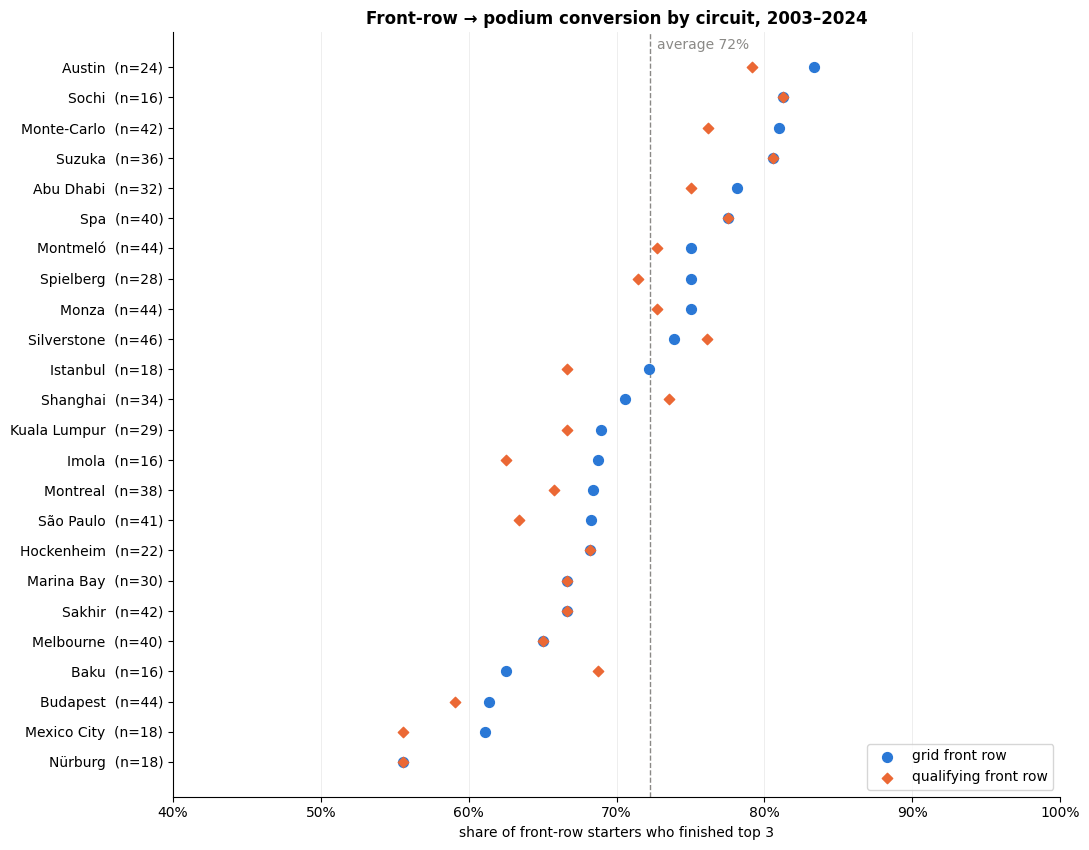

circuit,n,k,rate,rate_quali,rank_grid,rank_quali
Austin,24,20,83%,79%,1,3
Sochi,16,13,81%,81%,2,1
Monte-Carlo,42,34,81%,76%,3,5
Suzuka,36,29,81%,81%,4,2
Abu Dhabi,32,25,78%,75%,5,7
Spa,40,31,78%,78%,6,4
Monza,44,33,75%,73%,7,9
Montmeló,44,33,75%,73%,7,9
Spielberg,28,21,75%,71%,7,11
Silverstone,46,34,74%,76%,10,6


In [27]:
MIN_TOTAL = 16
avg = q1.loc[q1["front_row_grid"], "podium"].mean()
avg_q = q1.loc[q1["front_row_quali"], "podium"].mean()

tabs = {}
for flag, name in [("front_row_grid", "grid"), ("front_row_quali", "qualifying")]:
    t = rate_table(q1[q1[flag]], "circuitId", "podium").set_index("circuitId")
    tabs[name] = t[t["n"] >= MIN_TOTAL]
ov = tabs["grid"].join(tabs["qualifying"][["n", "rate"]], rsuffix="_quali", how="outer")
ov.insert(0, "circuit", ov.index.map(label))
ov["rank_grid"] = ov["rate"].rank(ascending=False, method="min")
ov["rank_quali"] = ov["rate_quali"].rank(ascending=False, method="min")
ov = ov.sort_values("rate", ascending=False)
print(f"Circuits ranked: {ov['rate'].notna().sum()} | average conversion 2003–2024: {avg:.1%} (grid), {avg_q:.1%} (qualifying)")

t = ov.dropna(subset=["rate"]).sort_values("rate")
fig, ax = plt.subplots(figsize=(11, 0.3 * len(t) + 1.4))
yy = np.arange(len(t))
ax.scatter(t["rate"], yy, color=BLUE, s=50, zorder=3, label="grid front row")
ax.scatter(t["rate_quali"], yy, color=ORANGE, s=28, marker="D", zorder=4, label="qualifying front row")
ax.axvline(avg, color=GRAY, ls="--", lw=1); ax.text(avg + 0.005, len(t) - 0.4, f"average {avg:.0%}", color=GRAY)
ax.set_yticks(yy); ax.set_yticklabels([f"{c}  (n={int(n)})" for c, n in zip(t["circuit"], t["n"])])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0.4, 1.0)
ax.set_title("Front-row → podium conversion by circuit, 2003–2024")
ax.set_xlabel("share of front-row starters who finished top 3"); ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
ov[["circuit", "n", "k", "rate", "rate_quali", "rank_grid", "rank_quali"]].style.format(
    {"rate": "{:.0%}", "rate_quali": "{:.0%}", "rank_grid": "{:.0f}", "rank_quali": "{:.0f}"}
).hide(axis="index")

**Reading the plot:** each blue dot is one circuit's conversion rate using the grid definition, the orange diamond the same rate using
qualifying position, and the dashed line the average over all front-row starters. `n` is the number of front-row starts behind each rate.

### Step 2: does the ranking change after 2014?
Each circuit is ranked **separately in each era**. To be ranked here a circuit needs **≥ 8 front-row starts (≈ 4 races) in each era**.
To measure how much the ranking moved we use two simple numbers: the **average number of places** a circuit moved, and **how many of the
top 5 stayed in the top 5**.

In [28]:
MIN_STARTS = 8

def circuit_ranking(flag):
    t = rate_table(q1[q1[flag]], ["circuitId", "era"], "podium")
    wide = t.pivot(index="circuitId", columns="era", values=["n", "rate"])
    eligible = wide[(wide[("n", "2003–2013")] >= MIN_STARTS) & (wide[("n", "2014–2024")] >= MIN_STARTS)]
    out = pd.DataFrame({
        "circuit": eligible.index.map(label),
        "starts_03_13": eligible[("n", "2003–2013")].astype(int), "rate_03_13": eligible[("rate", "2003–2013")],
        "starts_14_24": eligible[("n", "2014–2024")].astype(int), "rate_14_24": eligible[("rate", "2014–2024")],
    }, index=eligible.index)
    out["rank_03_13"] = out["rate_03_13"].rank(ascending=False, method="min").astype(int)
    out["rank_14_24"] = out["rate_14_24"].rank(ascending=False, method="min").astype(int)
    out["rank_change"] = out["rank_03_13"] - out["rank_14_24"]       # positive = moved up after 2014
    return out.sort_values("rate_14_24", ascending=False)

rank_grid = circuit_ranking("front_row_grid")
rank_quali = circuit_ranking("front_row_quali")
top5_before = set(rank_grid.nsmallest(5, "rank_03_13")["circuit"]); top5_after = set(rank_grid.nsmallest(5, "rank_14_24")["circuit"])
up = int((rank_grid["rate_14_24"] > rank_grid["rate_03_13"]).sum()); down = int((rank_grid["rate_14_24"] < rank_grid["rate_03_13"]).sum())
common = rank_grid.index.intersection(rank_quali.index)
def_diff = (rank_grid.loc[common, "rank_14_24"] - rank_quali.loc[common, "rank_14_24"]).abs()

print(f"Circuits with >= {MIN_STARTS} front-row starts in BOTH eras: {len(rank_grid)} (grid), {len(rank_quali)} (qualifying)")
print(f"Conversion higher after 2014 at {up} of {len(rank_grid)} circuits (lower at {down})")
print(f"Average move between eras: {rank_grid['rank_change'].abs().mean():.1f} places (out of {len(rank_grid)})")
print(f"Top 5 that stayed top 5: {len(top5_before & top5_after)} of 5 -> {sorted(top5_before & top5_after)}")
print(f"Grid vs qualifying ranking (2014–24): average difference {def_diff.mean():.1f} places; "
      f"{int((def_diff == 0).sum())} of {len(common)} circuits have exactly the same rank")
rank_grid.style.format({"rate_03_13": "{:.0%}", "rate_14_24": "{:.0%}", "rank_change": "{:+d}"}).hide(axis="index")

Circuits with >= 8 front-row starts in BOTH eras: 16 (grid), 17 (qualifying)
Conversion higher after 2014 at 12 of 16 circuits (lower at 3)
Average move between eras: 4.8 places (out of 16)
Top 5 that stayed top 5: 3 of 5 -> ['Monte-Carlo', 'Spa', 'Suzuka']
Grid vs qualifying ranking (2014–24): average difference 1.8 places; 3 of 16 circuits have exactly the same rank


circuit,starts_03_13,rate_03_13,starts_14_24,rate_14_24,rank_03_13,rank_14_24,rank_change
Suzuka,18,72%,18,89%,4,1,+3
Abu Dhabi,10,60%,22,86%,12,2,+10
Monte-Carlo,22,77%,20,85%,1,3,-2
Montmeló,22,68%,22,82%,7,4,+3
Spa,18,72%,22,82%,4,4,+0
São Paulo,22,59%,19,79%,14,6,+8
Shanghai,20,65%,14,79%,9,7,+2
Montreal,20,60%,18,78%,12,8,+4
Silverstone,22,73%,24,75%,3,9,-6
Imola,8,62%,8,75%,11,9,+2


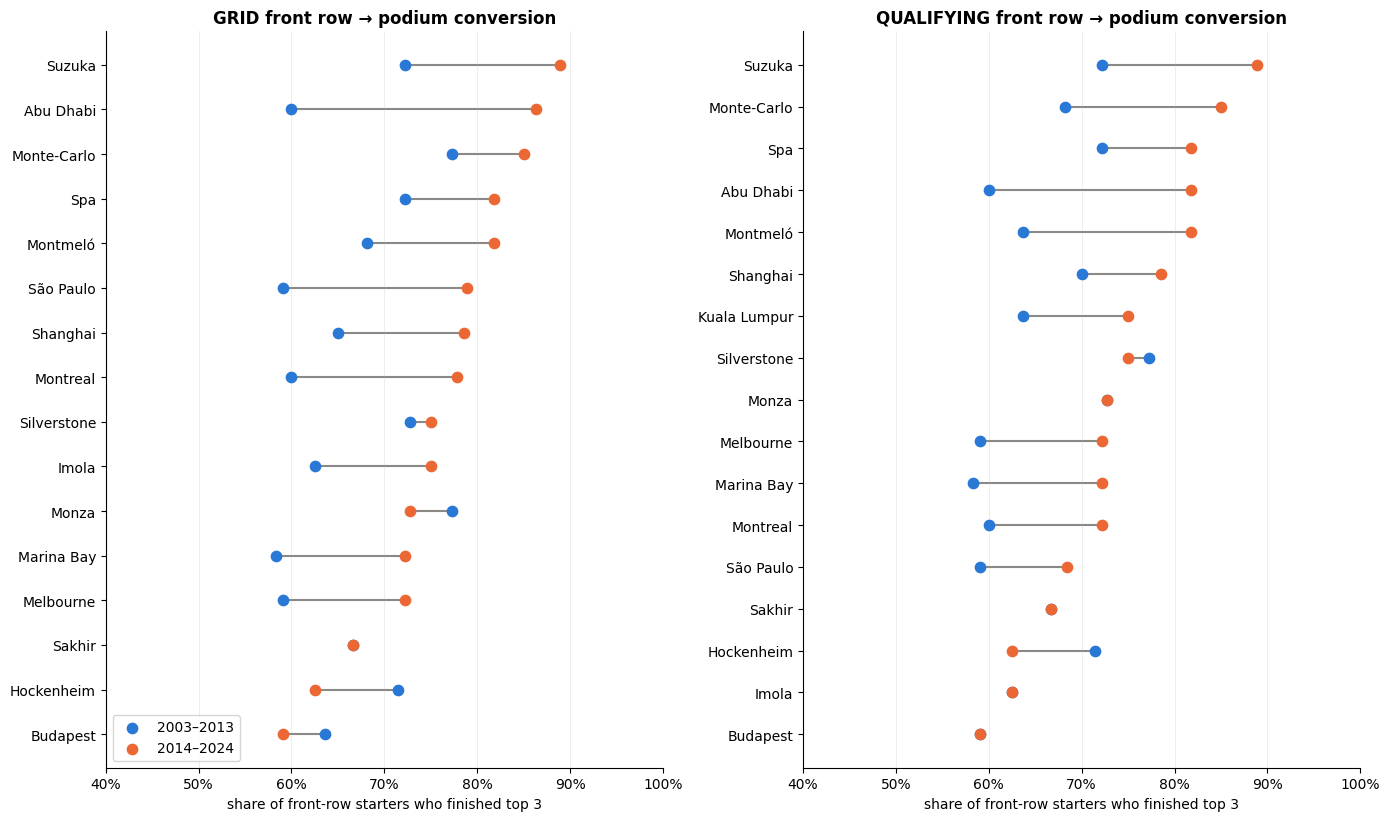

Top 3, 2003–2013 (grid): Monte-Carlo (77%), Monza (77%), Silverstone (73%)
Top 3, 2014–2024 (grid): Suzuka (89%), Abu Dhabi (86%), Monte-Carlo (85%)
Biggest rank moves     : Abu Dhabi (12 -> 2), Monza (1 -> 11), Hockenheim (6 -> 15)
Top 3 by qualifying definition (2014–24): Suzuka (89%), Monte-Carlo (85%), Abu Dhabi (82%)


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(rank_grid) + 1.6), sharey=False)
for ax, (tbl, title) in zip(axes, [(rank_grid, "GRID front row"), (rank_quali, "QUALIFYING front row")]):
    t = tbl.sort_values("rate_14_24")
    y = np.arange(len(t))
    ax.hlines(y, t["rate_03_13"], t["rate_14_24"], color=GRAY, lw=1.5, zorder=1)
    ax.scatter(t["rate_03_13"], y, color=BLUE, s=55, label="2003–2013", zorder=2)
    ax.scatter(t["rate_14_24"], y, color=ORANGE, s=55, label="2014–2024", zorder=3)
    ax.set_yticks(y); ax.set_yticklabels(t["circuit"])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0.4, 1.0)
    ax.set_title(f"{title} → podium conversion"); ax.set_xlabel("share of front-row starters who finished top 3")
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

top = lambda t, col: ", ".join(f"{r.circuit} ({getattr(r, col):.0%})" for r in t.sort_values(col, ascending=False).head(3).itertuples())
movers = rank_grid.reindex(rank_grid["rank_change"].abs().sort_values(ascending=False).index).head(3)
print("Top 3, 2003–2013 (grid):", top(rank_grid, "rate_03_13"))
print("Top 3, 2014–2024 (grid):", top(rank_grid, "rate_14_24"))
print("Biggest rank moves     :", ", ".join(f"{r.circuit} ({r.rank_03_13} -> {r.rank_14_24})" for r in movers.itertuples()))
print("Top 3 by qualifying definition (2014–24):", top(rank_quali, "rate_14_24"))

**How to read the dumbbells:** each line is one circuit. The blue dot is its 2003–2013 conversion rate, the orange dot its 2014–2024 rate.
A long line means the circuit behaved very differently in the two eras; orange to the right of blue means it converted more often after 2014.

### Q1 answer
**Part A: which circuits convert best? (2003–2024 combined)**
- On average, **72.2%** of front-row starters finished on the podium (70.8% by the qualifying definition): about 7 in 10.
- **Highest:** Austin (83%, 20 of 24), Sochi (81%, 13 of 16), Monaco (81%, 34 of 42), Suzuka (81%, 29 of 36).
  **Lowest:** Nürburgring (56%, 10 of 18), Mexico City (61%), Budapest (61%).
- With only 16–46 front-row starts per circuit, a gap of a few points between two circuits is a difference of one or two races.

**Part B: does the ranking change after 2014? Yes, a lot.**

| Rank | 2003–2013 | 2014–2024 |
|---|---|---|
| 1 | Monaco (77%) **(tie)** | Suzuka (89%) |
| 1 / 2 | Monza (77%) **(tie, shares 1st)** | Abu Dhabi (86%) |
| 3 | Silverstone (73%) | Monaco (85%) |

- On average a circuit moved **4.8 places** (out of 16) between the eras, and only **3 of the top 5** stayed in the top 5 (Monaco, Spa, Suzuka).
- Biggest moves: **Abu Dhabi 12th → 2nd**, **Monza 1st → 11th**, **Hockenheim 6th → 15th**.
- Conversion was higher after 2014 at **12 of the 16** circuits.
- **Monaco is the only circuit in the top 3 of both eras**, consistent with it being the hardest track to overtake on.
- Caution: each circuit has only 8–24 front-row starts per era, so part of the reshuffle is small-sample noise.

**Part C: qualifying vs grid**
- **37 of 855 (4.3%)** front-row qualifiers did *not* start from the front row (grid penalties; in 2021–22 the sprint set the grid),
  and 36 drivers started on the front row without qualifying there.
- The two rankings are close (on average **1.8 places** apart in 2014–2024) and share the same top 3 (Suzuka, Monaco, Abu Dhabi).
- Conversion is a little **lower by the qualifying definition** (70.8% vs 72.2%), because front-row qualifiers who were then moved back
  by a penalty podiumed less often. So **`grid`, not qualifying position alone, is the better model feature**: it already contains the penalty.

**Grain / missingness / cutoff:**
- Grain: one row per driver-race; a circuit's rate = podiums ÷ front-row starters at that circuit.
  A front-row car that failed to start (e.g. Leclerc's pole at Monaco 2021) counts as a non-conversion.
- Missingness: 22 rows (0.25%) of 2003–2024 have no qualifying position; they are dropped from the qualifying version only.
- Cutoff: grid and qualifying position are both known **before** the race, so both are legitimate features.

## Q2. Do drivers podium more often at home, after controlling for starting position?

**Join path:** `results` (via `base`) → `drivers` (nationality) → `races` → `circuits` (country).

**The hidden problem: the two tables use different words.**
`drivers.nationality` says *"British"*, while `circuits.country` says *"UK"*. There is no key linking them,
so we build an explicit, documented **nationality → country map**. Building it exposed two text problems
(a trailing space in `"Argentinian "` and `"United States"` vs `"USA"`); they are fixed upstream in **Section 3.2**,
and the cell below asserts they are gone, so every later step (including the `home_race` feature) gets clean text.

**Controlling for starting position:** home drivers might start further forward or further back than away drivers,
and starting position decides most podiums. So we compare home and away **only among drivers who started in the same grid group**.

In [30]:
NAT_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Argentinian": "Argentina", "Australian": "Australia",
    "Austrian": "Austria", "Belgian": "Belgium", "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chilean": "Chile", "Chinese": "China", "Colombian": "Colombia", "Czech": "Czech Republic", "Danish": "Denmark",
    "Dutch": "Netherlands", "East German": "Germany", "Finnish": "Finland", "French": "France", "German": "Germany",
    "Hungarian": "Hungary", "Indian": "India", "Indonesian": "Indonesia", "Irish": "Ireland", "Italian": "Italy",
    "Japanese": "Japan", "Liechtensteiner": "Liechtenstein", "Malaysian": "Malaysia", "Mexican": "Mexico",
    "Monegasque": "Monaco", "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal",
    "Rhodesian": "Zimbabwe", "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain",
    "Swedish": "Sweden", "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
DUAL = {"American-Italian", "Argentine-Italian"}     # no single home country: excluded rather than guessed
drv = CLEAN["drivers"][["driverId", "nationality", "surname"]].copy()
circ = circuits[["circuitId", "country"]].copy()
assert (drv["nationality"] == drv["nationality"].str.strip()).all(), "run Section 3.2 first"
assert not circ["country"].eq("United States").any(), "run Section 3.2 first"
unmapped = set(drv["nationality"]) - set(NAT_TO_COUNTRY) - DUAL
assert not unmapped, f"Nationalities without a decision: {unmapped}"
drv["home_country"] = drv["nationality"].map(NAT_TO_COUNTRY)
print(f"Every one of the {drv['nationality'].nunique()} nationality labels has a decision "
      f"({len(DUAL)} dual nationalities excluded)")

q2 = (base.merge(drv, on="driverId", how="left", validate="many_to_one")
          .merge(circ, on="circuitId", how="left", validate="many_to_one"))
dual_rows = int(q2["nationality"].isin(DUAL).sum())
q2 = q2[~q2["nationality"].isin(DUAL)].copy()
q2["home"] = (q2["home_country"] == q2["country"]).astype(int)

bins, labels = [-1, 1, 2, 3, 6, 10, 99], ["P1", "P2", "P3", "P4–6", "P7–10", "P11+ / pit"]
q2["grid_group"] = pd.cut(q2["grid"].replace(0, 99), bins=bins, labels=labels)      # pit-lane start = back of grid
share_back = q2.groupby("home")["grid_group"].apply(lambda g: (g == "P11+ / pit").mean())
print(f"Rows: {len(q2):,} (excluded {dual_rows} dual-nationality rows) | home rows: {q2['home'].sum():,} "
      f"({q2['home'].mean():.1%}) | seasons {q2['year'].min()}–{q2['year'].max()}")
print("Home-race rows by driver nationality (top 6):",
      q2[q2["home"] == 1]["nationality"].value_counts().head(6).to_dict())
print(f"Share of starts from P11+ / pit lane: home {share_back[1]:.1%} vs away {share_back[0]:.1%}")

Every one of the 43 nationality labels has a decision (2 dual nationalities excluded)
Rows: 24,717 (excluded 3 dual-nationality rows) | home rows: 1,944 (7.9%) | seasons 1950–2024
Home-race rows by driver nationality (top 6): {'British': 451, 'Italian': 403, 'French': 207, 'German': 200, 'Brazilian': 114, 'American': 112}
Share of starts from P11+ / pit lane: home 59.2% vs away 54.6%


### Step 1: compare home and away inside each grid group
The groups are finer at the front, where every place changes the podium
chance a lot (Section 7.3: P1 ≈ 80%, P2 ≈ 65%, P3 ≈ 50%), and wider at the back, where the chance is close to zero anyway.

In [31]:
strata = rate_table(q2, ["grid_group", "home"], "podium")
strata["where"] = strata["home"].map({1: "home", 0: "away"})
wide = strata.pivot(index="grid_group", columns="where", values=["n", "k", "rate"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide["difference_pts"] = 100 * (wide["rate_home"] - wide["rate_away"])
wide["difference_in_podiums"] = wide["k_home"] - wide["rate_away"] * wide["n_home"]
raw = q2.groupby("home")["podium"].mean()
print(f"Raw podium rate (NO control): home {raw[1]:.1%} vs away {raw[0]:.1%}")
print(f"Grid groups where home is higher: {int((wide['difference_pts'] > 0).sum())} of {len(wide)}; lower: {int((wide['difference_pts'] < 0).sum())}")
wide[["n_home", "rate_home", "n_away", "rate_away", "difference_pts", "difference_in_podiums"]].style.format(
    {"rate_home": "{:.1%}", "rate_away": "{:.1%}", "difference_pts": "{:+.1f}", "difference_in_podiums": "{:+.1f}",
     "n_home": "{:,.0f}", "n_away": "{:,.0f}"})

Raw podium rate (NO control): home 11.8% vs away 13.7%
Grid groups where home is higher: 3 of 6; lower: 3


,n_home,rate_home,n_away,rate_away,difference_pts,difference_in_podiums
grid_group,,,,,,
P1,82,62.2%,"1,034",64.8%,-2.6,-2.1
P2,78,56.4%,"1,034",56.2%,+0.2,+0.2
P3,71,53.5%,"1,045",45.8%,+7.7,+5.5
P4–6,227,26.9%,"3,115",26.1%,+0.8,+1.8
P7–10,336,7.1%,"4,117",9.2%,-2.1,-7.0
P11+ / pit,"1,150",1.0%,"12,428",1.7%,-0.6,-7.2


### Step 2: one combined answer
*If home drivers had podiumed at the **away** rate of their own grid group, how many podiums would they
have had?* We compare that with how many they **actually** had: actual > expected would mean a home advantage; actual ≈ expected means none.

Home starts: 1,944 | expected podiums at the away rate of their grid group: 238.8 | actual: 230 | difference: -8.8 (-0.46 points per 100 starts)


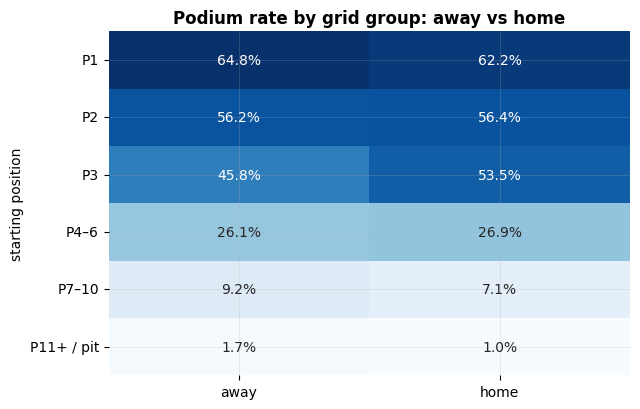

In [32]:
away_rate = q2[q2["home"] == 0].groupby("grid_group", observed=True)["podium"].mean()
home_rows = q2[q2["home"] == 1]
expected = home_rows["grid_group"].map(away_rate).astype(float).sum()
actual = int(home_rows["podium"].sum())
print(f"Home starts: {len(home_rows):,} | expected podiums at the away rate of their grid group: {expected:.1f} | "
      f"actual: {actual} | difference: {actual - expected:+.1f} ({100 * (actual - expected) / len(home_rows):+.2f} points per 100 starts)")

pivot = pd.pivot_table(q2, index="grid_group", columns="home", values="podium", aggfunc="mean", observed=True)
pivot.columns = ["away", "home"]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.heatmap(pivot, annot=True, fmt=".1%", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Podium rate by grid group: away vs home"); ax.set_ylabel("starting position"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**How to read it:** a **pivot table shown as a heatmap**: rows are starting groups, columns are away/home, each cell
is the podium rate. If racing at home helped, the *home* column would be higher in every row.

### Q2 answer
**No: after controlling for starting position, drivers do not podium more often at home.**

1. **Raw comparison (no control):** home drivers podium *less*: **11.8% at home vs 13.7% away**.
   The main reason is where they start: **59.2%** of home starts are from P11 or further back, vs **54.6%** of away starts.
2. **Inside each grid group** home and away are close: P1 62% vs 65%, P2 56% vs 56%, P4–6 27% vs 26%.
   Home is higher in **3** groups and lower in **3**, so there is no consistent pattern.
   The biggest gap, P3 (+7.7 points), is only **about 5 podiums out of 71 home starts**.
3. **Combined:** at the away rate of their own grid groups, home drivers would have scored **238.8** podiums; they scored **230**
   (**−8.8**, i.e. −0.46 points per 100 starts, against −1.9 points without the control). So **starting position explains most of the raw gap**.

**Interpretation:** this is an **association, not proof of cause**: nationality is only a proxy for "home", and grid groups do not capture
everything (car strength, weather).

**Grain / missingness / cutoff:**
- Grain: one row per driver-race; 1950–2024 starters, Indy 500 excluded (Section 6.1 showed it would distort US home races).
- Missingness: every nationality has an explicit decision (text cleaned in Section 3.2);
  3 dual-nationality rows are excluded rather than assigned an arbitrary country.
- Cutoff: nationality and circuit country are known long before the race, so `home` is a legitimate pre-race feature.

## Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Join path:** `results` (via `base`) → `status` (why the race ended) → `races` (season) → `constructors` (team name).

**Definition:** a mechanical retirement is a **race start** that ended early **because a car component failed**,
excluding crashes, driver causes and regulatory decisions.

### Step 1: classify all 139 status values
`status.csv` is free text, so we map **every** value to one category.
An `assert` stops the notebook if a status is ever left unmapped. Some causes cannot be judged from the label alone
(a *puncture* may be debris or contact; *Retired* gives no reason; a loose *wheel* is usually a pit-stop error), so they get their own
**ambiguous** category instead of a silent guess.

In [33]:
MECHANICAL = {
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes",
    "Differential", "Overheating", "Mechanical", "Driveshaft", "Fuel pressure", "Water pressure", "Throttle", "Steering",
    "Technical", "Electronics", "Heat shield fire", "Exhaust", "Oil leak", "Wheel rim", "Water leak", "Fuel pump",
    "Track rod", "Oil pressure", "Engine fire", "Engine misfire", "Pneumatics", "Handling", "Fire", "Wheel bearing",
    "Fuel system", "Oil line", "Launch control", "Fuel", "Power loss", "Vibrations", "Drivetrain", "Ignition", "Chassis",
    "Battery", "Halfshaft", "Crankshaft", "Alternator", "Oil pump", "Fuel leak", "Injection", "Distributor", "Turbo",
    "CV joint", "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto", "Supercharger",
    "Power Unit", "ERS", "Brake duct", "Undertray", "Cooling system", "Driver Seat", "Seat", "Safety belt"}
AMBIGUOUS = {"Retired", "Puncture", "Tyre puncture", "Tyre", "Wheel", "Wheel nut", "Front wing", "Rear wing", "Broken wing",
             "Out of fuel", "Refuelling", "Fuel rig", "Damage", "Debris", "Stalled", "Not classified"}
ACCIDENT_DRIVER = {"Accident", "Collision", "Collision damage", "Spun off", "Fatal accident", "Physical", "Injured",
                   "Injury", "Eye injury", "Illness", "Driver unwell"}
REGULATORY_OTHER = {"Disqualified", "Excluded", "Underweight", "Safety concerns", "Safety", "Not restarted", "Withdrew",
                    "107% Rule", "Did not qualify", "Did not prequalify"}

def status_category(s):
    if s == "Finished" or (s.startswith("+") and "Lap" in s):
        return "finished"
    for name, group in [("mechanical", MECHANICAL), ("ambiguous", AMBIGUOUS),
                        ("accident/driver", ACCIDENT_DRIVER), ("regulatory/other", REGULATORY_OTHER)]:
        if s in group:
            return name
    return None

status_cat = CLEAN["status"].assign(category=lambda d: d["status"].map(status_category))
assert status_cat["category"].notna().all(), f"Unmapped: {status_cat[status_cat['category'].isna()]['status'].tolist()}"
print("All", len(status_cat), "status values classified:", status_cat["category"].value_counts().to_dict())

All 139 status values classified: {'mechanical': 68, 'finished': 34, 'ambiguous': 16, 'accident/driver': 11, 'regulatory/other': 10}


In [34]:
# A "race start" excludes cars that were on the grid but never took the start (did_not_start, Section 6.2)
q3 = (base[base["year"].between(2014, 2024) & base["did_not_start"].eq(0)]
      .merge(status_cat[["statusId", "category"]], on="statusId", how="left", validate="many_to_one")
      .merge(constructors[["constructorId", "team"]], on="constructorId", how="left", validate="many_to_one"))
q3["era"] = np.where(q3["year"] <= 2021, "2014–2021", "2022–2024")
q3["mech"] = q3["category"].eq("mechanical").astype(int)
print(f"Race starts 2014–2024: {len(q3):,} (excluded {int(base[base['year'].between(2014, 2024)]['did_not_start'].sum())} "
      "cars that were on the grid but did not start; pit-lane starts are included)")

Race starts 2014–2024: 4,598 (excluded 22 cars that were on the grid but did not start; pit-lane starts are included)


### Step 2: rate per constructor
Rate = mechanical retirements ÷ race starts.

Teams are shown **as recorded** (`constructorId`). In the dataset a renamed team gets a new `constructorId`, so its history starts again
(e.g. *Toro Rosso → AlphaTauri → RB*), so a team that changed name has separate entries. A constructor needs
**≥ 30 starts** in an era (about one season) to be ranked; below that, one breakdown moves its rate by more than 3 points.

In [35]:
MIN_TEAM_STARTS = 30
team_rates = rate_table(q3, ["era", "team"], "mech").rename(columns={"n": "starts", "k": "mech_retirements"})
team_rates["ranked"] = team_rates["starts"] >= MIN_TEAM_STARTS
team_rates["rank"] = team_rates[team_rates["ranked"]].groupby("era")["rate"].rank(ascending=False, method="min")

for era in ["2014–2021", "2022–2024"]:
    t = team_rates[team_rates["era"] == era].sort_values(["ranked", "rate"], ascending=[False, False])
    print(f"\n=== {era} ===")
    display(t[["team", "starts", "mech_retirements", "rate", "rank"]]
            .style.format({"rate": "{:.1%}", "rank": "{:.0f}"}, na_rep="(too few starts)").hide(axis="index"))


=== 2014–2021 ===


team,starts,mech_retirements,rate,rank
Caterham,33,7,21.2%,1
Lotus F1,75,13,17.3%,2
Toro Rosso,242,39,16.1%,3
Renault,199,26,13.1%,4
McLaren,316,41,13.0%,5
Red Bull,318,34,10.7%,6
Sauber,199,21,10.6%,7
Marussia,31,3,9.7%,8
AlphaTauri,77,7,9.1%,9
Racing Point,75,6,8.0%,10



=== 2022–2024 ===


team,starts,mech_retirements,rate,rank
Alfa Romeo,88,11,12.5%,1
Alpine F1 Team,135,14,10.4%,2
AlphaTauri,88,7,8.0%,3
Williams,134,8,6.0%,4
Ferrari,134,7,5.2%,5
Aston Martin,134,6,4.5%,6
Haas F1 Team,135,6,4.4%,7
Mercedes,136,6,4.4%,8
RB F1 Team,48,2,4.2%,9
McLaren,136,5,3.7%,10


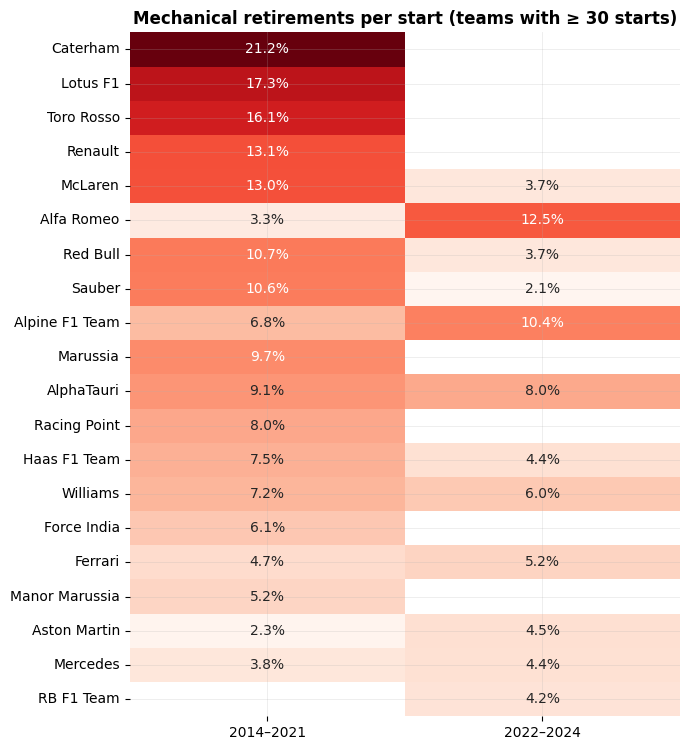

In [36]:
# Pivot table shown as a heatmap: rows = teams, columns = era, cell = mechanical-retirement rate
ranked_teams = team_rates[team_rates["ranked"]]
heat = pd.pivot_table(ranked_teams, index="team", columns="era", values="rate")
heat = heat.loc[heat.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7, 0.32 * len(heat) + 1.2))
sns.heatmap(heat, annot=True, fmt=".1%", cmap="Reds", cbar=False, ax=ax)
ax.set_title("Mechanical retirements per start (teams with ≥ 30 starts)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Reading the heatmap:** darker red = more breakdowns per start. A blank cell means the team did not exist under that name
(or had fewer than 30 starts) in that era, e.g. Caterham only raced in 2014 and RB only from 2024.

### Q3 answer
**Highest mechanical-retirement rates (teams with ≥ 30 starts):**

| Rank | 2014–2021 | 2022–2024 |
|---|---|---|
| 1 | Caterham **21.2%** (7 of 33; only one season) | Alfa Romeo **12.5%** (11 of 88) |
| 2 | Lotus F1 **17.3%** (13 of 75) | Alpine **10.4%** (14 of 135) |
| 3 | Toro Rosso **16.1%** (39 of 242) | AlphaTauri **8.0%** (7 of 88) |

- Caterham's rate rests on only 33 starts (each breakdown moves it by 3 points), so it is the least certain number in the table.
- Among teams that raced the **whole** 2014–2021 period, the least reliable were **Toro Rosso (16.1%), Renault (13.1%) and McLaren (13.0%)**.
- In 2022–2024 the front-running teams were the most reliable: **Red Bull and McLaren 3.7%**.

**Grain / missingness / cutoff:**
- Grain: one row per driver-race **start** (cars that never took the start are excluded, pit-lane starts kept);
  the rate is per start, so teams with more starts are comparable.
- Missingness: every row has a status, and all 139 status labels are classified (asserted).
- Teams are kept **as recorded**: renamed teams (e.g. Toro Rosso → AlphaTauri → RB) are separate constructors, because the dataset gives each name its own `constructorId`.
- Cutoff: retirement status is **post-race**. It is used here only to *describe* reliability; as a model feature it may only appear
  as a **past** value (a team's mechanical-retirement rate over its previous races, Part 3).

# Part 3: Feature selection & engineering

**The prediction cutoff:** for race *R*, a feature may only use information fixed **before the lights go out** (the grid and qualifying of
race *R*, the driver's age and nationality) and results of races **before** *R*. It may **never** use anything from race *R* itself
(finishing positions, points, status, laps, pit stops, or the standings *after* race *R*): that would be **data leakage**.

How the code enforces this:
- races are put in **time order** (`race_index`);
- every form feature uses `shift(1)`: the value for race *R* is computed from rows **before** *R* only;
- championship standings are taken from the **previous round** of the same season (the standings table for race *R* already contains *R*'s points);
- team features are first summed **per race**, then shifted, so a teammate's result in the same race cannot leak in;
- a **leakage test** (Section 10.2) proves this with code.

Features are built on the **full history (1950–2024)**, and the models also **train on all seasons from 1950** (Section 11).

## 9. Candidate features

| Group | Feature | Meaning | Known before the race because… |
|---|---|---|---|
| **grid** | `grid_pos` | starting slot after penalties; pit-lane start = last place | the grid is fixed before the start |
| | `front_row` | 1 if the car starts P1 or P2 (the Q1 idea) | same |
| | `pit_lane_start` | 1 if the car starts from the pit lane | same |
| | `field_size` | number of cars in the race | entry list |
| **qualifying** | `quali_pos` | qualifying position | qualifying ends before the race |
| | `quali_gap_pct` | best qualifying lap, % slower than the fastest driver | same |
| | `grid_penalty` | `grid_pos − quali_pos`: places lost (or gained) between qualifying and the grid | both are pre-race |
| **standings** | `drv_points_share`, `team_points_share` | season points after the **previous round** **÷ the leader's points** (leader = 1, nobody scored yet = 0) | standings of round *r − 1* |
| | `drv_rank_before`, `team_rank_before` | championship position from those points | same |
| | `drv_wins_before`, `team_wins_before` | season wins after the previous round | same |
| | *(team standings before 1958)* | the constructors' championship only started in **1958**, so for 1950–1957 the four team-standings features are **missing**, not 0 (handled in Section 15) | – |
| **driver form** | `drv_podium_rate_last5` | share of podiums in the driver's previous 5 races | earlier races only |
| | `drv_finish_pct_last5` | average finishing **percentile** in the previous 5 races (0 = won, 1 = last) | earlier races only |
| **team form** | `team_podium_share_last5` | podiums per car of the team over its previous 5 races | earlier races only |
| | `team_grid_pct_last5` | the team's average grid **percentile** over its previous 5 races (car pace) | earlier races only |
| | `team_mech_rate_last10` | mechanical retirements per start over the team's previous 10 races (Q3 definition) | earlier races only |
| **circuit** | `drv_circuit_podium_rate` | the driver's podium rate in his earlier visits to this circuit | earlier races only |
| **context** | `home_race` | driver's country = circuit's country (Q2 map) | static facts |
| | `driver_age` | age on race day | date of birth |
| | `drv_starts_before` | number of earlier races of the driver (experience) | earlier races only |

**Why shares and percentiles, not only raw numbers?** The same raw number means different things in different seasons:
- **Points:** a win was worth **8 points in the 1950s, 9 from 1961, 10 from 1991 and 25 from 2010**. "50 points" is a championship lead
  in 2005 and two wins in 2015. Our training seasons (1950–2019) mix all these scales, while the test seasons (2022–2024) use only the 25-point scale.
  `points_share` (÷ the leader) is on the same 0–1 scale in every season, so raw points are not used as features.
- **Finishing and grid positions:** 12th of 24 cars is mid-field, 12th of 20 is the back half. A percentile `(position − 1) ÷ (cars − 1)`
  puts every race on 0–1.

**Timing errors:** a best qualifying lap more than **twice** as slow as the fastest one is not a real lap (one 1995 Q1 time is recorded as
1,002 s, i.e. "922% slower than pole"). It is treated as *no valid time*; left in, this single row would wipe out the correlation of the
whole qualifying feature (−0.08 instead of −0.30).

**Why windows of 5 and 10 races?** Five races is about a quarter of a season: long enough to smooth one bad race, short enough to follow a
team that improves during the year. Mechanical failures are rarer (about 6–9% of starts, Q3), so they need a longer window (10 races ≈ 20 starts).

In [37]:
# Time order of races, and the previous round of the same season (for "standings before this race")
races_ord = CLEAN["races"][["raceId", "year", "round", "date"]].sort_values(["date", "raceId"]).reset_index(drop=True)
races_ord["race_index"] = np.arange(len(races_ord))
round_to_race = races_ord.set_index(["year", "round"])["raceId"]
races_ord["prev_raceId"] = [round_to_race.get((y, r - 1), np.nan) for y, r in zip(races_ord["year"], races_ord["round"])]
races_ord["prev_raceId"] = races_ord["prev_raceId"].astype(float)

is_mech_status = status_cat.set_index("statusId")["category"].eq("mechanical")      # Q3 status mapping
home_country_of = drv.set_index("driverId")["home_country"]                            # Q2 nationality -> country map
country_of_circuit = circ.set_index("circuitId")["country"]
dob_of = CLEAN["drivers"].set_index("driverId")["dob"]
print("Races in time order:", len(races_ord), "| round-1 races (no previous round):", int(races_ord["prev_raceId"].isna().sum()))

Races in time order: 1125 | round-1 races (no previous round): 75


In [38]:
def past_rolling(s, window, how="mean"):
    # value over the previous `window` rows of a group, EXCLUDING the current row (shift(1) first)
    return getattr(s.shift(1).rolling(window, min_periods=1), how)()

def standings_before(table, key, prefix):
    # standings rows of race X, relabelled as "known before the NEXT round" (prev_raceId = X)
    st = table[["raceId", key, "points", "wins"]].copy()
    st["points"] = st["points"].astype(float)
    leader = st.groupby("raceId")["points"].transform("max").replace(0, np.nan)
    st[f"{prefix}_points_share"] = st["points"] / leader
    st = st.rename(columns={"raceId": "prev_raceId", "points": f"{prefix}_points_before", "wins": f"{prefix}_wins_before"})
    st["prev_raceId"] = st["prev_raceId"].astype(float)
    return st

def build_features(res, d_stand, c_stand):
    # Build every candidate feature for every driver-race in `res`, using only pre-race information.
    df = res.merge(races_ord[["raceId", "race_index", "prev_raceId"]], on="raceId", how="left", validate="many_to_one")
    df = df.sort_values(["race_index", "driverId"]).reset_index(drop=True)
    for c in ["grid", "positionOrder", "credited_positionOrder", "podium", "laps"]:
        df[c] = df[c].astype(float)

    # --- grid (pit-lane start = behind everyone = last place)
    df["field_size"] = df.groupby("raceId")["driverId"].transform("size").astype(float)
    df["grid_pos"] = np.where(df["grid"] > 0, df["grid"], df["field_size"])
    df["front_row"] = df["grid"].isin([1, 2]).astype(int)
    df["pit_lane_start"] = (df["grid"] == 0).astype(int)

    # --- qualifying (this weekend, finished before the race)
    q = CLEAN["qualifying"][["raceId", "driverId", "position", "q1_s", "q2_s", "q3_s"]].copy()
    q["best_s"] = q[["q1_s", "q2_s", "q3_s"]].min(axis=1)
    q["quali_gap_pct"] = 100 * (q["best_s"] / q.groupby("raceId")["best_s"].transform("min") - 1)
    # A best lap more than twice as slow as the fastest one is a timing error, not a lap (one 1995 Q1 time is recorded as 1,002 s,
    # i.e. "922% slower than pole"). It is treated as "no valid qualifying time", like any other missing time.
    q.loc[q["quali_gap_pct"] > 100, "quali_gap_pct"] = np.nan
    q = q.rename(columns={"position": "quali_pos"})[["raceId", "driverId", "quali_pos", "quali_gap_pct"]]
    q["quali_pos"] = q["quali_pos"].astype(float)
    df = df.merge(q, on=["raceId", "driverId"], how="left", validate="one_to_one")
    df["grid_penalty"] = df["grid_pos"] - df["quali_pos"]

    # --- standings BEFORE this race = standings after the previous round of the same season
    df = df.merge(standings_before(d_stand, "driverId", "drv"), on=["prev_raceId", "driverId"], how="left", validate="many_to_one")
    df = df.merge(standings_before(c_stand, "constructorId", "team"), on=["prev_raceId", "constructorId"], how="left",
                  validate="many_to_one")
    zero_cols = [f"{p}_{c}" for p in ["drv", "team"] for c in ["points_before", "wins_before", "points_share"]]
    df[zero_cols] = df[zero_cols].astype(float).fillna(0)      # round 1, or no standings row yet = 0 points so far (Section 7.4)
    # Championship position among this race's entrants. Ties share the LOWEST rank (method="max"):
    # otherwise every driver in round 1 (all on 0 points) would be "1st". Teams are ranked once per team, not per car.
    df["drv_rank_before"] = df.groupby("raceId")["drv_points_before"].rank(ascending=False, method="max")
    teams = df[["raceId", "constructorId", "team_points_before"]].drop_duplicates(["raceId", "constructorId"])
    teams["team_rank_before"] = teams.groupby("raceId")["team_points_before"].rank(ascending=False, method="max")
    df = df.merge(teams[["raceId", "constructorId", "team_rank_before"]], on=["raceId", "constructorId"], how="left",
                  validate="many_to_one")
    # The constructors' championship only started in 1958: seasons without ANY constructor-standings rows have no team table.
    # Filling them with 0 would claim every team had 0 points, so the four team-standings features are set to missing instead.
    years_with_team_table = set(races_ord.loc[races_ord["raceId"].isin(c_stand["raceId"]), "year"])
    no_team_table = ~df["year"].isin(years_with_team_table)
    df.loc[no_team_table, ["team_points_before", "team_wins_before", "team_points_share", "team_rank_before"]] = np.nan

    # --- driver form: previous 5 races only
    df["finish_pct"] = (df["credited_positionOrder"] - 1) / (df["field_size"] - 1)    # THIS race's result: only used shifted
    g = df.groupby("driverId")
    df["drv_podium_rate_last5"] = g["podium"].transform(past_rolling, 5)
    df["drv_finish_pct_last5"] = g["finish_pct"].transform(past_rolling, 5)
    df["drv_starts_before"] = g.cumcount().astype(float)

    # --- team form and reliability: first ONE row per team per race, then shift (no teammate leakage)
    df["started"] = 1 - df["did_not_start"].astype(int)
    df["is_mech"] = (df["statusId"].map(is_mech_status).fillna(False).astype(bool) & df["started"].eq(1)).astype(int)
    df["grid_pct"] = (df["grid_pos"] - 1) / (df["field_size"] - 1)
    team = (df.groupby(["constructorId", "race_index"], as_index=False)
              .agg(podiums=("podium", "sum"), cars=("driverId", "size"), starts=("started", "sum"),
                   mech=("is_mech", "sum"), grid_pct=("grid_pct", "mean")))
    tg = team.groupby("constructorId")
    team["team_podium_share_last5"] = tg["podiums"].transform(past_rolling, 5, "sum") / tg["cars"].transform(past_rolling, 5, "sum")
    team["team_grid_pct_last5"] = tg["grid_pct"].transform(past_rolling, 5)
    team["team_mech_rate_last10"] = (tg["mech"].transform(past_rolling, 10, "sum")
                                     / tg["starts"].transform(past_rolling, 10, "sum").replace(0, np.nan))
    df = df.merge(team[["constructorId", "race_index", "team_podium_share_last5", "team_grid_pct_last5", "team_mech_rate_last10"]],
                  on=["constructorId", "race_index"], how="left", validate="many_to_one")

    # --- circuit history: podium rate in the driver's EARLIER visits to this circuit
    df["drv_circuit_podium_rate"] = (df.groupby(["driverId", "circuitId"])["podium"]
                                       .transform(lambda s: s.shift(1).expanding().mean()))

    # --- context
    df["home_race"] = (df["driverId"].map(home_country_of) == df["circuitId"].map(country_of_circuit)).astype(int)
    df["driver_age"] = (df["date"] - df["driverId"].map(dob_of)).dt.days / 365.25
    return df

CANDIDATE_GROUPS = {
    "grid": ["grid_pos", "front_row", "pit_lane_start", "field_size"],
    "qualifying": ["quali_pos", "quali_gap_pct", "grid_penalty"],
    "standings": ["drv_points_share", "drv_rank_before", "drv_wins_before",
                  "team_points_share", "team_rank_before", "team_wins_before"],
    "driver_form": ["drv_podium_rate_last5", "drv_finish_pct_last5"],
    "team_form": ["team_podium_share_last5", "team_grid_pct_last5", "team_mech_rate_last10"],
    "circuit": ["drv_circuit_podium_rate"],
    "context": ["home_race", "driver_age", "drv_starts_before"],
}
CANDIDATES = [f for group in CANDIDATE_GROUPS.values() for f in group]
group_of = {f: g for g, fs in CANDIDATE_GROUPS.items() for f in fs}

feat = build_features(base, CLEAN["driver_standings"], CLEAN["constructor_standings"])
assert len(feat) == len(base) and not feat.duplicated(["raceId", "driverId"]).any()
print(f"Feature table: {feat.shape[0]:,} rows | {len(CANDIDATES)} candidate features in {len(CANDIDATE_GROUPS)} groups | "
      "grain still one row per (raceId, driverId) ✅")

Feature table: 24,720 rows | 22 candidate features in 7 groups | grain still one row per (raceId, driverId) ✅


## 10. Fields that count as "future" information, and a leakage test

### 10.1 Left out
| Left out | Reason |
|---|---|
| `positionOrder`, `position`, `points`, `laps`, `statusId`, `time`, fastest lap of the **current** race | the race result itself: **leakage** |
| `did_not_start` | decided **after** the grid is fixed (Leclerc, Monaco 2021); the row stays in the data, never as an input |
| `pit_stops`, `lap_times` of the current race | happen during the race: **leakage** |
| `driver_standings` / `constructor_standings` of the **current** race | already contain this race's points: **leakage** (we use round *r − 1*) |
| `sprint_results` | only exists from 2021, so almost only in validation/test; the model could never learn it from training. When the sprint set the grid (2021–22), its effect is already inside `grid_pos` |
| `year` | the test seasons lie outside the training years, so the model would have to guess for a value it has never seen |
| `driverId`, `constructorId`, `circuitId` as categories (one-hot encoding) | the model would memorise names instead of patterns; teams get renamed (Q3), new drivers appear in the test seasons. Their useful information enters through **form** and **standings** instead. Q1 also showed that circuit differences are only a few races, too little for dozens of circuit columns |
| raw qualifying times (`q1`, `q2`, `q3` in seconds) | a 90 s lap is fast in Monza and impossible in Monaco; only the **gap to the fastest** is comparable |

In [39]:
FORBIDDEN = {"positionOrder", "credited_positionOrder", "position", "positionText", "points", "laps", "statusId",
             "status", "podium", "milliseconds", "fastestLap", "is_mech", "did_not_start", "finish_pct", "started"}
assert not FORBIDDEN & set(CANDIDATES), "a post-race column is in the candidate list"
print("No post-race column among the candidates ✅")

No post-race column among the candidates ✅


### 10.2 Leakage test
- **(a) Forbidden columns** (cell above): no post-race column is among the candidates.
- **(b) Change-a-race test:** we take a race, **change its results on purpose** (flip every podium, reverse the finishing order,
  add 1,000 points to its standings rows, mark every car as a mechanical failure), rebuild **all** features, and check:
  1. features for that race **and every earlier race** are **identical** → nothing from the race itself (or later) leaked in;
  2. features for **later** races **did** change → the test is sensitive (it would have caught a leak).

In [40]:
def leakage_test(race_id):
    r_idx = races_ord.set_index("raceId").loc[race_id, "race_index"]
    mut = base.copy()
    m = mut["raceId"] == race_id
    mut.loc[m, "podium"] = 1 - mut.loc[m, "podium"]
    mut.loc[m, "positionOrder"] = mut.loc[m, "positionOrder"].values[::-1]
    mut.loc[m, "credited_positionOrder"] = mut.loc[m, "credited_positionOrder"].values[::-1]
    mech_id = int(status_cat.loc[status_cat["status"] == "Engine", "statusId"].iloc[0])
    mut.loc[m, "statusId"] = mech_id
    d_st, c_st = CLEAN["driver_standings"].copy(), CLEAN["constructor_standings"].copy()
    d_st.loc[d_st["raceId"] == race_id, "points"] += 1000
    c_st.loc[c_st["raceId"] == race_id, "points"] += 1000
    new = build_features(mut, d_st, c_st)

    cols = ["raceId", "driverId"] + CANDIDATES
    before_orig = feat.loc[feat["race_index"] <= r_idx, cols].reset_index(drop=True)
    before_new = new.loc[new["race_index"] <= r_idx, cols].reset_index(drop=True)
    pd.testing.assert_frame_equal(before_orig, before_new, check_dtype=False)      # raises an error if anything leaked
    after_orig = feat.loc[feat["race_index"] > r_idx, CANDIDATES].reset_index(drop=True)
    after_new = new.loc[new["race_index"] > r_idx, CANDIDATES].reset_index(drop=True)
    changed = (after_orig.fillna(-999) != after_new.fillna(-999)).any(axis=1).sum()
    return int(changed)

rows = []
for (y, rd) in [(2010, 5), (2016, 5), (2023, 5)]:
    rows.append({"race changed": f"{y} round {rd}", "features of this & earlier races": "unchanged ✅",
                 "later driver-races whose features changed": leakage_test(round_to_race[(y, rd)])})
print("(b) change-a-race test:"); display(pd.DataFrame(rows))

(b) change-a-race test:


,race changed,features of this & earlier races,later driver-races whose features changed
0,2010 round 5,unchanged ✅,448
1,2016 round 5,unchanged ✅,450
2,2023 round 5,unchanged ✅,300


**Result:** for all three test races, changing the race's results did **not** change any feature of that race or any earlier race,
while hundreds of later rows changed (their form, reliability and standings now include the altered race). So the features use **only the past**.

## 11. Modeling window and train / validation / test split

- **Window: all seasons, 1950–2024.** Training on every season gives the models **3.3× more examples** (22,585 training rows instead of
  6,822 from 2003) and covers many rule eras, so they learn patterns that hold *across* eras, which is exactly what the test seasons
  (a brand-new rule era) require. The price: old seasons lack some data (no qualifying times before 1994, no team standings before 1958).
  These gaps are handled with "missing" flags in Section 15, not by deleting seasons.
- **Split by season, not randomly:**

| Split | Seasons | Purpose |
|---|---|---|
| train | 1950–2019 | the model learns from these; **all feature evidence below uses only these seasons** |
| validation | 2020–2021 | choose model settings and the decision threshold |
| test | 2022–2024 | final score, used **once** at the end; a complete new rule era (ground-effect cars) |

**Why by season and not `train_test_split` with random rows?**
- **It copies real use:** we always predict **later** races from **earlier** ones. A random split would train on 2023 and "predict" 2015.
- **Rows of one race depend on each other:** every race has exactly three podiums. With random rows, some drivers of a race
  would be in training and the rest in test, and the model could partly guess the test labels.
- **The test seasons are a new rule era**, so the test score answers an honest question: does a model trained on older eras still work
  after a regulation change?

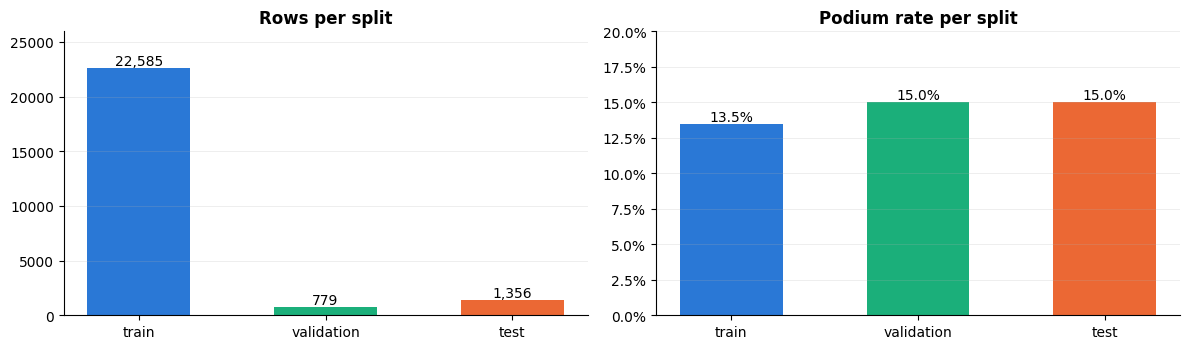

,seasons,races,rows,podium_rate,share_of_rows
split,,,,,
train,1950–2019,1007,"22,585",13.5%,91%
validation,2020–2021,39,779,15.0%,3%
test,2022–2024,68,"1,356",15.0%,5%


In [41]:
mt = feat[feat["year"].between(1950, 2024)].copy()
mt["split"] = np.select([mt["year"] <= 2019, mt["year"] <= 2021], ["train", "validation"], "test")
split_summary = mt.groupby("split", sort=False).agg(
    seasons=("year", lambda s: f"{s.min()}–{s.max()}"), races=("raceId", "nunique"), rows=("raceId", "size"),
    podium_rate=("podium", "mean")).reindex(["train", "validation", "test"])
split_summary["share_of_rows"] = split_summary["rows"] / split_summary["rows"].sum()
assert not (set(mt.loc[mt["split"] == "train", "raceId"]) & set(mt.loc[mt["split"] != "train", "raceId"]))

SPLIT_COLOR = {"train": BLUE, "validation": AQUA, "test": ORANGE}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(split_summary.index, split_summary["rows"], color=list(SPLIT_COLOR.values()), width=0.55)
for i, v in enumerate(split_summary["rows"]):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[0].set_title("Rows per split"); axes[0].set_ylim(0, split_summary["rows"].max() * 1.15)
axes[1].bar(split_summary.index, split_summary["podium_rate"], color=list(SPLIT_COLOR.values()), width=0.55)
for i, v in enumerate(split_summary["podium_rate"]):
    axes[1].text(i, v, f"{v:.1%}", ha="center", va="bottom")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title("Podium rate per split")
axes[1].set_ylim(0, 0.2)
for ax in axes: ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
split_summary.style.format({"rows": "{:,}", "podium_rate": "{:.1%}", "share_of_rows": "{:.0%}"})

**Reading the result:** about **91% / 3% / 5%** of rows: the training seasons now contain 1,007 races. The podium rate is a little lower in
training (13.5% vs 15.0%) because older fields were bigger (up to 34 cars): 3 podiums ÷ 20 cars = 15%, ÷ 26 cars = 11.5%. That is a property
of the sport, not of the split. Validation and test are unchanged, so every model is still judged on the same 2020–2024 races.

## 12. Evidence for every candidate (training seasons 1950–2019 only)
Looking at validation or test seasons to **choose** features would leak their information into the design, so they stay unseen here.

### 12.1 Podium rate across the values of each feature
If a feature is useful, the podium rate should change clearly from its lowest to its highest values; a **flat** row of bars means little signal.
Numeric features are cut into 5 equal-size groups with `pd.qcut`; the "rate" features, which are 0 for most drivers, get fixed groups
with `pd.cut`. The dashed line is the average podium rate. Missing values (e.g. qualifying before 1994) are left out of each panel, so every bar is based on real values only.

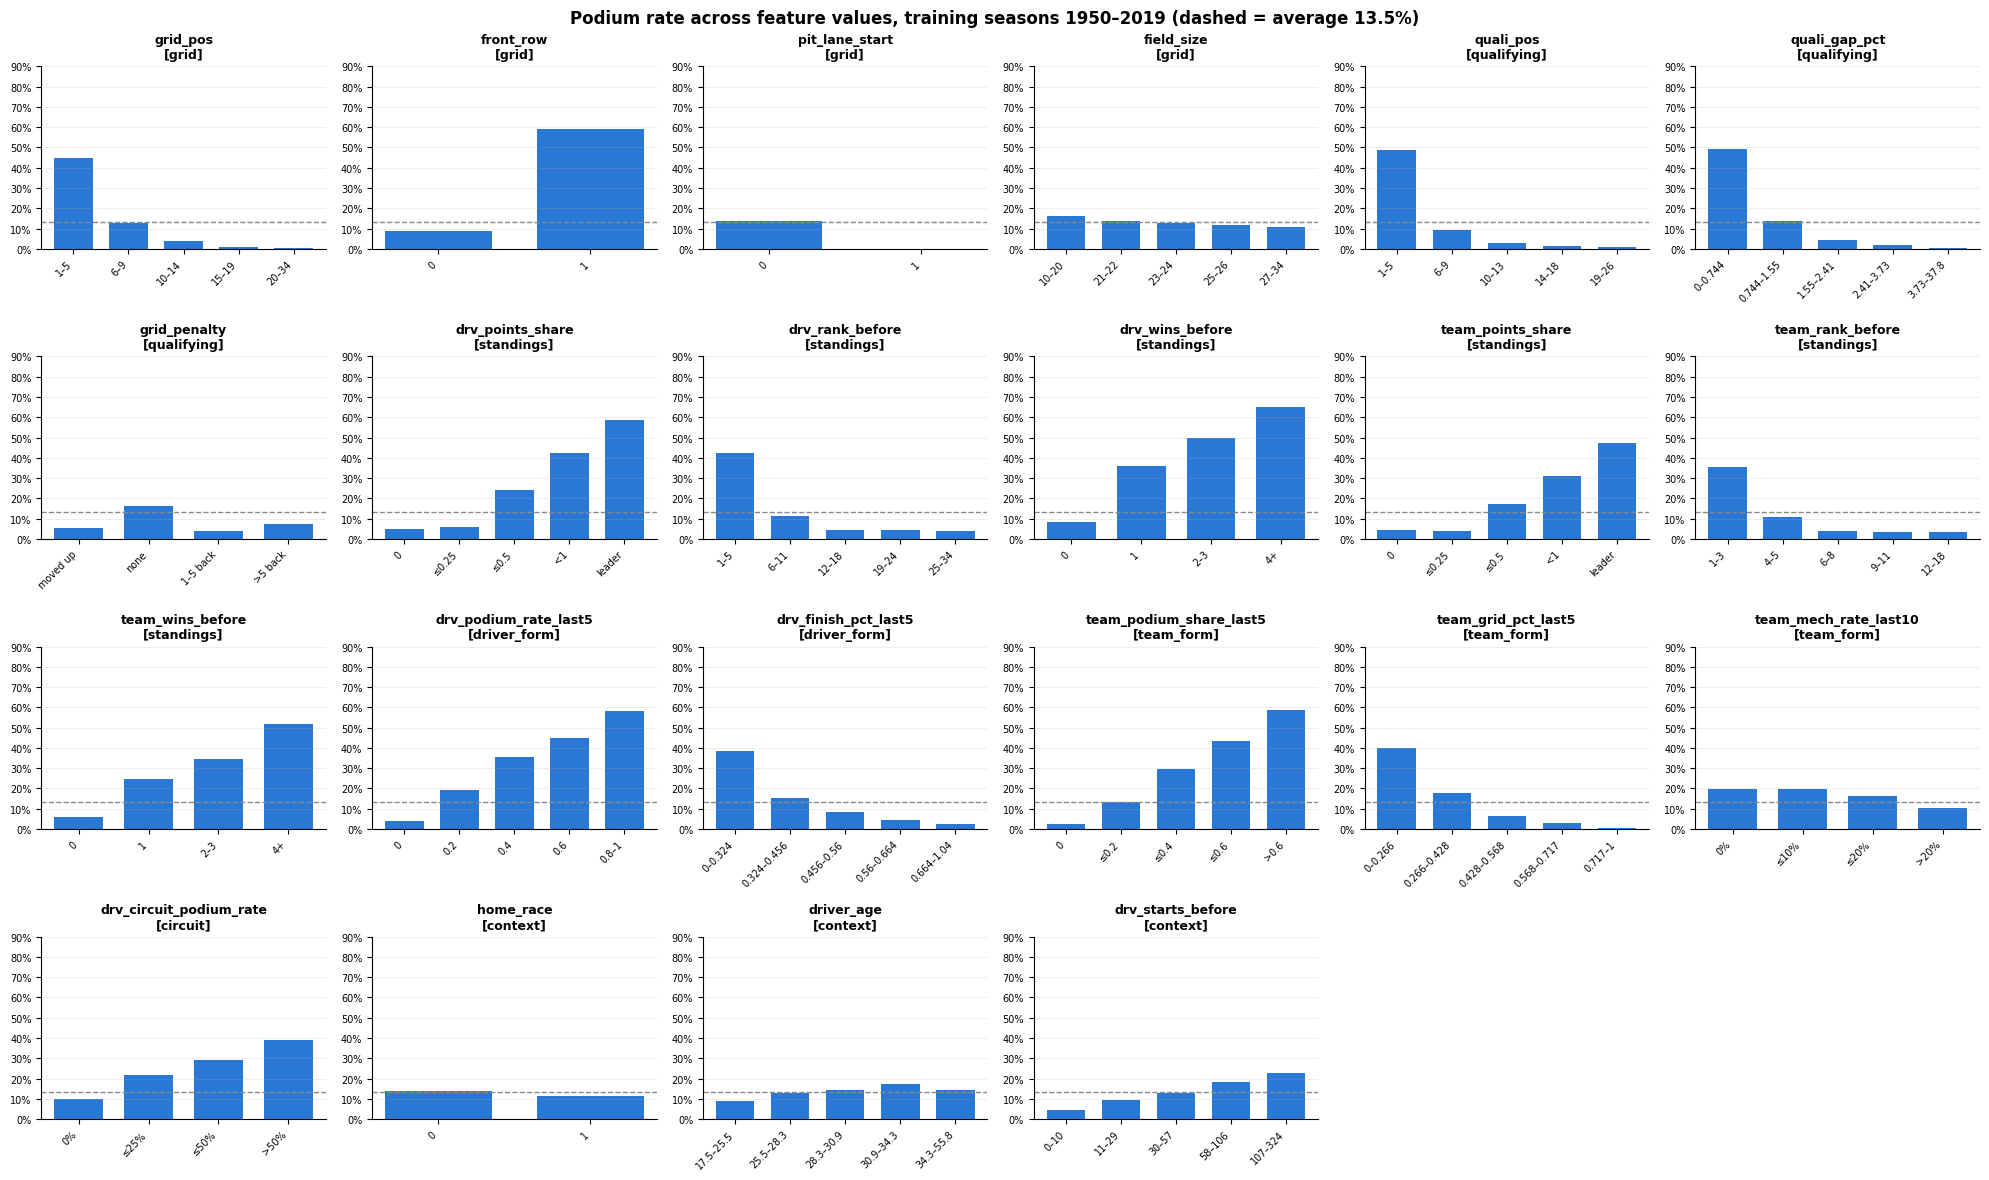

Gap between the best and the worst group (percentage points):
{'drv_wins_before': 56.8, 'team_podium_share_last5': 56.4, 'drv_podium_rate_last5': 54.4, 'drv_points_share': 53.7, 'front_row': 49.9, 'quali_gap_pct': 48.8, 'quali_pos': 48.0, 'team_wins_before': 45.6, 'grid_pos': 44.3, 'team_points_share': 43.3, 'team_grid_pct_last5': 39.3, 'drv_rank_before': 38.7, 'drv_finish_pct_last5': 36.1, 'team_rank_before': 32.3, 'drv_circuit_podium_rate': 28.9, 'drv_starts_before': 18.0, 'pit_lane_start': 13.5, 'grid_penalty': 12.6, 'team_mech_rate_last10': 9.6, 'driver_age': 8.1, 'field_size': 5.1, 'home_race': 2.2}


In [42]:
train = mt[mt["split"] == "train"]          # all evidence below uses the training seasons only
FIXED_BINS = {
    "drv_podium_rate_last5": ([-0.01, 0, 0.2, 0.4, 0.6, 1], ["0", "0.2", "0.4", "0.6", "0.8–1"]),
    "team_podium_share_last5": ([-0.01, 0, 0.2, 0.4, 0.6, 1], ["0", "≤0.2", "≤0.4", "≤0.6", ">0.6"]),
    "team_mech_rate_last10": ([-0.01, 0, 0.1, 0.2, 1], ["0%", "≤10%", "≤20%", ">20%"]),
    "drv_circuit_podium_rate": ([-0.01, 0, 0.25, 0.5, 1], ["0%", "≤25%", "≤50%", ">50%"]),
    "drv_points_share": ([-0.01, 0, 0.25, 0.5, 0.99, 1], ["0", "≤0.25", "≤0.5", "<1", "leader"]),
    "team_points_share": ([-0.01, 0, 0.25, 0.5, 0.99, 1], ["0", "≤0.25", "≤0.5", "<1", "leader"]),
    "drv_wins_before": ([-1, 0, 1, 3, 99], ["0", "1", "2–3", "4+"]),
    "team_wins_before": ([-1, 0, 1, 3, 99], ["0", "1", "2–3", "4+"]),
    "grid_penalty": ([-99, -0.5, 0.5, 5.5, 99], ["moved up", "none", "1–5 back", ">5 back"]),
}

def podium_by_bins(col, q=5):
    s = train[col]
    if col in FIXED_BINS:
        edges, names = FIXED_BINS[col]
        groups = pd.cut(s, bins=edges, labels=names)
    elif s.nunique() <= 6:
        groups = s
    else:
        groups = pd.qcut(s, q=q, duplicates="drop")
    return train.groupby(groups, observed=True)["podium"].agg(["mean", "size"])

def bin_label(i, whole):
    if not hasattr(i, "left"):
        return str(int(i)) if isinstance(i, (int, float, np.integer, np.floating)) and float(i).is_integer() else str(i)
    if whole:
        return f"{int(np.floor(i.left)) + 1}–{int(i.right)}"
    return f"{max(i.left, 0):.3g}–{i.right:.3g}"

base_rate = train["podium"].mean()
spread = {}
ncol = 6
fig, axes = plt.subplots(4, ncol, figsize=(20, 12))
for ax, col in zip(axes.ravel(), CANDIDATES):
    r = podium_by_bins(col)
    spread[col] = r["mean"].max() - r["mean"].min()
    ax.bar(range(len(r)), r["mean"].values, color=BLUE, width=0.7)
    ax.axhline(base_rate, color=GRAY, ls="--", lw=1)
    whole = (train[col].dropna() % 1 == 0).all()
    ax.set_xticks(range(len(r))); ax.set_xticklabels([bin_label(i, whole) for i in r.index], rotation=45, ha="right", fontsize=7)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.set_ylim(0, 0.9)
    ax.set_title(f"{col}\n[{group_of[col]}]", fontsize=9); ax.grid(axis="x", visible=False); ax.tick_params(axis="y", labelsize=7)
for ax in axes.ravel()[len(CANDIDATES):]:
    ax.axis("off")
plt.suptitle(f"Podium rate across feature values, training seasons {train.year.min()}–{train.year.max()} (dashed = average {base_rate:.1%})", fontweight="bold")
plt.tight_layout(); plt.show()
print("Gap between the best and the worst group (percentage points):")
print({k: round(100 * v, 1) for k, v in sorted(spread.items(), key=lambda kv: -kv[1])})

**Reading the panels:**
- **Steep** (strong signal): grid (P1–5 about 45% podiums, P20+ almost 0%), qualifying position and gap, standings (championship leader 59%,
  4+ wins this season 65%), driver and team form (podium in 4–5 of the last 5 races: 59%).
- **Medium:** circuit history (10% → 39%), experience (5% for rookies → 23% for 100+ starts).
- **Weak:** team reliability (20% → 11%): in the older seasons a third of all starts ended in a breakdown, so recent breakdowns say less about
  the next race.
- **Flat** around the dashed line (little signal): `field_size`, `home_race`, `driver_age`. `pit_lane_start` is too rare to read.
- `grid_penalty` has **no direction**: drivers with no change podium most (17%), but drivers moved **up** do worse, just like drivers moved
  back (moving up usually means a midfield car gained a place from someone else's penalty).

### 12.2 Correlation heatmap and ranking
Correlation of every feature with `podium` (how strongly the two move together, from −1 to +1) and with each other.
A strong correlation with `podium` = signal; two features strongly correlated with **each other** = they carry the same information.

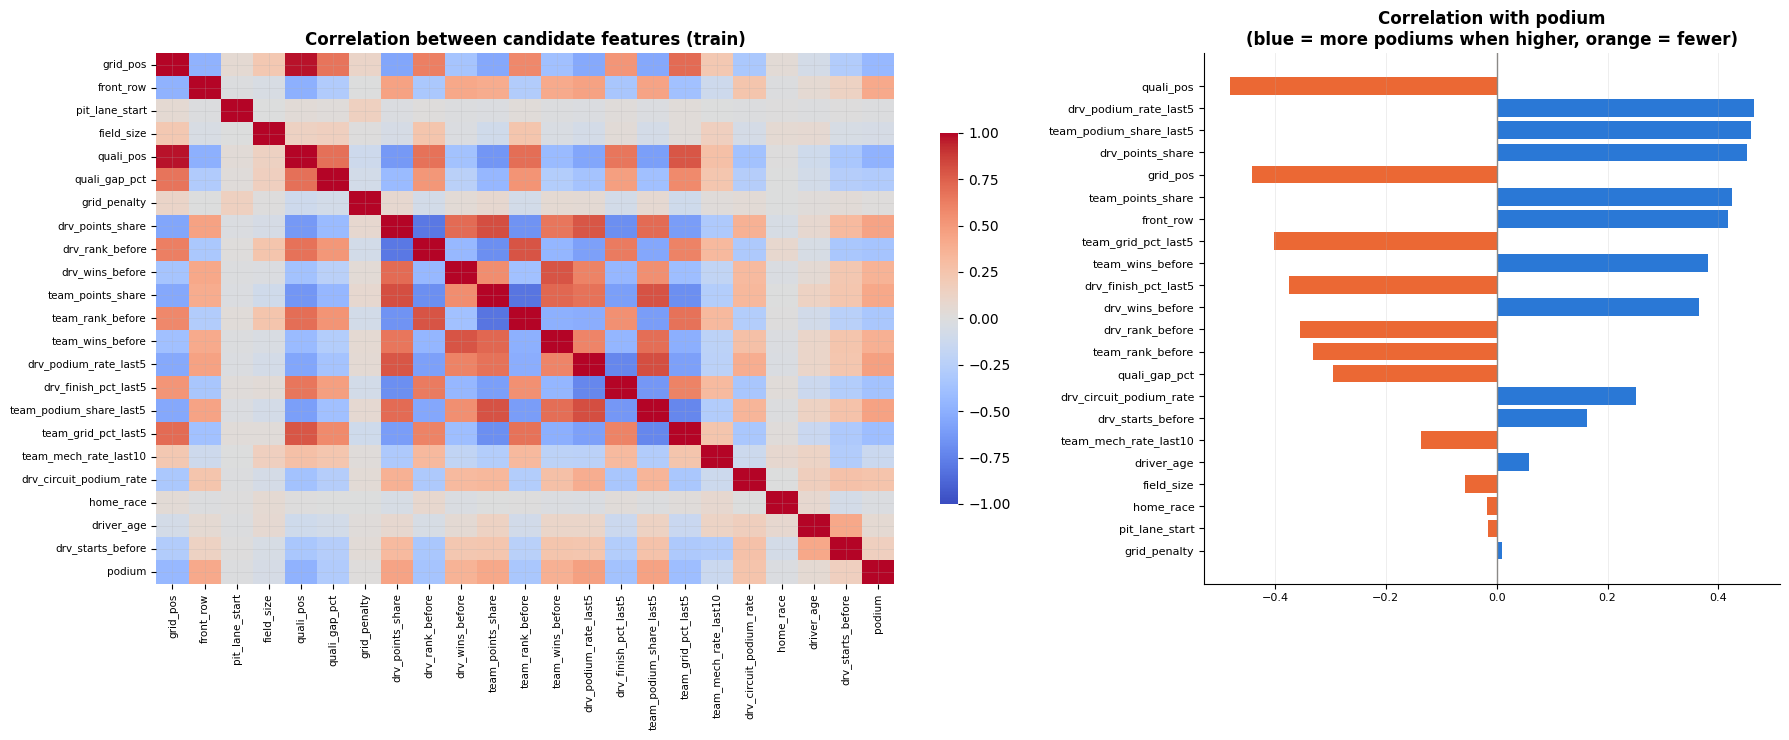

Strongest 5 (absolute): {'quali_pos': 0.48, 'drv_podium_rate_last5': 0.46, 'team_podium_share_last5': 0.46, 'drv_points_share': 0.45, 'grid_pos': 0.44}
Weakest 5 (absolute): {'grid_penalty': 0.009, 'pit_lane_start': 0.015, 'home_race': 0.018, 'field_size': 0.057, 'driver_age': 0.058}


In [43]:
corr = train[CANDIDATES + ["podium"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0], cbar_kws={"shrink": 0.7},
            xticklabels=True, yticklabels=True)
axes[0].set_title("Correlation between candidate features (train)"); axes[0].tick_params(labelsize=7.5)
rank_corr = corr["podium"].drop("podium").sort_values(key=abs)
axes[1].barh(rank_corr.index, rank_corr.values, color=[BLUE if v > 0 else ORANGE for v in rank_corr.values])
axes[1].axvline(0, color=GRAY, lw=1)
axes[1].set_title("Correlation with podium\n(blue = more podiums when higher, orange = fewer)"); axes[1].tick_params(labelsize=8)
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("Strongest 5 (absolute):", rank_corr.abs().sort_values(ascending=False).head(5).round(2).to_dict())
print("Weakest 5 (absolute):", rank_corr.abs().sort_values().head(5).round(3).to_dict())

### 12.3 Duplicate features
Pairs of candidates with correlation **≥ 0.95** carry essentially the same information (the model would split the credit between them,
which makes the explanations in the XAI part harder to read):

In [44]:
fcorr = train[CANDIDATES].corr()
pairs = (fcorr.where(np.triu(np.ones(fcorr.shape, dtype=bool), k=1)).stack().rename("correlation").reset_index()
              .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs = pairs[pairs["correlation"].abs() >= 0.85].sort_values("correlation", key=abs, ascending=False)
pairs["duplicate (≥ 0.95)?"] = np.where(pairs["correlation"].abs() >= 0.95, "yes", "no, overlap only")
pairs.style.format({"correlation": "{:+.2f}"}).hide(axis="index")

feature_a,feature_b,correlation,duplicate (≥ 0.95)?
grid_pos,quali_pos,+0.98,yes


## 13. Selection rules and the final feature list

A candidate is **kept** only if it passes all three rules (everything measured on the training seasons):
1. **Leakage-safe:** uses only pre-race information (Section 10; all candidates do).
2. **Signal:** correlation with podium of at least **0.10** in absolute value (Section 12.2), backed by a visible change of the podium rate
   across its values (Section 12.1).
3. **Not a duplicate or a copy:** of two features with correlation ≥ 0.95, or one computed directly from another, keep one (Section 12.3).
   - `quali_pos` vs `grid_pos` (0.98): keep the **grid**, because it is where the car actually starts (it already contains penalties, Q1).
     What qualifying adds beyond the grid, the **speed** gap to the fastest car, stays in through `quali_gap_pct`.
   - `front_row` is just `grid_pos ≤ 2`: a copy of the grid, so it is dropped.

In [45]:
COPY_OF = {"quali_pos": "grid_pos (correlation 0.98); the grid is where the car actually starts",
           "front_row": "grid_pos (front_row = grid_pos ≤ 2)"}

decision = pd.DataFrame({"group": [group_of[f] for f in CANDIDATES],
                         "corr_with_podium": corr.loc[CANDIDATES, "podium"].round(3).values}, index=CANDIDATES)
decision["signal_ok"] = decision["corr_with_podium"].abs() >= 0.10

def reason(f, r):
    if f in COPY_OF:
        return "dropped: copy of " + COPY_OF[f]
    if not r["signal_ok"]:
        return f"dropped: too little signal (correlation {r['corr_with_podium']:+.3f})"
    return "kept"

decision["decision"] = [reason(f, r) for f, r in decision.iterrows()]
decision["keep"] = decision["decision"].eq("kept")
FEATURES = [f for f in CANDIDATES if decision.loc[f, "keep"]]
FEATURE_GROUPS = {g: [f for f in fs if f in FEATURES] for g, fs in CANDIDATE_GROUPS.items()}
FEATURE_GROUPS = {g: fs for g, fs in FEATURE_GROUPS.items() if fs}
print(f"Kept {len(FEATURES)} of {len(CANDIDATES)} candidates:")
for g, fs in FEATURE_GROUPS.items():
    print(f"  {g:<12} {fs}")
decision[["group", "corr_with_podium", "decision"]].style.format({"corr_with_podium": "{:+.3f}"})

Kept 15 of 22 candidates:
  grid         ['grid_pos']
  qualifying   ['quali_gap_pct']
  standings    ['drv_points_share', 'drv_rank_before', 'drv_wins_before', 'team_points_share', 'team_rank_before', 'team_wins_before']
  driver_form  ['drv_podium_rate_last5', 'drv_finish_pct_last5']
  team_form    ['team_podium_share_last5', 'team_grid_pct_last5', 'team_mech_rate_last10']
  circuit      ['drv_circuit_podium_rate']
  context      ['drv_starts_before']


,group,corr_with_podium,decision
grid_pos,grid,-0.442,kept
front_row,grid,+0.417,dropped: copy of grid_pos (front_row = grid_pos ≤ 2)
pit_lane_start,grid,-0.015,dropped: too little signal (correlation -0.015)
field_size,grid,-0.057,dropped: too little signal (correlation -0.057)
quali_pos,qualifying,-0.481,dropped: copy of grid_pos (correlation 0.98); the grid is where the car actually starts
quali_gap_pct,qualifying,-0.296,kept
grid_penalty,qualifying,+0.009,dropped: too little signal (correlation +0.009)
drv_points_share,standings,+0.451,kept
drv_rank_before,standings,-0.355,kept
drv_wins_before,standings,+0.365,kept


**Result: 15 of 22 candidates are kept**, in seven groups:

| Group | Kept | Dropped (why) |
|---|---|---|
| grid | `grid_pos` | `front_row` (copy of the grid), `pit_lane_start`, `field_size` (no signal; a pit-lane starter is still marked by `grid_pos` = last place) |
| qualifying | `quali_gap_pct` | `quali_pos` (duplicate of the grid), `grid_penalty` (no signal) |
| standings | points share, rank and wins, for driver and team | – |
| driver form | podium rate and finish percentile, last 5 races | – |
| team form | podium share, grid percentile (pace), mechanical-failure rate | – |
| circuit | the driver's past podium rate at this track | – |
| context | `drv_starts_before` (experience) | `home_race` (correlation −0.02, the same conclusion as Q2), `driver_age` (0.06) |

**Overlapping features are kept on purpose** (correlation about 0.8): driver vs team points share, driver vs team podium rate.
They overlap because teammates share a car, but they are not the same: two teammates in one car can score very differently.

## 14. Feature dictionary and the modeling table
Every selected feature, how it is computed, and why it is known **before** the race starts.

In [46]:
WHY = {
    "front_row": "grid 1 or 2; fixed before the start",
    "pit_lane_start": "grid = 0; fixed before the start",
    "field_size": "number of cars in this race; known before the start",
    "quali_pos": "qualifying position; qualifying ends before the race",
    "grid_penalty": "grid position minus qualifying position; both pre-race",
    "home_race": "driver nationality matches circuit country (Q2 map); static",
    "driver_age": "race date minus date of birth",
    "grid_pos": "starting slot after penalties (pit lane = last); fixed before the start",
    "quali_gap_pct": "best qualifying lap vs the fastest, in %; qualifying ends before the race",
    "drv_points_share": "driver's season points ÷ leader's points, after the PREVIOUS round",
    "drv_rank_before": "driver's championship position after the previous round (no points yet = last)",
    "drv_wins_before": "driver's season wins after the previous round",
    "team_points_share": "team's season points ÷ leading team's points, after the previous round",
    "team_rank_before": "team's championship position after the previous round (missing before 1958)",
    "team_wins_before": "team's season wins after the previous round",
    "drv_podium_rate_last5": "share of podiums in the driver's previous 5 races (shift(1))",
    "drv_finish_pct_last5": "average finishing percentile in the previous 5 races (shift(1))",
    "team_podium_share_last5": "team podiums per car over its previous 5 races (team-level shift)",
    "team_grid_pct_last5": "team's average grid percentile over its previous 5 races (team-level shift)",
    "team_mech_rate_last10": "mechanical retirements per start in the team's previous 10 races (Q3 mapping)",
    "drv_circuit_podium_rate": "driver's podium rate in earlier visits to this circuit (shift(1))",
    "drv_starts_before": "number of earlier races of the driver",
}
assert set(FEATURES) <= set(WHY), set(FEATURES) - set(WHY)
feature_dictionary = pd.DataFrame({"group": [group_of[f] for f in FEATURES], "feature": FEATURES,
                                   "why it is pre-race": [WHY[f] for f in FEATURES],
                                   "missing in train": [f"{train[f].isnull().mean():.1%}" for f in FEATURES]})
ID_COLS = ["raceId", "year", "round", "date", "name", "circuitId", "driverId", "constructorId", "split"]
modeling_table = mt[ID_COLS + FEATURES + ["podium"]].reset_index(drop=True)
assert not modeling_table.duplicated(["raceId", "driverId"]).any() and not FORBIDDEN & set(FEATURES)
modeling_table.to_csv(os.path.join(OUT_DIR, "modeling_table.csv"), index=False)
print(f"Modeling table saved: {modeling_table.shape[0]:,} rows x {modeling_table.shape[1]} columns "
      f"(one row per driver-race, 1950–2024, {len(FEATURES)} features) -> {OUT_DIR}/modeling_table.csv")
feature_dictionary.style.hide(axis="index")

Modeling table saved: 24,720 rows x 25 columns (one row per driver-race, 1950–2024, 15 features) -> /kaggle/working/modeling_table.csv


group,feature,why it is pre-race,missing in train
grid,grid_pos,starting slot after penalties (pit lane = last); fixed before the start,0.0%
qualifying,quali_gap_pct,"best qualifying lap vs the fastest, in %; qualifying ends before the race",63.7%
standings,drv_points_share,"driver's season points ÷ leader's points, after the PREVIOUS round",0.0%
standings,drv_rank_before,driver's championship position after the previous round (no points yet = last),0.0%
standings,drv_wins_before,driver's season wins after the previous round,0.0%
standings,team_points_share,"team's season points ÷ leading team's points, after the previous round",5.2%
standings,team_rank_before,team's championship position after the previous round (missing before 1958),5.2%
standings,team_wins_before,team's season wins after the previous round,5.2%
driver_form,drv_podium_rate_last5,share of podiums in the driver's previous 5 races (shift(1)),3.0%
driver_form,drv_finish_pct_last5,average finishing percentile in the previous 5 races (shift(1)),3.0%


## 15. Pre-processing

The models cannot read the feature table as it is: some values are missing and the columns are on very different scales
(grid 1–34, experience 0–324 races, rates 0–1). Two steps fix this:

| Step | What it does | Why |
|---|---|---|
| 1. Missing values | fill with the **training median**; add a 0/1 flag where "missing" itself carries information | the models cannot take empty values; the median is not pulled by extreme values |
| 2. Scaling | `StandardScaler`: every feature gets mean 0 and standard deviation 1 | grid (1–34) and experience (0–324) would otherwise outweigh the 0–1 rates in logistic regression and the neural network |

Every value the steps *learn* (medians, means, standard deviations) is learned from the **training seasons only** and then applied
unchanged to validation, test and new races. Section 16 (Experiment A) tests what happens if this rule is broken.

In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

X_raw = {s: mt.loc[mt["split"] == s, FEATURES] for s in ["train", "validation", "test"]}
y = {s: mt.loc[mt["split"] == s, "podium"].astype(int).to_numpy() for s in ["train", "validation", "test"]}
print({s: X_raw[s].shape for s in X_raw})

{'train': (22585, 15), 'validation': (779, 15), 'test': (1356, 15)}


### 15.1 Missing values
Every gap has a known meaning. The table checks whether the drivers with a gap are **typical** drivers or not:

In [48]:
tr = mt[mt["split"] == "train"]
rookie = tr["drv_podium_rate_last5"].isna()
assert (rookie == tr["drv_starts_before"].eq(0)).all()      # driver form missing  <=>  first ever start
gaps = [
    ("quali_gap_pct", "driver set no qualifying lap time", tr["quali_gap_pct"].isna()),
    ("drv_podium_rate_last5, drv_finish_pct_last5", "driver's first ever start (debut)", rookie),
    ("team_podium_share_last5, team_grid_pct_last5, team_mech_rate_last10", "team's first ever race (new or renamed team)",
     tr["team_podium_share_last5"].isna()),
    ("drv_circuit_podium_rate", "driver's first visit to this circuit", tr["drv_circuit_podium_rate"].isna()),
    ("team_points_share, team_rank_before, team_wins_before", "season before 1958 (no constructors' championship)",
     tr["team_points_share"].isna()),
]
missing_meaning = pd.DataFrame([{
    "feature(s)": f, "missing means": why, "rows (train)": int(m.sum()), "share of rows": m.mean(),
    "podium rate when missing": tr.loc[m, "podium"].mean(), "median grid when missing": tr.loc[m, "grid_pos"].median()}
    for f, why, m in gaps])
print(f"For comparison, all training rows: podium rate {tr['podium'].mean():.1%}, median grid position {tr['grid_pos'].median():.0f}")
print(f"Drivers with a circuit history of exactly 0 podiums: podium rate "
      f"{tr.loc[tr['drv_circuit_podium_rate'].eq(0), 'podium'].mean():.1%}")
missing_meaning.style.format({"share of rows": "{:.1%}", "podium rate when missing": "{:.1%}",
                              "median grid when missing": "{:.0f}"}).hide(axis="index")

For comparison, all training rows: podium rate 13.5%, median grid position 12
Drivers with a circuit history of exactly 0 podiums: podium rate 10.0%


feature(s),missing means,rows (train),share of rows,podium rate when missing,median grid when missing
quali_gap_pct,driver set no qualifying lap time,14376,63.7%,13.1%,12
"drv_podium_rate_last5, drv_finish_pct_last5",driver's first ever start (debut),675,3.0%,2.5%,18
"team_podium_share_last5, team_grid_pct_last5, team_mech_rate_last10",team's first ever race (new or renamed team),258,1.1%,5.0%,17
drv_circuit_podium_rate,driver's first visit to this circuit,7088,31.4%,6.7%,15
"team_points_share, team_rank_before, team_wins_before",season before 1958 (no constructors' championship),1171,5.2%,15.7%,11


**Decisions (remove or impute?):**
- **No column is removed.** A column is worth dropping when most of it is missing for no known reason. Our largest gap,
  `quali_gap_pct`, is missing in 64% of training rows, but for a **known reason** (qualifying times are only recorded from 1994) and it is
  almost complete in the seasons we predict (1% missing in validation and test). Where it exists it is one of the strongest signals
  (correlation −0.30), so it is kept.
- **No row is removed.** Every row is a real prediction we must be able to make (a rookie's first race still has to be predicted), and
  removing the rows with gaps would remove whole eras (everything before 1994).
- **Fill with the training median** (it is not pulled by extreme values like the mean, e.g. a few very slow qualifying laps).
- **Add a 0/1 flag where the gap itself is information:**
  - `no_quali_time`: without it, the median would pretend that every driver before 1994 qualified about 2% off pole. The flag tells the model
    "no qualifying information here, rely on the grid instead".
  - `first_circuit_visit`: first-time visitors podium only 6.7% of the time, but the filled value (0) would treat them like drivers who have
    been there before and never podiumed (10.0%).
  - `no_team_standings`: 1950–1957 had no constructors' championship. The flag separates "no table yet" from "the team really has 0 points".
- **No flag for driver form:** missing driver form happens exactly when `drv_starts_before = 0` (asserted above), so the model already knows.
- **No flag for team form:** only 1.1% of training rows, too few to learn a separate pattern.

### 15.2 Scaling

Models that work with weights (logistic regression, the neural network) treat a feature with bigger numbers as more important just because
its numbers are bigger.
Our columns range from 0–1 (rates) to 0–324 (starts), so we **standardize**: each feature gets **mean 0 and standard deviation 1**, using the
mean and standard deviation of the **training** rows.

- Logistic regression and the neural network **need** this (their weights and training steps depend on the size of the numbers).
- Tree models (random forest) do not care, but they get the same inputs so that all models are compared on exactly the same table.

### 15.3 The full pre-processing, in a fixed order
`fit_preprocessing` learns everything from the training rows; `apply_preprocessing` uses what was learned on any rows (validation, test,
or one new race in the inference function). **The order matters:**
1. **flags first:** after filling, we could no longer see which values were missing;
2. **fill before scaling:** the models cannot take empty values;
3. **scale last**, on the finished columns.

In [49]:
FLAGS = {"no_quali_time": "quali_gap_pct", "first_circuit_visit": "drv_circuit_podium_rate",
         "no_team_standings": "team_points_share"}

def add_flags(X):
    X = X.copy()
    for flag, col in FLAGS.items():
        if col in X:
            X[flag] = X[col].isna().astype(int)
    return X

def fit_preprocessing(X_fit):
    # Learn medians and the scaler from X_fit (= the TRAINING rows)
    X = add_flags(X_fit)
    medians_ = X.median()
    X = X.fillna(medians_)
    scaler_ = StandardScaler().fit(X)
    return {"columns": list(X.columns), "medians": medians_, "scaler": scaler_}

def apply_preprocessing(prep, X_any):
    # Apply what was learned in fit_preprocessing to any rows; nothing is re-learned here
    X = add_flags(X_any)[prep["columns"]].fillna(prep["medians"])
    return pd.DataFrame(prep["scaler"].transform(X), columns=prep["columns"], index=X.index)

prep = fit_preprocessing(X_raw["train"])
X = {s: apply_preprocessing(prep, X_raw[s]) for s in X_raw}
MODEL_FEATURES = prep["columns"]
assert all(not X[s].isnull().values.any() for s in X)
print(f"Model inputs: {len(MODEL_FEATURES)} columns = {len(FEATURES)} features + flags {[f for f in FLAGS if f in MODEL_FEATURES]}")
print("Missing values left:", {s: int(X[s].isnull().sum().sum()) for s in X})

Model inputs: 18 columns = 15 features + flags ['no_quali_time', 'first_circuit_visit', 'no_team_standings']
Missing values left: {'train': 0, 'validation': 0, 'test': 0}


### 15.4 Effect of the pre-processing on the data (distribution, range, values)

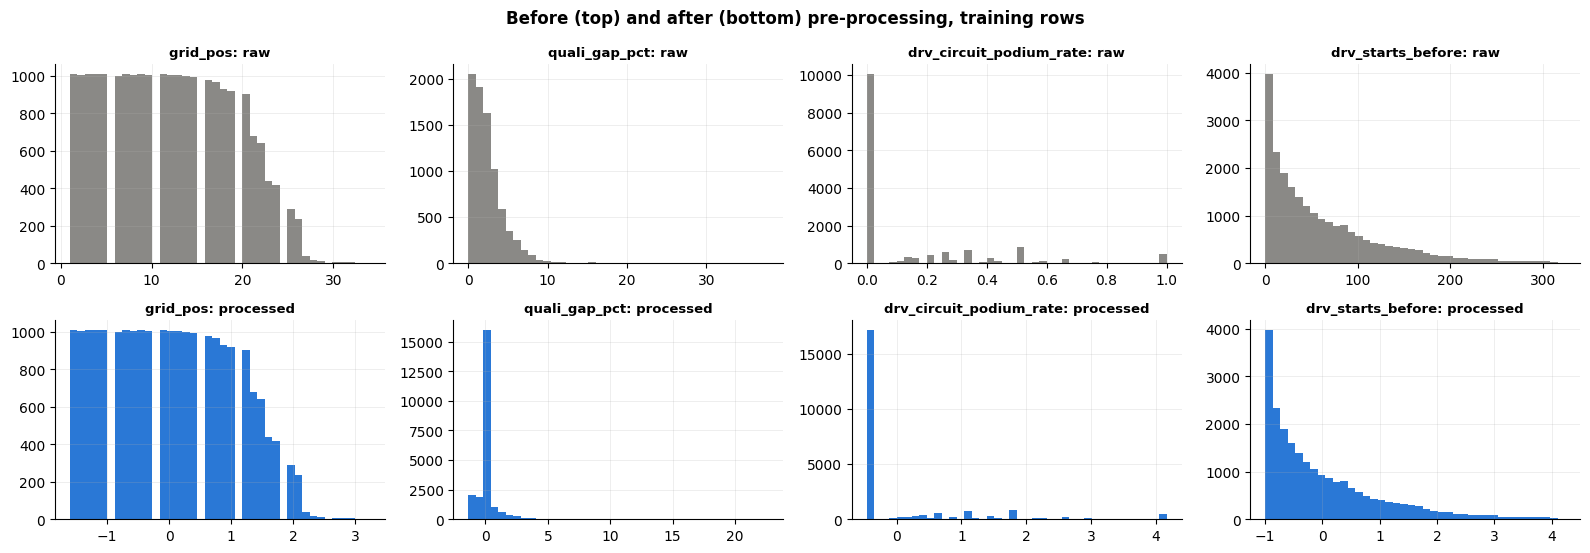

In [50]:
before = X_raw["train"].describe().T[["mean", "std", "min", "max"]]
after = X["train"][FEATURES].describe().T[["mean", "std", "min", "max"]]
effect = pd.concat({"before (raw train)": before, "after (processed train)": after}, axis=1)
effect[("", "missing before")] = X_raw["train"].isnull().sum()

show = ["grid_pos", "quali_gap_pct", "drv_circuit_podium_rate", "drv_starts_before"]
fig, axes = plt.subplots(2, len(show), figsize=(16, 5.6))
for j, c in enumerate(show):
    axes[0, j].hist(X_raw["train"][c].dropna(), bins=40, color=GRAY)
    axes[0, j].set_title(f"{c}: raw", fontsize=9.5)
    axes[1, j].hist(X["train"][c], bins=40, color=BLUE)
    axes[1, j].set_title(f"{c}: processed", fontsize=9.5)
fig.suptitle("Before (top) and after (bottom) pre-processing, training rows", fontweight="bold")
plt.tight_layout(); plt.show()
effect.style.format({c: ("{:.0f}" if c == ("", "missing before") else "{:.2f}") for c in effect.columns})

**Reading the result:**
- **Range:** every feature now has mean **0** and standard deviation **1** on the training rows: grid (1–34) and experience (0–324 starts)
  are now on the same scale as the rates.
- **Shape:** unchanged. Scaling only moves and stretches the axis; the order of drivers is the same (top vs bottom rows of the plot look alike).
- **Missing values:** 0 left. Filled values appear as one tall bar at the median, e.g. `quali_gap_pct` (all seasons before 1994) and
  `drv_circuit_podium_rate` (first visits); the flags tell the model which values were filled.

## 16. Preprocessing-order experiments

The **order** of the steps can silently leak information or distort features. Each experiment changes **one thing only**; everything else
stays fixed: the same features, the same model (`LogisticRegression`), scored on the **validation seasons** with PR-AUC and ROC-AUC
(the test seasons stay untouched).

| Experiment | Correct order (what we do) | Wrong order (what we test) |
|---|---|---|
| **A** | split first, then learn medians / scaler from the **training** rows | learn them from **all 1950–2024 rows**, then split |
| **B** | add the "was missing" flags **first**, then fill the gaps with the median | fill the gaps **first**, then add the flags |

In [51]:
tr_m = mt["split"] == "train"
def val_scores(X_tr_raw, y_tr, X_va_raw, y_va, fit_rows=None):
    # Same model every time, so the ONLY difference between runs is the data / pre-processing being tested
    p = fit_preprocessing(X_tr_raw if fit_rows is None else fit_rows)
    model = LogisticRegression(max_iter=1000).fit(apply_preprocessing(p, X_tr_raw), y_tr)
    proba = model.predict_proba(apply_preprocessing(p, X_va_raw))[:, 1]
    return {"val PR-AUC": average_precision_score(y_va, proba), "val ROC-AUC": roc_auc_score(y_va, proba)}, p

### Experiment A: learn the pre-processing before or after the split?

In [52]:
scores_A_ok, prep_ok = val_scores(X_raw["train"], y["train"], X_raw["validation"], y["validation"])
X_all_years = pd.concat([X_raw["train"], X_raw["validation"], X_raw["test"]])
scores_A_bad, prep_bad = val_scores(X_raw["train"], y["train"], X_raw["validation"], y["validation"], fit_rows=X_all_years)

learned = pd.DataFrame({
    "mean (train only)": prep_ok["scaler"].mean_, "mean (all years)": prep_bad["scaler"].mean_,
    "median (train only)": prep_ok["medians"].values, "median (all years)": prep_bad["medians"].values}, index=prep_ok["columns"])
learned["mean moved by (in train std)"] = (learned["mean (all years)"] - learned["mean (train only)"]) / prep_ok["scaler"].scale_
learned = learned.reindex(learned["mean moved by (in train std)"].abs().sort_values(ascending=False).index)
print(f"Validation PR-AUC: correct {scores_A_ok['val PR-AUC']:.4f} | wrong {scores_A_bad['val PR-AUC']:.4f} "
      f"(difference {scores_A_bad['val PR-AUC'] - scores_A_ok['val PR-AUC']:+.4f})")
learned.head(6).style.format("{:.3f}")

Validation PR-AUC: correct 0.7171 | wrong 0.7175 (difference +0.0004)


,mean (train only),mean (all years),median (train only),median (all years),mean moved by (in train std)
no_quali_time,0.637,0.582,1.000,1.000,-0.112
drv_starts_before,61.715,68.223,41.000,45.000,0.105
team_mech_rate_last10,0.272,0.254,0.250,0.240,-0.099
quali_gap_pct,2.164,2.072,1.966,1.840,-0.058
drv_rank_before,14.439,14.167,14.000,14.000,-0.032
first_circuit_visit,0.314,0.302,0.000,0.000,-0.025


**What happens in the wrong order:** the values the pre-processing learns now include the validation and test seasons. The table shows the
features whose learned mean moved most: the 2020–2024 seasons have **qualifying times for everyone**, **more experienced drivers** and **more
reliable cars** (Q3), so the "normal" value the model is centred on shifts towards the future. The validation score barely changes
(+0.0004), because 70 training seasons dominate the averages. **We still use the correct order:** in the wrong order the test seasons help
shape the model's inputs, so the final test score would no longer measure performance on truly unseen races.

### Experiment B: add the "was missing" flags before or after filling the gaps?

In [53]:
def fit_fill_first(X_fit):
    # WRONG order: fill the gaps with the training median FIRST, then look for missing values to flag (there are none left)
    medians_ = X_fit.median()
    X = add_flags(X_fit.fillna(medians_))
    scaler_ = StandardScaler().fit(X)
    return {"columns": list(X.columns), "medians": medians_, "scaler": scaler_}

def apply_fill_first(p, X_any):
    X = add_flags(X_any.fillna(p["medians"]))[p["columns"]]
    return pd.DataFrame(p["scaler"].transform(X), columns=p["columns"], index=X.index)

p_bad = fit_fill_first(X_raw["train"])
lr_bad = LogisticRegression(max_iter=1000).fit(apply_fill_first(p_bad, X_raw["train"]), y["train"])
proba_bad = lr_bad.predict_proba(apply_fill_first(p_bad, X_raw["validation"]))[:, 1]
scores_B_ok = scores_A_ok
scores_B_bad = {"val PR-AUC": average_precision_score(y["validation"], proba_bad),
                "val ROC-AUC": roc_auc_score(y["validation"], proba_bad)}

flag_check = pd.DataFrame({
    "rows flagged (correct order)": add_flags(X_raw["train"])[list(FLAGS)].mean(),
    "rows flagged (wrong order)": add_flags(X_raw["train"].fillna(p_bad["medians"]))[list(FLAGS)].mean(),
    "podium rate of flagged rows": [tr.loc[X_raw["train"][col].isna(), "podium"].mean() for col in FLAGS.values()],
}, index=list(FLAGS))
print(f"Validation PR-AUC: correct {scores_B_ok['val PR-AUC']:.4f} | wrong {scores_B_bad['val PR-AUC']:.4f} "
      f"(difference {scores_B_bad['val PR-AUC'] - scores_B_ok['val PR-AUC']:+.4f})")
print(f"Training podium rate overall: {y['train'].mean():.1%}")
flag_check.style.format("{:.1%}")

Validation PR-AUC: correct 0.7171 | wrong 0.7170 (difference -0.0000)
Training podium rate overall: 13.5%


,rows flagged (correct order),rows flagged (wrong order),podium rate of flagged rows
no_quali_time,63.7%,0.0%,13.1%
first_circuit_visit,31.4%,0.0%,6.7%
no_team_standings,5.2%,0.0%,15.7%


**What happens in the wrong order:** if the gaps are filled **first**, there is nothing left to flag: all three flags become 0 for every row
(table, middle column). The model then sees the 64% of training rows without a qualifying time as drivers who qualified exactly at the
median, and cannot tell a 1950s driver without data from a modern midfield driver. The flagged rows are **not** typical: first-time visitors
podium only 6.7% of the time against 13.5% overall.

**The validation score does not change** (−0.0000), because the validation seasons have almost no gaps (qualifying is complete there), so the
flags hardly ever fire on them. The damage is in **what the model learns from the training seasons**, not in this score. We keep the correct
order (flags before filling), because it is the only order in which the model can know which values were real.

### Summary of the experiments

In [54]:
order_results = pd.DataFrame({
    "correct pipeline (train-only statistics, flags before filling)": scores_A_ok,
    "A wrong: statistics learned on all years": scores_A_bad,
    "B wrong: gaps filled before the flags are added": scores_B_bad,
}).T
order_results["PR-AUC difference vs correct"] = order_results["val PR-AUC"] - scores_A_ok["val PR-AUC"]
order_results.style.format("{:.4f}")

,val PR-AUC,val ROC-AUC,PR-AUC difference vs correct
"correct pipeline (train-only statistics, flags before filling)",0.7171,0.9275,0.0000
A wrong: statistics learned on all years,0.7175,0.9275,0.0004
B wrong: gaps filled before the flags are added,0.7170,0.9256,-0.0000


**Conclusion of the experiments:**
- **The scores hardly move** (both differences are below 0.001), so the score alone cannot pick the order here.
- **We choose by correctness:** A lets future seasons shape the model's inputs (the test would no longer be unseen), and B erases the
  information *which* values were missing (64% of training rows for qualifying).
- **The correct pipeline (train-only statistics, flags before filling) is used for every model.**

# Part 4: Predictive modeling

Every model below is trained on **the same modeling table** (same rows, same 18 inputs from Section 15), so the scores are directly comparable.

| Section | Content |
|---|---|
| 17 | How we score the models (the five metrics, the decision threshold) |
| 18 | Baseline: logistic regression on the grid position only |
| 19 | Model 1: logistic regression on all features |
| 20 | Model 2: random forest |
| 21 | Model 3: shallow neural network |
| 22 | All modeling attempts |
| 23 | Final comparison on train / validation / **test** |
| 24 | Limitations of the models |

**Rule used everywhere:** every choice (settings, number of epochs, decision threshold, best model) is made on the **training and
validation** seasons. The **test** seasons (2022–2024) are scored **once**, in Section 23, after all choices are fixed.

## 17. How we score the models

A model does not answer "podium: yes/no" directly. It gives every driver a **probability**, e.g. Hamilton 0.81, a midfield driver 0.04.
We use two kinds of scores:

**Scores of the probabilities (no cut-off needed):**
- **ROC-AUC:** pick one driver who podiumed and one who did not; ROC-AUC is how often the model gives the podium driver the higher
  probability. 0.5 = coin toss, 1 = always right.
- **PR-AUC:** sort all drivers from highest to lowest probability and walk down the list. Each time you meet a real podium finisher, note which
  share of the drivers so far really podiumed (the precision). PR-AUC is the average of those shares. Guessing at random scores about
  **0.15** (the podium rate); a perfect model scores 1.

**Scores of the yes/no decisions:** we turn probabilities into decisions with a **threshold**: probability ≥ threshold → "podium".
- **Precision:** of the drivers we called "podium", how many really were? (Few false alarms = high precision.)
- **Recall:** of the real podium finishers, how many did we catch? (Few misses = high recall.)
- **F1:** one number that balances the two (their harmonic mean). It is only high if **both** are high.

**Primary metric: PR-AUC.** Podiums are rare (15%), and what matters is putting the real podium finishers at the **top** of the list.
PR-AUC measures exactly that and does not depend on a threshold. (ROC-AUC looks high for every model, because separating the many
obvious back-markers is easy; PR-AUC is more informative when the positive class is rare.)
**Secondary metric: F1** at the chosen threshold: it judges the actual yes/no decisions, balancing false alarms against missed podiums.

**Choosing the threshold:** for each model we try every possible threshold on the **validation** seasons and keep the one with the highest F1.
The same threshold is then used, unchanged, on the test seasons.

In [55]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"        # hide TensorFlow's start-up messages
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"      # exact, repeatable arithmetic on the CPU
import tensorflow as tf
import keras
from keras import layers
from keras.callbacks import EarlyStopping
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, precision_recall_curve, roc_curve

SPLITS = ["train", "validation", "test"]

def predict_proba(model, cols, split):
    # probability of a podium for every row of one split (works for scikit-learn and Keras models)
    data = X[split][cols]
    if isinstance(model, keras.Model):
        return model.predict(data.to_numpy(), verbose=0).ravel()
    return model.predict_proba(data)[:, 1]

def choose_threshold(y_val, p_val):
    # the threshold with the highest F1 on the VALIDATION seasons
    precision, recall, thresholds = precision_recall_curve(y_val, p_val)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return float(thresholds[np.argmax(f1[:-1])])

def all_scores(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
            "F1": f1_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred)}

ATTEMPTS = []          # every model we try: (model, setting, train PR-AUC, validation PR-AUC)
def log_attempt(model_name, setting, model, cols):
    row = {"model": model_name, "setting": setting,
           "train PR-AUC": average_precision_score(y["train"], predict_proba(model, cols, "train")),
           "validation PR-AUC": average_precision_score(y["validation"], predict_proba(model, cols, "validation"))}
    ATTEMPTS.append(row)
    return row

ALL_INPUTS = MODEL_FEATURES        # 15 features + 3 missing-value flags (Section 15)
print("Inputs:", len(ALL_INPUTS), "| rows:", {s: len(y[s]) for s in SPLITS},
      "| podium rate:", {s: f"{y[s].mean():.1%}" for s in SPLITS})

Inputs: 18 | rows: {'train': 22585, 'validation': 779, 'test': 1356} | podium rate: {'train': '13.5%', 'validation': '15.0%', 'test': '15.0%'}


## 18. Baseline: logistic regression on the grid position only

A **baseline** is the simplest reasonable model. It is the reference point: a more complex model must beat it, otherwise its extra
complexity is not worth it. We use a simple statistical model as the baseline:
**logistic regression with one input, the starting position**. It encodes the most obvious rule in F1: *the further forward you start,
the more likely the podium* (Section 7.3: pole → 80%, P10 → about 5%).

In [56]:
BASE_COLS = ["grid_pos"]
baseline = LogisticRegression(max_iter=1000).fit(X["train"][BASE_COLS], y["train"])
log_attempt("Baseline", "logistic regression, grid_pos only", baseline, BASE_COLS)
pd.DataFrame(ATTEMPTS).style.format({"train PR-AUC": "{:.3f}", "validation PR-AUC": "{:.3f}"}).hide(axis="index")

model,setting,train PR-AUC,validation PR-AUC
Baseline,"logistic regression, grid_pos only",0.499,0.639


## 19. Model 1: logistic regression on all features

**How it works:** logistic regression gives every input a **weight**. For one driver it adds up *weight × value* over all inputs and squeezes
the total into a probability between 0 and 1 with the S-shaped sigmoid curve. Training finds the weights that make the probabilities
match the real podiums of the training seasons. A positive weight means "more of this → more likely podium" (e.g. recent podiums), a
negative weight the opposite (e.g. grid position: a bigger number means further back).

**Setting we tune:** `C`, how strongly the weights are kept small (a smaller `C` keeps them smaller, which protects against
memorising the training data). We try four values and keep the one with the highest **validation** PR-AUC.

In [57]:
lr_runs = {}
for C in [0.01, 0.1, 1, 10]:
    m = LogisticRegression(max_iter=1000, C=C).fit(X["train"][ALL_INPUTS], y["train"])
    lr_runs[C] = (m, log_attempt("Logistic regression", f"C = {C}", m, ALL_INPUTS)["validation PR-AUC"])
best_C = max(lr_runs, key=lambda c: lr_runs[c][1])
log_reg = lr_runs[best_C][0]
print(f"Chosen: C = {best_C} (highest validation PR-AUC {lr_runs[best_C][1]:.3f})")

pd.DataFrame([a for a in ATTEMPTS if a["model"] == "Logistic regression"]).style.format(
    {"train PR-AUC": "{:.3f}", "validation PR-AUC": "{:.3f}"}).hide(axis="index")

Chosen: C = 10 (highest validation PR-AUC 0.717)


model,setting,train PR-AUC,validation PR-AUC
Logistic regression,C = 0.01,0.567,0.713
Logistic regression,C = 0.1,0.571,0.716
Logistic regression,C = 1,0.571,0.717
Logistic regression,C = 10,0.571,0.717


**Reading the result:**
- All four values of `C` score almost the same on validation (0.713–0.717), so the model is not sensitive to this setting; the rule
  "highest validation PR-AUC" picks `C` = 10.
- The **training** score (0.57) is lower than the validation score (0.72). That is **not** overfitting (overfitting is the opposite: much
  better on training). The training seasons include eras that are much harder to predict: before 2003 about a third of all starts ended in a
  breakdown and fields had up to 34 cars, so even a good model ranks podium finishers less well there.

## 20. Model 2: random forest

**How it works:** a **decision tree** asks a series of yes/no questions, e.g. *"grid ≤ 3?" → yes → "team podiums in the last 5 races > 0.4?"
→ yes → podium chance 75%*. One tree easily **memorises** the training data. A **random forest** trains **300 trees**, each on a random
sample of the rows and with a random subset of inputs at every question, and **averages** their answers. The averaging cancels out most of
the memorising. Unlike logistic regression, trees can learn **combinations** ("a front-row start only helps if the car is reliable").

**Settings we tune:**
- `max_depth`: how many questions one tree may ask in a row (deeper = more detailed = more risk of memorising);
- `min_samples_leaf`: the smallest group of drivers a final answer may be based on (bigger = smoother).

We try 5 depths × 2 leaf sizes and keep the combination with the highest **validation** PR-AUC.

In [58]:
rf_runs = {}
for depth in [4, 6, 8, 10, None]:
    for leaf in [1, 10]:
        m = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                   random_state=RANDOM_STATE, n_jobs=-1).fit(X["train"][ALL_INPUTS], y["train"])
        rf_runs[(depth, leaf)] = (m, log_attempt("Random forest", f"max_depth = {depth}, min_samples_leaf = {leaf}", m, ALL_INPUTS))
best_rf = max(rf_runs, key=lambda k: rf_runs[k][1]["validation PR-AUC"])
forest = rf_runs[best_rf][0]
print(f"Chosen: max_depth = {best_rf[0]}, min_samples_leaf = {best_rf[1]} "
      f"(validation PR-AUC {rf_runs[best_rf][1]['validation PR-AUC']:.3f})")
pd.DataFrame([a for a in ATTEMPTS if a["model"] == "Random forest"]).style.format(
    {"train PR-AUC": "{:.3f}", "validation PR-AUC": "{:.3f}"}).hide(axis="index")

Chosen: max_depth = 6, min_samples_leaf = 10 (validation PR-AUC 0.728)


model,setting,train PR-AUC,validation PR-AUC
Random forest,"max_depth = 4, min_samples_leaf = 1",0.587,0.720
Random forest,"max_depth = 4, min_samples_leaf = 10",0.587,0.721
Random forest,"max_depth = 6, min_samples_leaf = 1",0.629,0.720
Random forest,"max_depth = 6, min_samples_leaf = 10",0.621,0.728
Random forest,"max_depth = 8, min_samples_leaf = 1",0.710,0.714
Random forest,"max_depth = 8, min_samples_leaf = 10",0.674,0.727
Random forest,"max_depth = 10, min_samples_leaf = 1",0.823,0.704
Random forest,"max_depth = 10, min_samples_leaf = 10",0.724,0.721
Random forest,"max_depth = None, min_samples_leaf = 1",1.000,0.672
Random forest,"max_depth = None, min_samples_leaf = 10",0.784,0.727


**Reading the result:** as the trees get deeper, the **training** score climbs towards 1.0 (max_depth = None, leaf 1: **1.000**) while the
**validation** score **falls** (to **0.672**): the forest starts memorising the training races. That gap is **overfitting**. The chosen forest is
`max_depth = 6, min_samples_leaf = 10` (training 0.621, validation 0.728). A larger leaf size protects against memorising: with
`min_samples_leaf = 10` even unlimited trees stay at 0.727 on validation, because every answer must be based on at least 10 drivers.

## 21. Model 3: shallow neural network

**How it works:** the 18 inputs enter an **input layer**; each **hidden layer** of neurons computes weighted sums of the previous
layer and passes them through **ReLU** (keep positive values, set negatives to 0); the **output layer** has **one neuron with a sigmoid**,
because this is a yes/no problem. Training repeats forward pass → loss → backpropagation →
weight update (optimizer **Adam**) over many **epochs**, in **batches** of 32 drivers. The loss is **binary cross-entropy**, the standard loss for
yes/no classification.

**Three runs (attempts):**

| Run | Hidden layers | Early stopping | Why |
|---|---|---|---|
| NN-A | 1 layer of 32 neurons | yes | the smallest reasonable network |
| NN-B | 2 layers: 64 → 32 neurons | yes | a bigger network, to test whether more capacity helps (still a shallow network: 2 hidden layers) |
| NN-C | 2 layers: 64 → 32 neurons | **no** (100 epochs) | the same network as NN-B without early stopping, to show what early stopping prevents |

**Early stopping:** after every epoch we score the **validation** seasons; if the validation PR-AUC has not improved for **15 epochs**
(`patience=15`), training stops and the weights of the best epoch are restored (`restore_best_weights=True`).

**Why `validation_data` and not `validation_split`:** `validation_split` takes a random slice of the training rows. We already have proper validation
seasons (2020–2021), and taking a slice of training rows would mix races of the same season, so we pass them with `validation_data`.

In [59]:
keras.utils.set_random_seed(RANDOM_STATE)          # same weights at the start every time -> reproducible results
tf.config.experimental.enable_op_determinism()

def build_model(hidden_layers):
    model = keras.Sequential([layers.Input(shape=(len(ALL_INPUTS),))]
                             + [layers.Dense(n, activation="relu") for n in hidden_layers]
                             + [layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

NN_RUNS = {"NN-A": ((32,), True, 200), "NN-B": ((64, 32), True, 200), "NN-C": ((64, 32), False, 100)}
nn_models, nn_history = {}, {}
for name, (hidden, early, epochs) in NN_RUNS.items():
    keras.utils.set_random_seed(RANDOM_STATE)
    model = build_model(hidden)
    callbacks = [EarlyStopping(monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True)] if early else []
    hist = model.fit(X["train"][ALL_INPUTS].to_numpy(), y["train"],
                     validation_data=(X["validation"][ALL_INPUTS].to_numpy(), y["validation"]),
                     epochs=epochs, batch_size=32, verbose=0, callbacks=callbacks)
    nn_models[name], nn_history[name] = model, hist.history
    setting = f"{' -> '.join(map(str, hidden))} neurons, early stopping = {early}"
    row = log_attempt("Neural network", f"{name}: {setting}", model, ALL_INPUTS)
    print(f"{name}: {len(hist.history['loss'])} epochs | "
          f"train PR-AUC {row['train PR-AUC']:.3f} | validation PR-AUC {row['validation PR-AUC']:.3f}")
best_nn = max(nn_models, key=lambda n: next(a["validation PR-AUC"] for a in ATTEMPTS if a["setting"].startswith(n)))
neural_net = nn_models[best_nn]
print("Chosen:", best_nn)

NN-A: 34 epochs | train PR-AUC 0.596 | validation PR-AUC 0.750
NN-B: 36 epochs | train PR-AUC 0.625 | validation PR-AUC 0.743
NN-C: 100 epochs | train PR-AUC 0.755 | validation PR-AUC 0.621
Chosen: NN-A


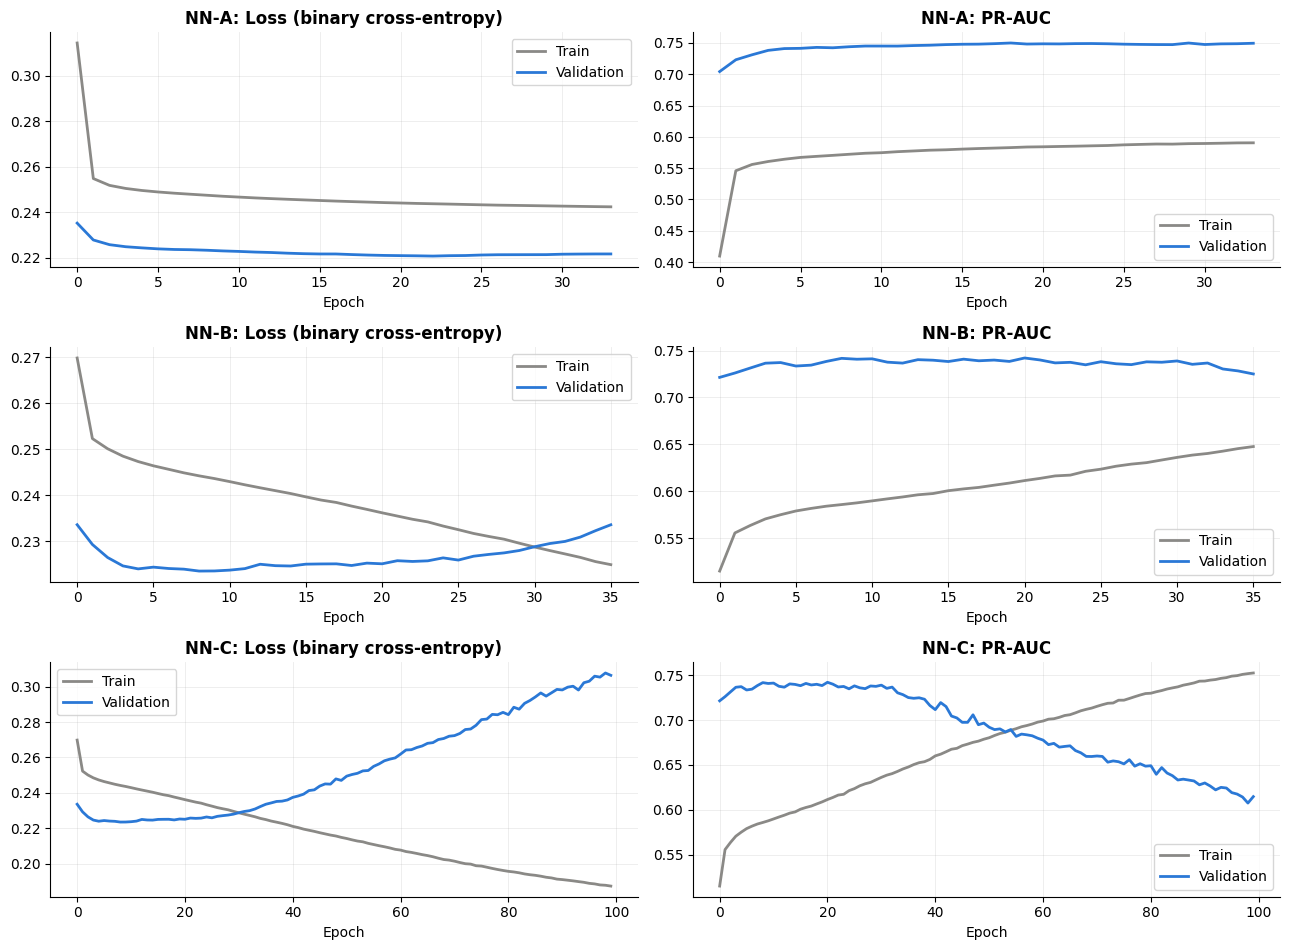

In [60]:
# Training curves: loss and PR-AUC per epoch, train vs validation
fig, axes = plt.subplots(len(NN_RUNS), 2, figsize=(13, 3.2 * len(NN_RUNS)))
for row, name in enumerate(NN_RUNS):
    h = nn_history[name]
    for col, (key, label) in enumerate([("loss", "Loss (binary cross-entropy)"), ("pr_auc", "PR-AUC")]):
        ax = axes[row, col]
        ax.plot(h[key], color=GRAY, label="Train"); ax.plot(h["val_" + key], color=BLUE, label="Validation")
        ax.set_title(f"{name}: {label}"); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

**Reading the curves:**
- **NN-A and NN-B (early stopping):** the validation score levels off after a few epochs; training stops 15 epochs after its best epoch
  (34 and 36 epochs) and the best weights are restored. The bigger network (NN-B) does not do better on validation (0.743 vs 0.750).
- **NN-C (no early stopping):** the **training** loss keeps falling and the training PR-AUC keeps rising (to 0.755), while the **validation** loss
  turns **upwards** and the validation PR-AUC falls to 0.621: the network memorises the training races instead of learning general patterns.
  This is overfitting, and early stopping prevents it.
- The training curves sit **below** the validation curves for the same reason as in Section 19: the training seasons include eras that are
  harder to predict.

## 22. All modeling attempts

Every model and setting we tried, scored on the training and validation seasons only (the test seasons are still untouched).
The table keeps every attempt (18 in total) so each choice can be checked.

In [61]:
attempts = pd.DataFrame(ATTEMPTS)
attempts["gap (train − validation)"] = attempts["train PR-AUC"] - attempts["validation PR-AUC"]
chosen = {"Baseline": "logistic regression, grid_pos only", "Logistic regression": f"C = {best_C}",
          "Random forest": f"max_depth = {best_rf[0]}, min_samples_leaf = {best_rf[1]}"}
attempts["chosen"] = [("✅" if chosen.get(m) == s or (m == "Neural network" and s.startswith(best_nn)) else "")
                      for m, s in zip(attempts["model"], attempts["setting"])]
print(f"{len(attempts)} attempts in total")
attempts.style.format({"train PR-AUC": "{:.3f}", "validation PR-AUC": "{:.3f}", "gap (train − validation)": "{:+.3f}"}).hide(axis="index")

18 attempts in total


model,setting,train PR-AUC,validation PR-AUC,gap (train − validation),chosen
Baseline,"logistic regression, grid_pos only",0.499,0.639,-0.139,✅
Logistic regression,C = 0.01,0.567,0.713,-0.146,
Logistic regression,C = 0.1,0.571,0.716,-0.145,
Logistic regression,C = 1,0.571,0.717,-0.146,
Logistic regression,C = 10,0.571,0.717,-0.146,✅
Random forest,"max_depth = 4, min_samples_leaf = 1",0.587,0.720,-0.133,
Random forest,"max_depth = 4, min_samples_leaf = 10",0.587,0.721,-0.135,
Random forest,"max_depth = 6, min_samples_leaf = 1",0.629,0.720,-0.091,
Random forest,"max_depth = 6, min_samples_leaf = 10",0.621,0.728,-0.107,✅
Random forest,"max_depth = 8, min_samples_leaf = 1",0.710,0.714,-0.004,


## 23. Final comparison: train, validation and the unseen test seasons

The four chosen models are now scored on all three splits with all metrics. Each model's threshold is the one chosen on the validation
seasons (Section 17). **This is the first and only time the test seasons are used.**

In [62]:
FINAL = {"Baseline (grid only)": (baseline, BASE_COLS), "Logistic regression": (log_reg, ALL_INPUTS),
         "Random forest": (forest, ALL_INPUTS), f"Neural network ({best_nn})": (neural_net, ALL_INPUTS)}
proba = {name: {s: predict_proba(m, cols, s) for s in SPLITS} for name, (m, cols) in FINAL.items()}
threshold = {name: choose_threshold(y["validation"], proba[name]["validation"]) for name in FINAL}

rows = []
for name in FINAL:
    for s in SPLITS:
        rows.append({"model": name, "split": s, "threshold": threshold[name], **all_scores(y[s], proba[name][s], threshold[name])})
comparison = pd.DataFrame(rows)
best_model_name = comparison[comparison["split"] == "validation"].set_index("model")["PR-AUC"].idxmax()
print("Best model on the validation seasons (primary metric PR-AUC):", best_model_name)
comparison.style.format({c: "{:.3f}" for c in ["threshold", "ROC-AUC", "PR-AUC", "F1", "precision", "recall"]}).hide(axis="index")

Best model on the validation seasons (primary metric PR-AUC): Neural network (NN-A)


model,split,threshold,ROC-AUC,PR-AUC,F1,precision,recall
Baseline (grid only),train,0.433,0.884,0.499,0.544,0.546,0.543
Baseline (grid only),validation,0.433,0.909,0.639,0.692,0.692,0.692
Baseline (grid only),test,0.433,0.914,0.647,0.649,0.650,0.647
Logistic regression,train,0.248,0.900,0.571,0.586,0.490,0.729
Logistic regression,validation,0.248,0.927,0.717,0.705,0.645,0.778
Logistic regression,test,0.248,0.933,0.715,0.672,0.550,0.863
Random forest,train,0.320,0.910,0.621,0.606,0.551,0.674
Random forest,validation,0.320,0.929,0.728,0.699,0.659,0.744
Random forest,test,0.320,0.939,0.705,0.668,0.577,0.794
Neural network (NN-A),train,0.470,0.908,0.596,0.550,0.606,0.504


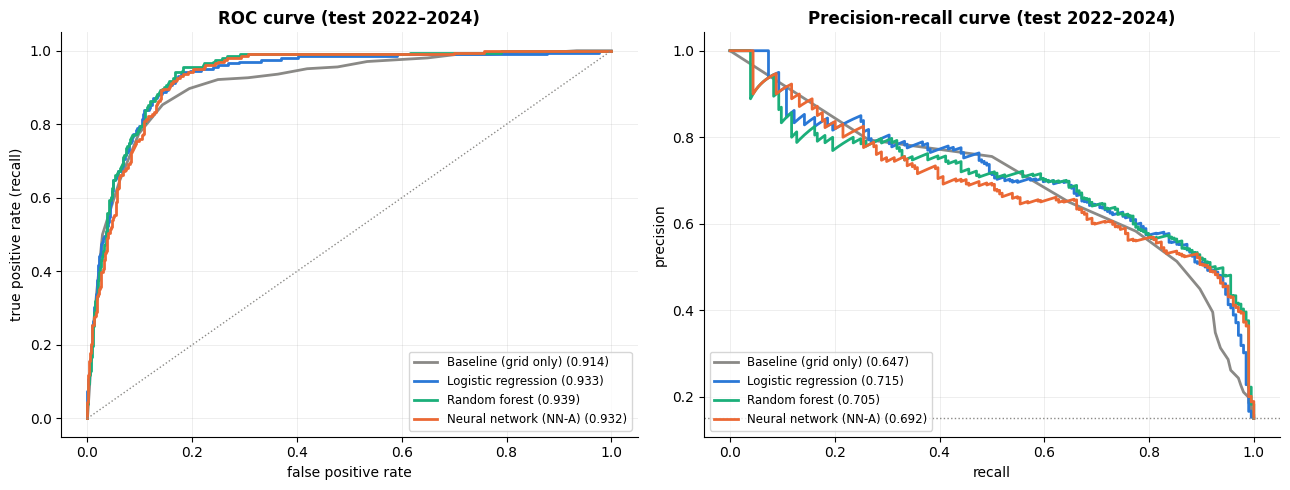

In [63]:
# ROC and precision-recall curves on the test seasons
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = [GRAY, BLUE, AQUA, ORANGE]
for (name, color) in zip(FINAL, colors):
    fpr, tpr, _ = roc_curve(y["test"], proba[name]["test"])
    prec, rec, _ = precision_recall_curve(y["test"], proba[name]["test"])
    axes[0].plot(fpr, tpr, color=color, label=f"{name} ({roc_auc_score(y['test'], proba[name]['test']):.3f})")
    axes[1].plot(rec, prec, color=color, label=f"{name} ({average_precision_score(y['test'], proba[name]['test']):.3f})")
axes[0].plot([0, 1], [0, 1], color=GRAY, ls=":", lw=1)
axes[0].set_title("ROC curve (test 2022–2024)"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate (recall)")
axes[1].axhline(y["test"].mean(), color=GRAY, ls=":", lw=1)
axes[1].set_title("Precision-recall curve (test 2022–2024)"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
for ax in axes: ax.legend(fontsize=8.5, loc="lower left" if ax is axes[1] else "lower right")
plt.tight_layout(); plt.show()

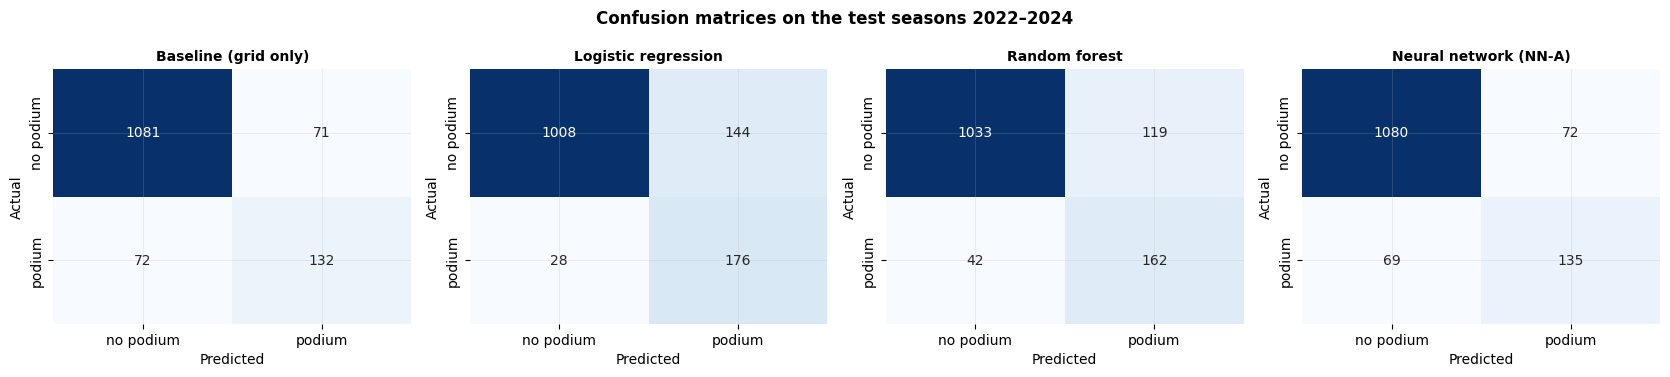

In [64]:
# Confusion matrices on the test seasons
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, len(FINAL), figsize=(4.2 * len(FINAL), 3.8))
for ax, name in zip(axes, FINAL):
    cm = confusion_matrix(y["test"], (proba[name]["test"] >= threshold[name]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no podium", "podium"], yticklabels=["no podium", "podium"])
    ax.set_title(name, fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion matrices on the test seasons 2022–2024", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading the comparison:**
- **Every model beats the baseline.** On the test seasons, PR-AUC rises from **0.647** (grid only) to **0.692–0.715**: the form, standings and team
  features add real information beyond the starting position.
- **Validation picks the neural network** (PR-AUC 0.750, ahead of the random forest at 0.728 and logistic regression at 0.717), so by our rule
  it is the chosen model. **On the test seasons the order reverses:** logistic regression 0.715, random forest 0.705, neural network 0.692.
  Two reasons the network's lead did not carry over: the validation seasons contain only 117 podiums, and the network's validation score is
  slightly optimistic, because early stopping also used the validation seasons to pick its epoch. We do **not**
  switch models after seeing the test result (that would use the test set for a choice); we report it as it is. The most **stable** model is
  logistic regression: almost the same score on validation (0.717) and test (0.715).
- **Different thresholds, different trade-offs** (all fixed on validation):
  - Logistic regression (threshold 0.25) favours **catching podiums**: it finds 86% of the podium finishers (recall 0.86) with precision 0.55,
    and has the highest test F1 (0.672).
  - The random forest (0.32) is in the middle: recall 0.79, precision 0.58.
  - The neural network (0.47) is the most **cautious**: fewer false alarms (precision 0.65) but it misses more podiums (recall 0.66).
- **Confusion matrices**, out of the 204 real podium finishers in 2022–2024:

  | Model | Podiums caught | Missed | False alarms |
  |---|---|---|---|
  | Baseline | 132 | 72 | 71 |
  | Logistic regression | 176 | 28 | 144 |
  | Random forest | 162 | 42 | 119 |
  | Neural network | 135 | 69 | 72 |

## 24. Limitations of the models

- **Era sensitivity:** the models learn from 1950–2019 and are tested on a new rule era (2022–2024). All three full models score lower on the test seasons than on validation,
  and a future rule change could hurt them again. Retraining on the newest seasons would be needed in practice.
- **One driver at a time:** each driver gets his own probability, without knowing that a race has exactly three podiums. The probabilities of
  one race do not add up to 3, and in a race with several strong cars the model may call more than three drivers "podium".
- **Small validation set:** 2020–2021 contain only 117 podiums, so validation scores are noisy. The clearest example: the neural network led
  on validation by 0.022–0.033 PR-AUC but finished last of the three full models on test. Its validation score is also slightly
  optimistic, because early stopping used the validation seasons to pick the epoch.
- **Old seasons are incomplete:** training uses 1950–2019, but qualifying times exist only from 1994 and team standings only from 1958. The
  flags let the models use these seasons, but for 64% of training rows the model learns without the qualifying signal.
- **Information the data does not have:** weather, tyre strategy, safety cars, crashes and in-race failures decide many podiums and are
  unknown before the start. This puts a ceiling on how well any pre-race model can do.
- **Logistic regression** can only add effects up; it cannot learn combinations (e.g. "a front-row start matters more in a fast car") unless
  they are built as features. **Random forest** overfits quickly when its trees get deeper (Section 20). **The neural network** needs early
  stopping to avoid memorising the training races (Section 21) and changes slightly with the random start (fixed here with a seed).

# Part 5: Experiments

The experiment is a **feature-group ablation**: Part 3 (Section 12) justified each feature **before** training with evidence; the
ablation measures each group's **actual contribution after** training. (The preprocessing-order experiments are in Section 16.)

## 25. Feature-group ablation

**What it is:** we remove **one group of features at a time**, retrain the chosen model with exactly the same settings, and measure how much
the score **drops**. A big drop means the model really needs that group; a drop near zero means the other groups already carry its information.
The three missing-value flags go with their group (`no_quali_time` with qualifying, `first_circuit_visit` with circuit, `no_team_standings` with standings).
The drop is measured on the validation seasons; the test drop is shown next to it as a check (it is not used to choose anything).

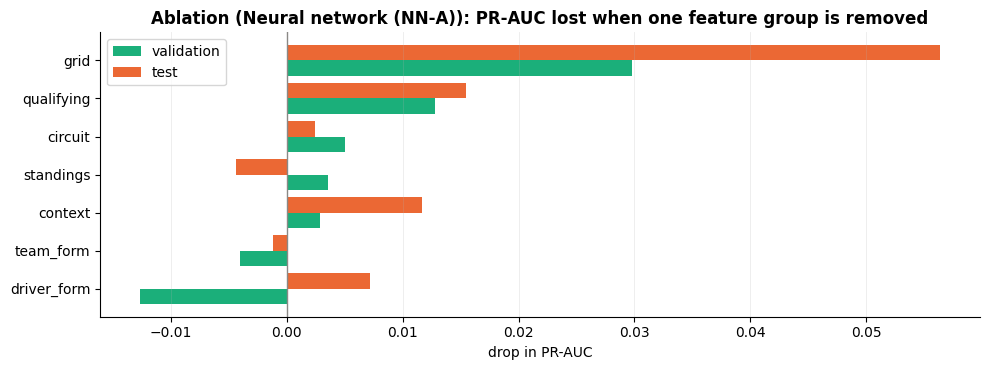

Full model: validation PR-AUC 0.750 | test PR-AUC 0.692


group removed,inputs removed,validation PR-AUC,drop (validation),test PR-AUC,drop (test)
grid,1,0.720,0.030,0.635,0.056
qualifying,2,0.737,0.013,0.676,0.015
circuit,2,0.745,0.005,0.689,0.002
standings,7,0.747,0.004,0.696,-0.004
context,1,0.747,0.003,0.680,0.012
team_form,3,0.754,-0.004,0.693,-0.001
driver_form,2,0.763,-0.013,0.684,0.007


In [65]:
FLAG_GROUP = {"no_quali_time": "qualifying", "first_circuit_visit": "circuit", "no_team_standings": "standings"}
ABLATION_GROUPS = {g: fs + [f for f, fg in FLAG_GROUP.items() if fg == g] for g, fs in FEATURE_GROUPS.items()}
assert sorted(sum(ABLATION_GROUPS.values(), [])) == sorted(ALL_INPUTS)

def refit_chosen(cols):
    # retrain the chosen model type with the same settings on a reduced set of inputs
    if best_model_name == "Logistic regression":
        return LogisticRegression(max_iter=1000, C=best_C).fit(X["train"][cols], y["train"])
    if best_model_name == "Random forest":
        return RandomForestClassifier(n_estimators=300, max_depth=best_rf[0], min_samples_leaf=best_rf[1],
                                      random_state=RANDOM_STATE, n_jobs=-1).fit(X["train"][cols], y["train"])
    hidden, _, _ = NN_RUNS[best_nn]
    keras.utils.set_random_seed(RANDOM_STATE)
    m = keras.Sequential([layers.Input(shape=(len(cols),))] + [layers.Dense(n, activation="relu") for n in hidden]
                         + [layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
    m.fit(X["train"][cols].to_numpy(), y["train"], validation_data=(X["validation"][cols].to_numpy(), y["validation"]),
          epochs=200, batch_size=32, verbose=0,
          callbacks=[EarlyStopping(monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True)])
    return m

full = {s: average_precision_score(y[s], proba[best_model_name][s]) for s in ["validation", "test"]}
abl = []
for group, cols_out in ABLATION_GROUPS.items():
    cols = [c for c in ALL_INPUTS if c not in cols_out]
    m = refit_chosen(cols)
    scores_ = {s: average_precision_score(y[s], predict_proba(m, cols, s)) for s in ["validation", "test"]}
    abl.append({"group removed": group, "inputs removed": len(cols_out),
                "validation PR-AUC": scores_["validation"], "drop (validation)": full["validation"] - scores_["validation"],
                "test PR-AUC": scores_["test"], "drop (test)": full["test"] - scores_["test"]})
ablation = pd.DataFrame(abl).sort_values("drop (validation)", ascending=False)

fig, ax = plt.subplots(figsize=(10, 3.8))
yy = np.arange(len(ablation))
ax.barh(yy + 0.2, ablation["drop (validation)"], 0.4, color=AQUA, label="validation")
ax.barh(yy - 0.2, ablation["drop (test)"], 0.4, color=ORANGE, label="test")
ax.set_yticks(yy); ax.set_yticklabels(ablation["group removed"]); ax.invert_yaxis()
ax.axvline(0, color=GRAY, lw=1); ax.legend(); ax.grid(axis="y", visible=False)
ax.set_title(f"Ablation ({best_model_name}): PR-AUC lost when one feature group is removed"); ax.set_xlabel("drop in PR-AUC")
plt.tight_layout(); plt.show()
print(f"Full model: validation PR-AUC {full['validation']:.3f} | test PR-AUC {full['test']:.3f}")
ablation.style.format({c: "{:.3f}" for c in ablation.columns if c not in ["group removed", "inputs removed"]}).hide(axis="index")

**Reading the ablation** (chosen model: the neural network, retrained once per group):
- **Grid is by far the most important group:** without it, validation PR-AUC drops by **0.030** and test PR-AUC by **0.056**.
- **Qualifying is second:** a smaller drop, but in the same direction on both (0.013 validation, 0.015 test).
- **Circuit, standings, context, team form and driver form** show no consistent effect: small changes in **both** directions (driver form even
  scores higher without it on validation, −0.013, but lower on test, +0.007). With 117 validation podiums and a network that changes slightly
  every time it is retrained, differences below about 0.01 are noise.
- This does **not** mean those groups carry no information (Section 12 showed driver form is strongly linked to podiums). It means the **other
  groups already contain it**: a driver in form is usually also high in the standings and in a fast team (correlation about 0.8). Remove one
  of them and the others fill in. Ablation measures what a group adds **on top of the others**; Section 12 measured each feature **on its own**.

# Part 6: Explainability (XAI)

We explain the **chosen model** (Section 23) on the **test seasons** (2022–2024). Nothing here changes the model or any choice;
the explanations only describe what the trained model does.

**Which kind of XAI:**
- Logistic regression is **intrinsically interpretable**: each input has one weight, so its weights already explain it. Our chosen model is a
  **neural network**, a **black box**: its weights do not tell us directly why it predicts a podium.
- So we use **post-hoc, model-agnostic** methods: they are applied **after** training and use only the model's **inputs and outputs**, not
  its inside. All three methods below are of this kind (permutation importance, SHAP, LIME).
- **Global** explanations show how the model works **overall** (Sections 26–27); **local** explanations show why **one** prediction was made
  (Section 28).

| Section | Question | Method |
|---|---|---|
| 26 | Which inputs does the model rely on **overall**? | permutation importance |
| 27 | Same question, and in **which direction** does each input push? | SHAP (global) |
| 28 | Why did the model give **one specific driver** his probability? | local SHAP (force and waterfall plots) and LIME |
| 29 | What these explanations do **not** mean | importance ≠ cause |

**Real units:** the model works on scaled inputs (Section 15). To keep the explanations readable ("grid = 19", not "grid = 1.7"), the
explainers work on the inputs **after filling, before scaling**, through one function that scales and then asks the model.
This is exactly the same model and gives exactly the same probabilities (checked below).

In [66]:
import subprocess, sys
for package, module in [("shap", "shap"), ("lime", "lime")]:
    try:
        __import__(module)
    except ImportError:                                   # usually pre-installed on Kaggle; install only if missing
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)
import shap
from lime.lime_tabular import LimeTabularExplainer

xai_model, xai_cols = FINAL[best_model_name]
assert xai_cols == prep["columns"]                        # the chosen model uses all 18 inputs, in the preprocessing order

def model_prob(X_processed):
    # podium probability from already-processed (flagged, filled, scaled) inputs
    if isinstance(xai_model, keras.Model):
        return np.asarray(xai_model(X_processed[xai_cols].to_numpy(dtype="float32"), training=False)).ravel()
    return xai_model.predict_proba(X_processed[xai_cols])[:, 1]

def podium_prob_raw(raw):
    # podium probability from inputs in real units (flagged + filled, NOT scaled): scale with the training scaler, then predict
    raw = pd.DataFrame(np.asarray(raw, dtype=float), columns=xai_cols)
    return model_prob(pd.DataFrame(prep["scaler"].transform(raw), columns=xai_cols))

# inputs in real units: flags added, gaps filled with the TRAINING medians (exactly Section 15, without the scaling step)
X_filled = {s: add_flags(X_raw[s]).fillna(prep["medians"])[xai_cols] for s in X_raw}
p_test = podium_prob_raw(X_filled["test"])
assert np.allclose(p_test, proba[best_model_name]["test"], atol=1e-5)
print(f"Explaining: {best_model_name} | {len(p_test)} test rows | same probabilities as Section 23 ✅")

Explaining: Neural network (NN-A) | 1356 test rows | same probabilities as Section 23 ✅


## 26. Global explanation 1: permutation importance

**Idea:** take one input and **shuffle** its values between the test drivers (so it no longer belongs to the right driver), keep everything else,
and measure how much PR-AUC drops. If the model relies on that input, the score drops a lot; if not, it hardly changes.
We shuffle each input **10 times** and show the average drop and the range (smallest to largest drop).

**Difference from the ablation (Section 25):** the ablation **retrains** without a group, so the other features can take over. Permutation
importance keeps the **trained model** and asks: *how much does this model use this input?*

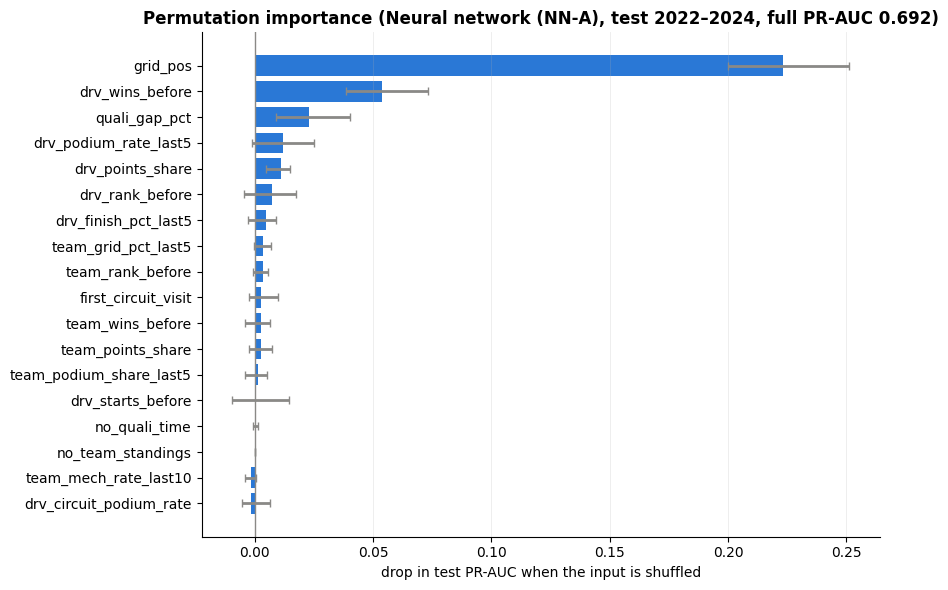

input,mean drop,smallest drop,largest drop
grid_pos,0.2232,0.1999,0.2512
drv_wins_before,0.0536,0.0387,0.0732
quali_gap_pct,0.0228,0.0090,0.0403
drv_podium_rate_last5,0.0120,-0.0011,0.0251
drv_points_share,0.0112,0.0046,0.0149
drv_rank_before,0.0074,-0.0046,0.0172
drv_finish_pct_last5,0.0046,-0.0028,0.0091
team_grid_pct_last5,0.0035,-0.0003,0.0070
team_rank_before,0.0033,-0.0010,0.0054
first_circuit_visit,0.0028,-0.0023,0.0096


In [67]:
rng = np.random.default_rng(RANDOM_STATE)
full_score = average_precision_score(y["test"], p_test)
N_REPEATS = 10
rows = []
for col in xai_cols:
    drops = []
    for _ in range(N_REPEATS):
        shuffled = X_filled["test"].copy()
        shuffled[col] = rng.permutation(shuffled[col].to_numpy())
        drops.append(full_score - average_precision_score(y["test"], podium_prob_raw(shuffled)))
    rows.append({"input": col, "mean drop": np.mean(drops), "smallest drop": np.min(drops), "largest drop": np.max(drops)})
perm_imp = pd.DataFrame(rows).sort_values("mean drop", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(perm_imp))
ax.barh(yy, perm_imp["mean drop"], color=BLUE)
ax.errorbar(perm_imp["mean drop"], yy, xerr=[perm_imp["mean drop"] - perm_imp["smallest drop"],
                                             perm_imp["largest drop"] - perm_imp["mean drop"]], fmt="none", ecolor=GRAY, capsize=3)
ax.set_yticks(yy); ax.set_yticklabels(perm_imp["input"]); ax.invert_yaxis(); ax.axvline(0, color=GRAY, lw=1)
ax.set_xlabel("drop in test PR-AUC when the input is shuffled"); ax.grid(axis="y", visible=False)
ax.set_title(f"Permutation importance ({best_model_name}, test 2022–2024, full PR-AUC {full_score:.3f})")
plt.tight_layout(); plt.show()
perm_imp.style.format({c: "{:.4f}" for c in ["mean drop", "smallest drop", "largest drop"]}).hide(axis="index")

**Reading the result:**
- **`grid_pos` is by far the most used input:** shuffling it costs about 0.2 PR-AUC, several times more than any other input.
- **Next:** `drv_wins_before` (wins this season), then `quali_gap_pct` and `drv_podium_rate_last5`: the model uses **speed on the day** and
  **recent success**.
- **The rest** cost about 0.01 or less each, and many ranges cross 0: the model uses them only a little, or they share their information
  with other inputs (e.g. driver points share, rank and wins say almost the same thing).
- **The flags are close to 0** here, as expected: in the test seasons almost every driver has a qualifying time (99%) and every team has
  standings, so the flags hardly change between drivers. `no_team_standings` is 0 for every test row, so shuffling it changes nothing.
- **Compared with the ablation:** driver wins matter here but the standings group barely mattered in the ablation. Both are right: *this* model
  relies on wins, but a model retrained **without** standings can get the same information from form and grid.

## 27. Global explanation 2: SHAP

**Idea ("sharing the prize"):** think of the inputs of one driver as **players in a team** and the predicted probability as the
**prize** they win together. SHAP divides the prize fairly between the players: it compares the prediction **with and without** each input,
over many combinations of the other inputs, and gives each input its average share. The shares add up exactly to the prediction:

*prediction = average prediction + contribution of grid + contribution of wins + …*

- The **average prediction** is the model's average probability over a **reference group** of drivers.
- A contribution of **+0.10** means "this input moved this driver's probability **up** by 10 percentage points compared with the reference".

**Reference group:** 100 random driver-races from the **last ten training seasons (2010–2019)**. If we used all 1950–2019 rows, most of the
reference drivers would have no qualifying time, and the flags would look important just because the test drivers *have* one. A modern
reference makes the contributions mean "compared with a typical recent driver".

**Global view:** we compute the contributions for **every test driver** and plot:
- **bar chart:** the average size of each input's contribution (how much it moves predictions, in either direction);
- **beeswarm:** one dot per driver; position = contribution, colour = the input's value (red = high, blue = low).

Average prediction of the reference group: 0.182


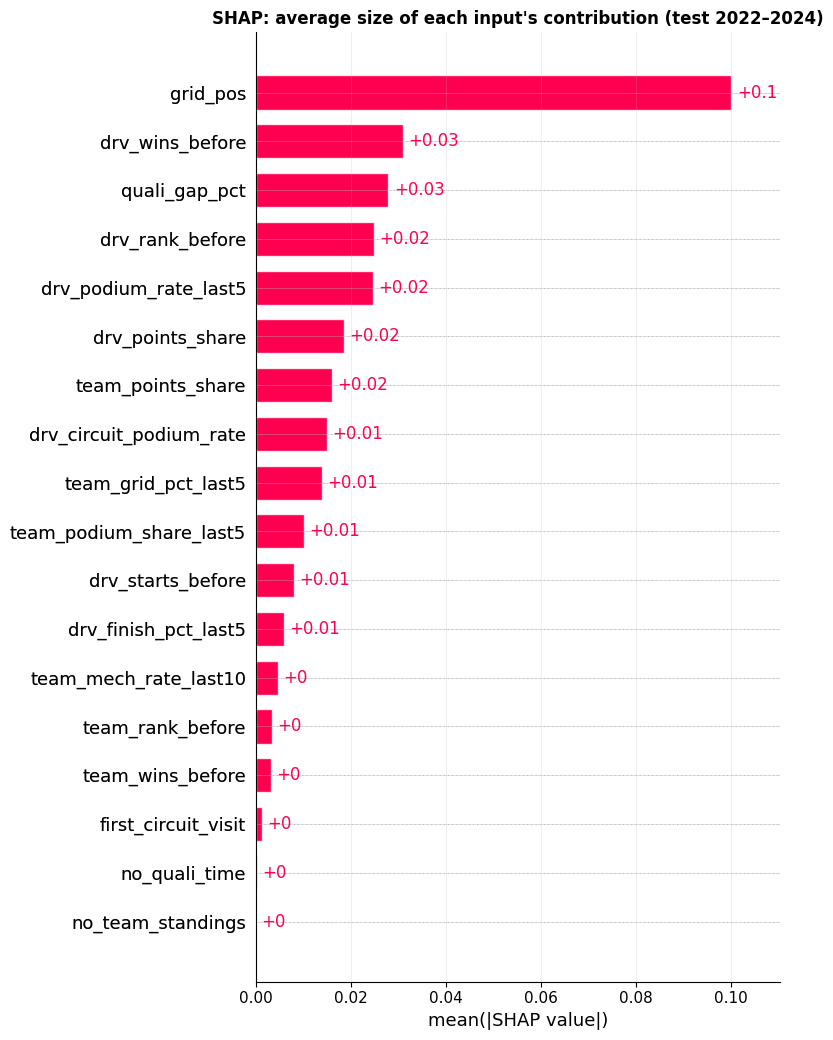

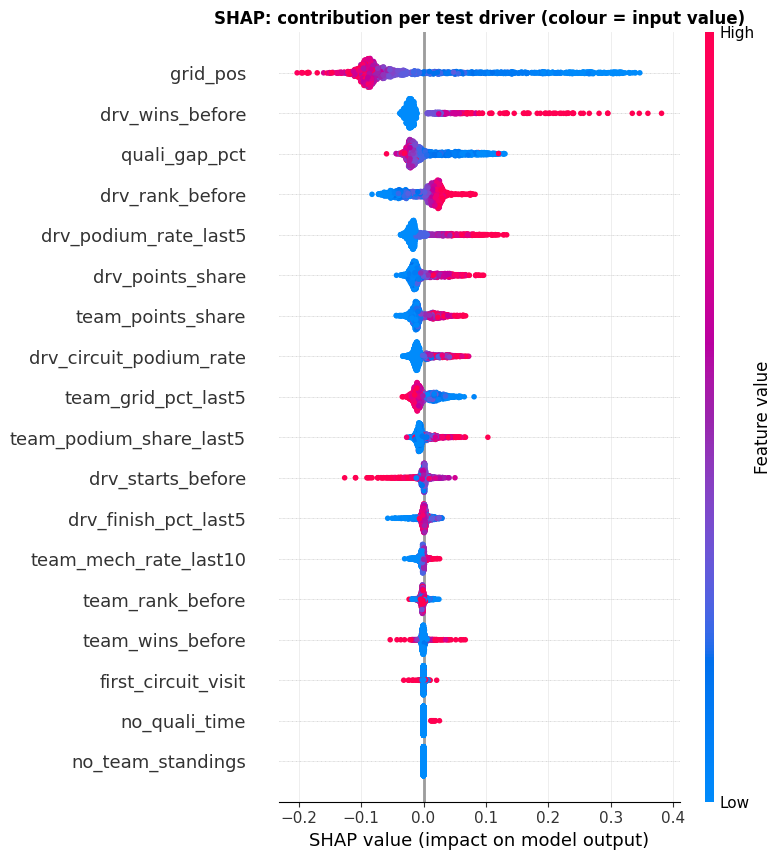

In [68]:
recent_train = X_filled["train"][mt.loc[X_filled["train"].index, "year"] >= 2010]
background = recent_train.sample(100, random_state=RANDOM_STATE)
explainer = shap.Explainer(podium_prob_raw, shap.maskers.Independent(background, max_samples=100),
                           algorithm="permutation", seed=RANDOM_STATE)
shap_test = explainer(X_filled["test"], max_evals=2 * len(xai_cols) * 5 + 1, silent=True)

# check: average prediction + all contributions = the model's probability, for every driver
assert np.allclose(shap_test.base_values + shap_test.values.sum(axis=1), p_test, atol=1e-4)
print(f"Average prediction of the reference group: {shap_test.base_values[0]:.3f}")

shap.plots.bar(shap_test, max_display=len(xai_cols), show=False)
plt.title("SHAP: average size of each input's contribution (test 2022–2024)"); plt.tight_layout(); plt.show()
shap.plots.beeswarm(shap_test, max_display=len(xai_cols), show=False)
plt.title("SHAP: contribution per test driver (colour = input value)"); plt.tight_layout(); plt.show()

**Reading the plots:**
- **Same top three as permutation importance:** `grid_pos` moves predictions the most (about 0.10 on average), followed by
  `drv_wins_before` and `quali_gap_pct` (about 0.03 each), then the driver's standings and recent podium rate (about 0.02). Two different
  methods agree on the top of the ranking, which makes it more trustworthy.
- **Directions (beeswarm) match F1 sense:**
  - `grid_pos`: **blue** (front of the grid) on the right = higher probability; **red** (back) on the left. Starting at the front can add
    up to about +0.35.
  - `drv_wins_before` and `drv_podium_rate_last5`: **red** (many wins / podiums) on the right.
  - `quali_gap_pct` and `team_grid_pct_last5`: **blue** (fast in qualifying / a fast car) on the right.
- **Small, odd directions:** for a few overlapping inputs the colours point the "wrong" way (e.g. a **worse** championship rank, or **more**
  team wins, nudging the probability slightly in the unexpected direction). These inputs say almost the same thing as points share and wins, so
  the model spreads the credit between them and uses some as small corrections. **Read the main inputs; do not read the sign of each
  overlapping input on its own.** This is one more reason why importance is not cause (Section 29).
- The flags are near 0 for the same reason as in Section 26: in the test seasons they are almost always 0.

## 28. Local explanations: why did the model say this for one driver?

Two drivers from the test seasons, chosen by a **fixed rule** (not by looking at the model's answers):
- **Case 1:** the **pole sitter of the first test race** (Bahrain 2022), an "expected" podium.
- **Case 2:** the podium finisher who **started furthest back** in 2022–2024, a "surprise" podium.

For each we show:
- **local SHAP, force plot:** red inputs push the probability **up**, blue inputs push it **down**; where they meet is this driver's
  probability (bold number), starting from the reference average ("base value");
- **local SHAP, waterfall plot:** the same contributions as a list, starting at the reference average (bottom) and adding one input at a
  time until it reaches this driver's probability (top);
- **LIME:** creates many **perturbations** of this driver (copies with some inputs randomly changed), asks the neural network for their
  probabilities, and fits a simple **surrogate** model (a straight line) to those answers. Its weights show which conditions push towards
  "podium" (right, green) or "no podium" (left, red) **around this one driver**.

Case 1: Charles Leclerc, Bahrain Grand Prix 2022: qualified P1, started P1, finished P1
        model: podium probability 0.60 -> podium (threshold 0.47)


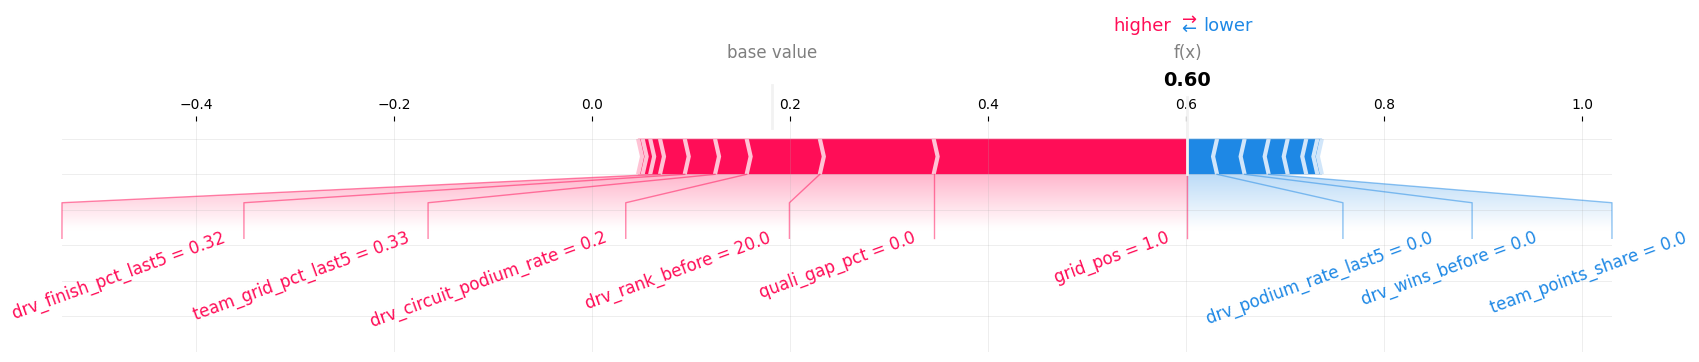

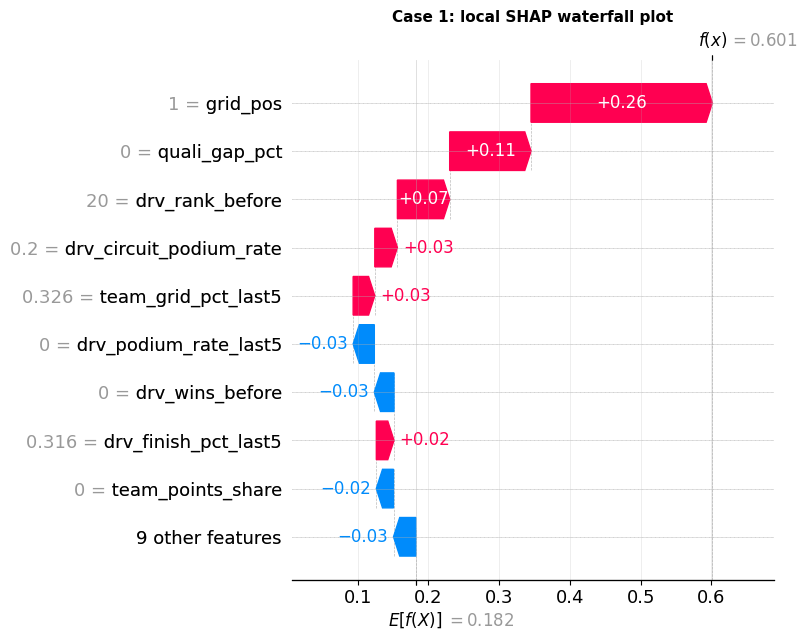

Case 2: Charles Leclerc, Abu Dhabi Grand Prix 2024: qualified P14, started P19, finished P3
        model: podium probability 0.13 -> no podium (threshold 0.47)


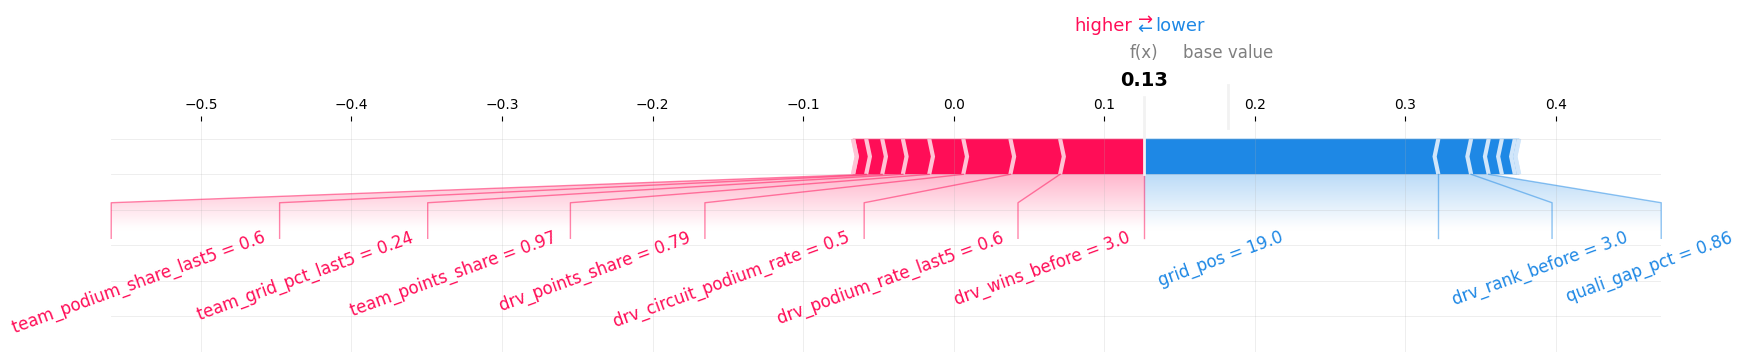

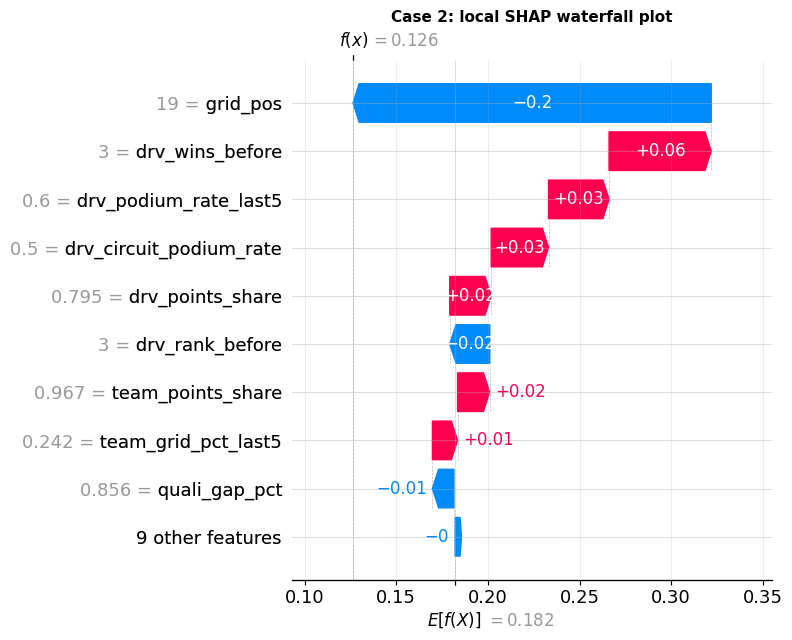

In [69]:
te_rows = mt.loc[X_filled["test"].index]
driver_names = CLEAN["drivers"].set_index("driverId")
row_pos = {idx: i for i, idx in enumerate(X_filled["test"].index)}
THR = threshold[best_model_name]

def describe(idx):
    r = te_rows.loc[idx]; d = driver_names.loc[r["driverId"]]
    return (f'{d["forename"]} {d["surname"]}, {r["name"]} {int(r["year"])}: qualified P{int(r["quali_pos"])}, '
            f'started P{int(r["grid_pos"])}, finished P{int(r["positionOrder"])}')

first_race = te_rows[te_rows["race_index"] == te_rows["race_index"].min()]
podium_rows = te_rows[te_rows["podium"] == 1]
CASES = {"Case 1": first_race.index[first_race["grid_pos"] == 1][0],      # pole sitter of the first test race
         "Case 2": podium_rows["grid_pos"].idxmax()}                       # podium finisher who started furthest back

for name, idx in CASES.items():
    p = p_test[row_pos[idx]]
    print(f"{name}: {describe(idx)}")
    print(f"        model: podium probability {p:.2f} -> {'podium' if p >= THR else 'no podium'} (threshold {THR:.2f})")
    shap.force_plot(shap_test.base_values[row_pos[idx]], shap_test.values[row_pos[idx]],
                    X_filled["test"].loc[idx].round(2), matplotlib=True, show=False, text_rotation=20)
    plt.show()                                             # force plot (the case is named in the line printed above)
    shap.plots.waterfall(shap_test[row_pos[idx]], max_display=10, show=False)
    plt.title(f"{name}: local SHAP waterfall plot", fontsize=11); plt.tight_layout(); plt.show()

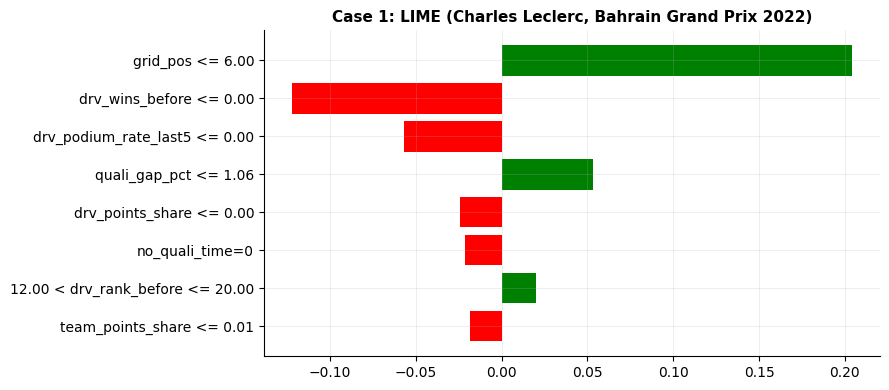

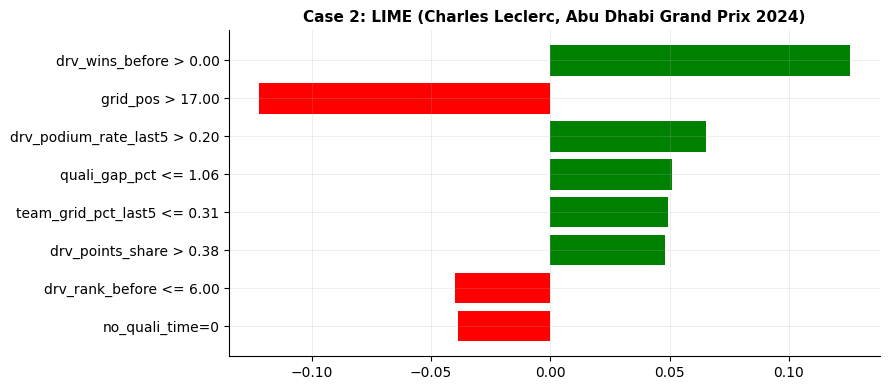

In [70]:
flag_positions = [xai_cols.index(f) for f in FLAGS]
lime_explainer = LimeTabularExplainer(recent_train.to_numpy(), feature_names=xai_cols, class_names=["no podium", "podium"],
                                      categorical_features=flag_positions, mode="classification", random_state=RANDOM_STATE)
lime_predict = lambda a: np.column_stack([1 - podium_prob_raw(a), podium_prob_raw(a)])   # LIME expects one column per class

for name, idx in CASES.items():
    exp = lime_explainer.explain_instance(X_filled["test"].loc[idx].to_numpy(), lime_predict, num_features=8, num_samples=5000)
    fig = exp.as_pyplot_figure(); fig.set_size_inches(9, 4)
    plt.title(f"{name}: LIME ({describe(idx).split(':')[0]})", fontsize=11); plt.tight_layout(); plt.show()

**Reading the local explanations:**

**Case 1: Charles Leclerc, Bahrain 2022 (pole, won).** The model gives about **0.6**, a podium call.
- **Pushing up:** pole position (`grid_pos` = 1) and the fastest qualifying lap (`quali_gap_pct` = 0). These are by far the largest contributions.
- **Pushing down:** this is **round 1** of the season, so the standings are all zero (no wins, no points yet), and his last five races of
  2021 had no podium (`drv_podium_rate_last5` = 0).
- **So:** the model trusts the grid and the lap time over the weak form. SHAP and LIME agree on these factors.

**Case 2: Charles Leclerc, Abu Dhabi 2024 (qualified 14th, started 19th after a grid penalty, finished 3rd).** The model gives about **0.13**,
below the threshold, so it **missed** this podium.
- **Pushing up:** strong form: 3 wins that season, podiums in 3 of his last 5 races, past podiums at this circuit, and a fast car
  (`team_grid_pct_last5`).
- **Pushing down:** starting **19th**, a contribution of about **−0.20**, more than all his positive factors together (about +0.17), so
  the probability ends **below** the reference average.
- **So:** the model does not know that a fast car starting at the back can **overtake** many cars; in its training data a start from P19
  almost never ends on the podium. This is the "information the data does not have" limitation (Section 24) seen in one race.

The **two methods agree** on the main reasons in both cases. They differ in the details because they answer slightly different questions
(SHAP: contribution compared with the reference group; LIME: effect of small changes around this one driver). For example, LIME also shows a small
minus for `no_quali_time=0`: it comes from LIME's own variations (it tries versions of the driver **with** the flag switched on), not from
anything about this driver, who has a real qualifying time.

## 29. Important: importance is not cause

The explanations above show **what the model relies on**, not **what causes a podium**:

- **`drv_wins_before` is important, but wins do not cause podiums.** A fast car and a good driver cause **both** the earlier wins **and** the
  next podium. The model uses wins because they are a good sign of a fast car, not because winning more makes the next race easier.
- **`grid_pos` is the strongest input, but starting at the front is not the whole cause either.** The car that starts at the front is usually
  also the fastest car; both the grid slot and the podium come largely from that speed.
- **Overlapping inputs share credit** (Section 27): when two inputs carry the same information, the model can rely on one and give the other a
  small or even opposite-looking effect. Neither tells us what would happen if we changed that input in real life.
- **Changing an input would not change the result.** The model says drivers with many points podium more often; giving a driver extra points
  would not make his car faster.

In short: a feature being important to the model is **not proof that it causes podium finishes**; it only means the model uses it to make
predictions.

# Part 7: Inference function

## 30. Predicting a podium for a new record

`predict_podium(record)` is how the chosen model would be used for a new race: give it the driver's pre-race values (after qualifying,
before the start) and it returns the podium probability and the yes/no decision.

**What it does, step by step:**
1. Checks the input names (an unknown name raises an error instead of being silently ignored).
2. Puts the record in the same column order as training; any input that is **missing** (left out, `None` or `NaN`) stays missing.
3. Applies **exactly the training preprocessing** (Section 15): the same flags, the **training medians** for the gaps and the **training
   scaler**. Nothing is re-learned from the new record.
4. Asks the chosen model for the probability and compares it with the **validation-chosen threshold** (Section 23).
5. Reports which inputs were missing and which value replaced them, so the user knows how much of the answer is based on filled values.

In [71]:
def predict_podium(record):
    """record: dict of pre-race features (names as in FEATURES). Any feature may be missing (left out, None or NaN)."""
    unknown = set(record) - set(FEATURES)
    if unknown:
        raise ValueError(f"Unknown inputs: {sorted(unknown)}. Expected some of: {FEATURES}")
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}], dtype=float)
    imputed = {f: round(float(prep["medians"][f]), 3) for f in FEATURES if pd.isna(row.at[0, f])}
    X_row = apply_preprocessing(prep, row)                 # same flags, training medians and scaler as in training
    p = float(model_prob(X_row)[0])
    return {"podium probability": round(p, 3),
            "prediction": "podium" if p >= THR else "no podium",
            "threshold": round(THR, 3),
            "missing inputs (filled with the training median)": imputed}

print("Expected inputs:", FEATURES)

Expected inputs: ['grid_pos', 'quali_gap_pct', 'drv_points_share', 'drv_rank_before', 'drv_wins_before', 'team_points_share', 'team_rank_before', 'team_wins_before', 'drv_podium_rate_last5', 'drv_finish_pct_last5', 'team_podium_share_last5', 'team_grid_pct_last5', 'team_mech_rate_last10', 'drv_circuit_podium_rate', 'drv_starts_before']


**Demo 1: a complete record.** Case 1 from Section 28 (Leclerc, Bahrain 2022): every input is known. The result must match the
probability the notebook computed for this row in Section 23.

In [72]:
complete_record = X_raw["test"].loc[CASES["Case 1"]].to_dict()
print(describe(CASES["Case 1"]))
display(pd.Series(complete_record, name="value").round(3).to_frame())
result = predict_podium(complete_record)
print(result)
assert abs(result["podium probability"] - p_test[row_pos[CASES["Case 1"]]]) < 1e-3     # same answer as the notebook pipeline

Charles Leclerc, Bahrain Grand Prix 2022: qualified P1, started P1, finished P1


,value
grid_pos,1.000
quali_gap_pct,0.000
drv_points_share,0.000
drv_rank_before,20.000
drv_wins_before,0.000
team_points_share,0.000
team_rank_before,10.000
team_wins_before,0.000
drv_podium_rate_last5,0.000
drv_finish_pct_last5,0.316


{'podium probability': 0.601, 'prediction': 'podium', 'threshold': 0.47, 'missing inputs (filled with the training median)': {}}


**Demo 2: a partially-missing record.** A real one from the test seasons: **Oliver Bearman's first Formula 1 race** (Saudi Arabia 2024,
as a stand-in driver). Because it is his debut, three inputs cannot exist: his recent podium rate, his recent finishing percentile and his
history at this circuit.

In [73]:
debuts = te_rows[te_rows["drv_starts_before"] == 0]
bearman = next(i for i in debuts.index if driver_names.loc[te_rows.loc[i, "driverId"], "surname"] == "Bearman")
partial_record = X_raw["test"].loc[bearman].to_dict()
print(describe(bearman))
display(pd.Series(partial_record, name="value").round(3).to_frame())
result = predict_podium(partial_record)
print(result)
assert abs(result["podium probability"] - p_test[row_pos[bearman]]) < 1e-3

Oliver Bearman, Saudi Arabian Grand Prix 2024: qualified P11, started P11, finished P7


,value
grid_pos,11.000
quali_gap_pct,1.338
drv_points_share,0.000
drv_rank_before,20.000
drv_wins_before,0.000
team_points_share,0.614
team_rank_before,2.000
team_wins_before,0.000
drv_podium_rate_last5,NaN
drv_finish_pct_last5,NaN


{'podium probability': 0.046, 'prediction': 'no podium', 'threshold': 0.47, 'missing inputs (filled with the training median)': {'drv_podium_rate_last5': 0.0, 'drv_finish_pct_last5': 0.508, 'drv_circuit_podium_rate': 0.0}}


**Reading the demos:**
- **Complete record:** the function returns the **same probability** as the notebook's own pipeline (checked with `assert`), so the
  inference path and the evaluation path are identical. No inputs were filled.
- **Partially-missing record:** the function still works. It reports the three missing inputs and the training medians that replaced them,
  and the `first_circuit_visit` flag is set automatically, exactly as during training. The probability is **low**: a debutant starting 11th, with
  no form of his own (he finished 7th). His team inputs (Ferrari, 2nd in the standings) are real values, not filled ones.
- **Why the report of filled inputs matters:** a prediction built on filled values is less certain than one built on real values; the user can
  see this instead of trusting the number blindly.